# 신약 후보물질 독성 예측 – 모델링

- 목표: `train.csv`로 학습 → `predict_input.csv`의 독성 예측 → `predict_output_김정인.csv` 제출
- 라벨: **1 = 독성 없음, 0 = 독성 있음**
- 평가지표: **라벨 0(독성 있음)의 F1-score** (`f1_score(..., pos_label=0)`)
- 진행: 공통 평가 함수 → 가설별 실험(E1~E6) → 제출 파일 생성
- 하이퍼파라미터 탐색 결과는 `optuna_tuning.db`에 저장되어, 다시 실행하면 **이어서** 탐색합니다.

In [1]:
import os, time, warnings, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from rdkit import Chem, RDLogger
from rdkit.Chem import rdFingerprintGenerator, Descriptors

import optuna
from sklearn.base import clone
from sklearn.model_selection import train_test_split, cross_validate, cross_val_score, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import RobustScaler
from sklearn.metrics import (f1_score, make_scorer, classification_report,
                             accuracy_score, ConfusionMatrixDisplay)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

warnings.filterwarnings("ignore")
RDLogger.DisableLog("rdApp.*")
optuna.logging.set_verbosity(optuna.logging.WARNING)   # 진행 상황은 진행 막대로 표시

if platform.system() == "Darwin":
    plt.rcParams["font.family"] = "AppleGothic"
elif platform.system() == "Windows":
    plt.rcParams["font.family"] = "Malgun Gothic"
else:
    plt.rcParams["font.family"] = "NanumGothic"
plt.rcParams["axes.unicode_minus"] = False
pd.set_option("display.max_columns", 30)

TRAIN_PATH = "train.csv"
PREDICT_PATH = "predict_input.csv"
SAMPLE_PATH = "predict_output_홍길동.csv"      # 제출 형식 예시
SUBMIT_PATH = "predict_output_김정인.csv"
SEED = 42
N_JOBS = -1

LABEL_NAME = {0: "독성 있음(0)", 1: "독성 없음(1)"}
LABEL_COLOR = {0: "#d62728", 1: "#1f77b4"}

train = pd.read_csv(TRAIN_PATH)
predict = pd.read_csv(PREDICT_PATH)
TARGET = "label"
y = train[TARGET]
print("train:", train.shape, "| predict:", predict.shape)
print("predict 컬럼 = train 컬럼(label 제외):", list(predict.columns) == [c for c in train.columns if c != TARGET])

train: (8349, 3078) | predict: (927, 3077)
predict 컬럼 = train 컬럼(label 제외): True


## 1. 피처 준비

EDA(Notion)에서 모델에 도움이 되는 것만 가져옵니다.

| EDA 발견 | 모델링 반영 |
|---|---|
| 원본 ECFP/FCFP는 입체이성질체를 구분 못 해 라벨 충돌 33그룹 → 입체 지문으로 6그룹 | `ecfpc`, `fcfpc` (입체 정보 포함 Morgan) 사용 |
| PTFP 49개 열은 모든 분자에서 1 (predict에서도 1) | 제거 (`PTFP_KEEP`) |
| `tpsa_per_heavy` 단독 AUC 0.67로 연속형 1위, clogp와 상호작용 (3/75 규칙 재현) | `tpsa`, `tpsa_per_heavy`, `risk_3_75` 추가 |
| 라벨 54:46 거의 균형 | 샘플링 없이 `stratify=y`만 |

입체 지문 함수는 `이변량_분석.ipynb` cell 1과 같습니다. train/predict에 **같은 함수**를 적용해 컬럼이 일치하도록 합니다.

In [2]:
ECFP = [c for c in train.columns if c.startswith("ecfp_")]
FCFP = [c for c in train.columns if c.startswith("fcfp_")]
PTFP = [c for c in train.columns if c.startswith("ptfp_")]
NUM = ["MolWt", "clogp", "sa_score", "qed"]

# ptfp에서 train 기준 항상 같은 값인 비트는 제거 (predict에도 같은 컬럼 사용)
PTFP_KEEP = [c for c in PTFP if train[c].nunique() > 1]

def morgan_fp(mols, prefix, feature=False):
    """Morgan radius 2, 1024bit + 입체 정보(R/S, E/Z) 포함"""
    kw = dict(radius=2, fpSize=1024, includeChirality=True)
    if feature:  # FCFP = 원자 유형 대신 약리작용기 불변량 사용
        kw["atomInvariantsGenerator"] = rdFingerprintGenerator.GetMorganFeatureAtomInvGen()
    gen = rdFingerprintGenerator.GetMorganGenerator(**kw)
    X = np.stack([gen.GetFingerprintAsNumPy(m) for m in mols]).astype(np.uint8)
    return pd.DataFrame(X, columns=[f"{prefix}_{i}" for i in range(X.shape[1])], index=mols.index)

def build_features(data):
    """원본 FP + 입체 FP + 물성 + TPSA 파생 피처 (train/predict 공통)"""
    mols = data["SMILES"].apply(Chem.MolFromSmiles)
    assert mols.notna().all(), f"SMILES 파싱 실패 {mols.isna().sum()}개"
    tpsa = mols.apply(Descriptors.TPSA)
    heavy = mols.apply(lambda m: m.GetNumHeavyAtoms())
    extra = pd.DataFrame({
        "tpsa": tpsa,
        "tpsa_per_heavy": tpsa / heavy,
        "risk_3_75": ((data["clogp"] > 3) & (tpsa < 75)).astype(int),   # Pfizer 3/75 규칙
    }, index=data.index)
    return pd.concat([data[ECFP + FCFP + PTFP_KEEP + NUM],
                      morgan_fp(mols, "ecfpc"), morgan_fp(mols, "fcfpc", feature=True),
                      extra], axis=1)

t0 = time.time()
X_all = build_features(train)
X_pred_all = build_features(predict)
print(f"피처 생성 {time.time()-t0:.1f}s | train {X_all.shape} | predict {X_pred_all.shape}")
assert list(X_all.columns) == list(X_pred_all.columns)

ECFPC = [c for c in X_all.columns if c.startswith("ecfpc_")]
FCFPC = [c for c in X_all.columns if c.startswith("fcfpc_")]
TPSA_FEAT = ["tpsa", "tpsa_per_heavy", "risk_3_75"]

# 실험에 쓸 피처 세트
FEATURE_SETS = {
    "원본FP+물성":         ECFP + FCFP + PTFP_KEEP + NUM,
    "입체FP+물성":         ECFPC + FCFPC + PTFP_KEEP + NUM,
    "입체FP+물성+TPSA":    ECFPC + FCFPC + PTFP_KEEP + NUM + TPSA_FEAT,
}
for k, v in FEATURE_SETS.items():
    print(f"{k:18s} {len(v):5d}개")

피처 생성 1.6s | train (8349, 5078) | predict (927, 5078)
원본FP+물성             3027개
입체FP+물성             3027개
입체FP+물성+TPSA        3030개


#### 그래프 ① 추가한 피처가 독성을 구분하는가

EDA에서 근거를 찾은 피처가 실제로 두 그룹을 가르는지 모델링 전에 확인합니다.
연속형 분포는 바이올린, 0/1 플래그는 그룹별 독성 비율 막대로 봅니다.

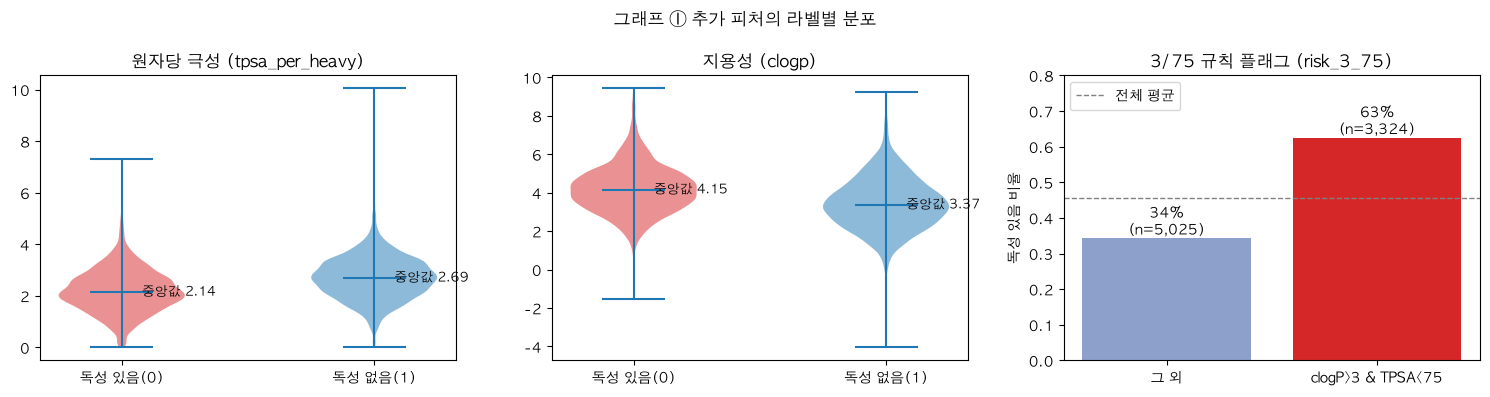

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, col, title in [(ax[0], "tpsa_per_heavy", "원자당 극성 (tpsa_per_heavy)"), (ax[1], "clogp", "지용성 (clogp)")]:
    data = [X_all.loc[y == k, col] for k in (0, 1)]
    vp = a.violinplot(data, showmedians=True)
    for body, k in zip(vp["bodies"], (0, 1)):
        body.set_facecolor(LABEL_COLOR[k]); body.set_alpha(0.5)
    a.set_xticks([1, 2], [LABEL_NAME[0], LABEL_NAME[1]]); a.set_title(title)
    for i, d in enumerate(data, start=1):
        a.text(i + 0.08, d.median(), f"중앙값 {d.median():.2f}", va="center", fontsize=9)

rate = 1 - y.groupby(X_all["risk_3_75"]).mean()
cnt = X_all["risk_3_75"].value_counts().sort_index()
bars = ax[2].bar(["그 외", "clogP>3 & TPSA<75"], rate.values, color=["#8da0cb", "#d62728"])
for b, r, n in zip(bars, rate.values, cnt.values):
    ax[2].text(b.get_x() + b.get_width() / 2, r + 0.01, f"{r:.0%}\n(n={n:,})", ha="center")
ax[2].axhline(1 - y.mean(), color="gray", ls="--", lw=1, label="전체 평균")
ax[2].set_ylim(0, 0.8); ax[2].set_ylabel("독성 있음 비율"); ax[2].set_title("3/75 규칙 플래그 (risk_3_75)"); ax[2].legend()
plt.suptitle("그래프 ① 추가 피처의 라벨별 분포"); plt.tight_layout(); plt.show()

## 2. 공통 평가 함수 `evaluate_model()`

교수님 가이드의 7단계를 그대로 구현합니다.

1. 데이터 분할 `train_test_split(test_size=0.2, stratify=y, random_state=42)`
2. 모델 생성 `model_cls(**params)`
3. 파이프라인: `scale=True`이면 연속형 열만 RobustScaler (0/1 지문은 그대로) → 모델
4. 교차검증 `cross_validate` – **학습 데이터에만**, 지표는 라벨 0 F1
5. 학습·예측 `fit()` / `predict()`
6. 성능 평가 `classification_report(output_dict=True)` → DataFrame
7. 반환: Pipeline, 결과 딕셔너리, report DataFrame

모든 실험이 같은 `random_state=42` 분할을 쓰므로 모델 간 비교가 공정합니다.

In [4]:
F1_0 = make_scorer(f1_score, pos_label=0)          # 라벨 0(독성 있음) F1
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
CONT = NUM + TPSA_FEAT                              # 스케일링 대상(연속형)
RESULTS = []                                        # 모든 실험 결과 누적
PIPES = {}                                          # 실험 이름 → 학습된 Pipeline (Hold-out 분석·제출용)
SETTINGS = {}                                       # 실험 이름 → (모델 클래스, 파라미터, 피처, scale)

def make_pipeline(model, cols, scale=False):
    steps = []
    if scale:
        num_cols = [c for c in cols if c in CONT]
        steps.append(("scaler", ColumnTransformer([("num", RobustScaler(), num_cols)],
                                                  remainder="passthrough")))
    steps.append(("model", model))
    return Pipeline(steps)

def split(features):
    return train_test_split(X_all[features], y, test_size=0.2, stratify=y, random_state=SEED)

def evaluate_model(model_cls, params=None, features=None, scale=False, name=None,
                   X=None, y=y, test_size=0.2, cv=CV, verbose=True):
    """분할 → 모델 생성 → 파이프라인 → 교차검증 → 학습/예측 → 평가 → 반환"""
    params = params or {}
    X = X_all if X is None else X
    features = features or list(X.columns)
    name = name or model_cls.__name__
    # 1. 데이터 분할
    X_tr, X_te, y_tr, y_te = train_test_split(X[features], y, test_size=test_size,
                                              stratify=y, random_state=SEED)
    # 2. 모델 생성 / 3. 파이프라인
    pipe = make_pipeline(model_cls(**params), features, scale)
    # 4. 교차검증 (학습 데이터만)
    t0 = time.time()
    cv_res = cross_validate(pipe, X_tr, y_tr, cv=cv, scoring=F1_0, n_jobs=1)
    # 5. 학습 및 예측
    pipe.fit(X_tr, y_tr)
    y_pred = pipe.predict(X_te)
    # 6. 성능 평가
    report = pd.DataFrame(classification_report(y_te, y_pred, output_dict=True,
                                                target_names=["0 독성 있음", "1 독성 없음"])).T
    result = {
        "model": name,
        "n_features": len(features),
        "scale": scale,
        "CV_F1_0": cv_res["test_score"].mean(),
        "CV_F1_0_std": cv_res["test_score"].std(),
        "cv_scores": cv_res["test_score"],
        "Accuracy": accuracy_score(y_te, y_pred),
        "Precision_0": report.loc["0 독성 있음", "precision"],
        "Recall_0": report.loc["0 독성 있음", "recall"],
        "F1_0": f1_score(y_te, y_pred, pos_label=0),
        "time_s": round(time.time() - t0, 1),
    }
    RESULTS.append(result)
    PIPES[name] = pipe
    SETTINGS[name] = (model_cls, params, features, scale)
    if verbose:
        print(f"[{name}] CV F1(0) {result['CV_F1_0']:.4f} ± {result['CV_F1_0_std']:.4f} | "
              f"Hold-out F1(0) {result['F1_0']:.4f} | Acc {result['Accuracy']:.4f} | {result['time_s']}s")
    # 7. 결과 반환
    return pipe, result, report

def results_table(names=None, with_folds=False):
    df = pd.DataFrame(RESULTS).drop_duplicates("model", keep="last")
    if names is not None:
        df = df[df.model.isin(names)]
    df = df.sort_values("CV_F1_0", ascending=False).reset_index(drop=True)
    return df if with_folds else df.drop(columns="cv_scores").round(4)

def plot_compare(names, title, ax=None, color="#8da0cb"):
    """막대 = CV F1(0) 평균 ± 표준편차, 회색 점 = fold별 점수, 빨간 다이아 = Hold-out F1(0)"""
    df = results_table(names, with_folds=True).iloc[::-1]
    if ax is None:
        _, ax = plt.subplots(figsize=(10, 0.6 * len(df) + 1.5))
    pos = np.arange(len(df))
    ax.barh(pos, df.CV_F1_0, xerr=df.CV_F1_0_std, color=color, alpha=0.8, capsize=3, label="CV F1(0) 평균 ± std")
    for i, (p, folds) in enumerate(zip(pos, df.cv_scores)):
        ax.scatter(folds, np.full(len(folds), p), s=14, color="dimgray", alpha=0.7, zorder=3,
                   label="fold별 CV 점수" if i == 0 else None)
    ax.scatter(df.F1_0, pos, marker="D", s=50, color="#d62728", zorder=4, label="Hold-out F1(0)")
    for p, m in zip(pos, df.CV_F1_0):
        ax.text(m, p + 0.3, f"{m:.4f}", fontsize=8, ha="center")
    ax.set_yticks(pos, df.model)
    allv = np.concatenate([np.concatenate(df.cv_scores.values), df.F1_0.values])
    ax.set_xlim(allv.min() - 0.02, allv.max() + 0.02)
    ax.set_xlabel("라벨 0(독성 있음) F1-score"); ax.set_title(title)
    ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)
    return ax

## 3. E1·E2·E3 – 피처 가설 검증 (RandomForest 고정)

모델을 RF로 고정하고 피처만 바꿔, 어떤 피처 구성이 좋은지 봅니다.

- **E1** 기준선: 원본 지문 + 물성
- **E2** 가설: 입체 정보를 넣으면 라벨 충돌이 줄어 성능이 오른다
- **E3** 가설: EDA에서 찾은 `tpsa_per_heavy`(극성)가 clogp와 함께 독성 구분을 돕는다

그래프 ②: 막대 = CV 평균, 회색 점 = fold별 점수(흩어진 정도 = 불확실성), 빨간 ◆ = Hold-out.

[E1 RF | 원본FP+물성] CV F1(0) 0.7645 ± 0.0038 | Hold-out F1(0) 0.7672 | Acc 0.7976 | 9.8s
[E2 RF | 입체FP+물성] CV F1(0) 0.7697 ± 0.0042 | Hold-out F1(0) 0.7591 | Acc 0.7898 | 8.8s
[E3 RF | 입체FP+물성+TPSA] CV F1(0) 0.7767 ± 0.0082 | Hold-out F1(0) 0.7565 | Acc 0.7868 | 8.4s


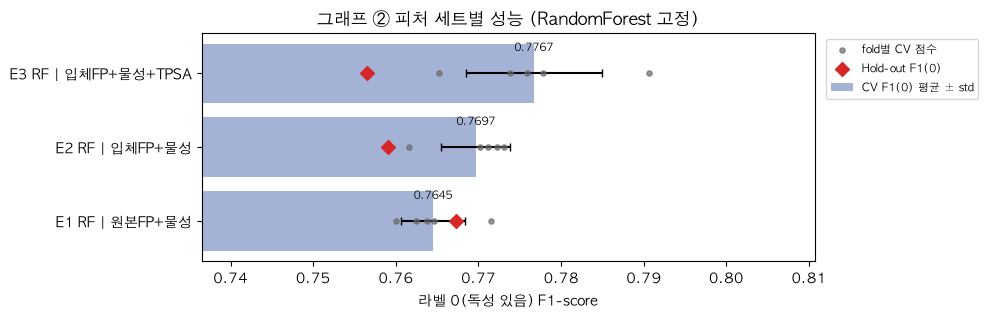

,model,n_features,scale,CV_F1_0,CV_F1_0_std,Accuracy,Precision_0,Recall_0,F1_0,time_s
0,E3 RF | 입체FP+물성+TPSA,3030,False,0.7767,0.0082,0.7868,0.7889,0.7267,0.7565,8.4
1,E2 RF | 입체FP+물성,3027,False,0.7697,0.0042,0.7898,0.7945,0.7267,0.7591,8.8
2,E1 RF | 원본FP+물성,3027,False,0.7645,0.0038,0.7976,0.8061,0.7319,0.7672,9.8


In [5]:
RF_BASE = dict(n_estimators=500, n_jobs=N_JOBS, random_state=SEED)

E123 = []
for i, (fs_name, cols) in enumerate(FEATURE_SETS.items(), start=1):
    name = f"E{i} RF | {fs_name}"
    evaluate_model(RandomForestClassifier, RF_BASE, features=cols, name=name)
    E123.append(name)

plot_compare(E123, "그래프 ② 피처 세트별 성능 (RandomForest 고정)"); plt.tight_layout(); plt.show()
results_table(E123)

> CV F1(0)이 가장 높은 피처 세트를 이후 실험의 기준 피처(`BEST_FS`)로 씁니다.
> (CV는 학습 데이터 기준이라 Hold-out보다 결과 선택에 더 믿을 만합니다.)

In [6]:
fs_scores = {fs: results_table([n]).loc[0, "CV_F1_0"] for fs, n in zip(FEATURE_SETS, E123)}
BEST_FS = max(fs_scores, key=fs_scores.get)
FEATS = FEATURE_SETS[BEST_FS]
X_tr, X_te, y_tr, y_te = split(FEATS)
print("기준 피처 세트:", BEST_FS, f"({len(FEATS)}개)")

기준 피처 세트: 입체FP+물성+TPSA (3030개)


## 4. E4 – 모델 비교 (기본 하이퍼파라미터)

같은 피처, 같은 분할에서 모델만 바꿉니다.

- 선형 기준선: LogisticRegression (**스케일링 O**)
- 배깅: RandomForest
- 부스팅: XGBoost, LightGBM, CatBoost

트리 모델은 값의 크기 순서만 보므로 스케일링이 필요 없습니다(`scale=False`).

[E4 LogReg] CV F1(0) 0.7549 ± 0.0114 | Hold-out F1(0) 0.7344 | Acc 0.7623 | 3.8s
[E4 RF] CV F1(0) 0.7767 ± 0.0082 | Hold-out F1(0) 0.7565 | Acc 0.7868 | 8.9s
[E4 XGBoost] CV F1(0) 0.7729 ± 0.0092 | Hold-out F1(0) 0.7568 | Acc 0.7856 | 16.7s
[E4 LightGBM] CV F1(0) 0.7815 ± 0.0101 | Hold-out F1(0) 0.7627 | Acc 0.7898 | 25.8s
[E4 CatBoost] CV F1(0) 0.7762 ± 0.0122 | Hold-out F1(0) 0.7653 | Acc 0.7910 | 50.3s


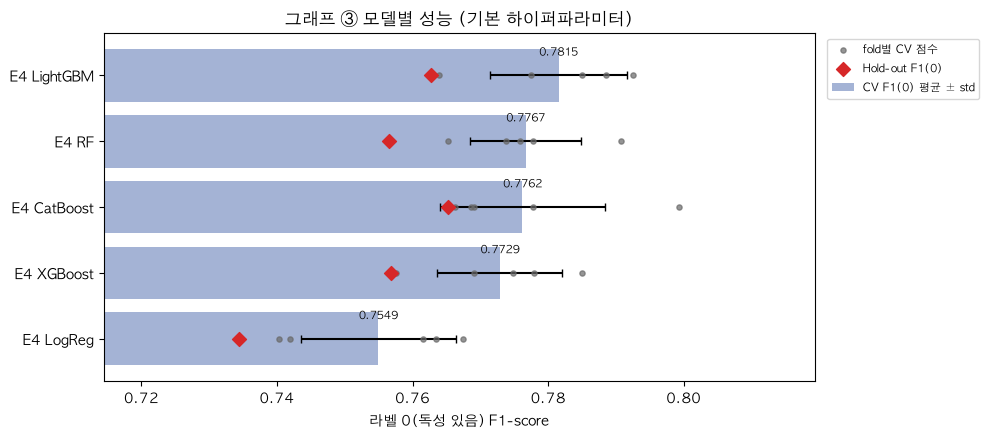

,model,n_features,scale,CV_F1_0,CV_F1_0_std,Accuracy,Precision_0,Recall_0,F1_0,time_s
0,E4 LightGBM,3030,False,0.7815,0.0101,0.7898,0.7855,0.7411,0.7627,25.8
1,E4 RF,3030,False,0.7767,0.0082,0.7868,0.7889,0.7267,0.7565,8.9
2,E4 CatBoost,3030,False,0.7762,0.0122,0.7910,0.7837,0.7477,0.7653,50.3
3,E4 XGBoost,3030,False,0.7729,0.0092,0.7856,0.7834,0.7319,0.7568,16.7
4,E4 LogReg,3030,True,0.7549,0.0114,0.7623,0.7480,0.7214,0.7344,3.8


In [7]:
BASE_MODELS = {
    "LogReg":   (LogisticRegression, dict(C=0.1, max_iter=3000), True),
    "RF":       (RandomForestClassifier, RF_BASE, False),
    "XGBoost":  (XGBClassifier, dict(n_estimators=500, learning_rate=0.05, max_depth=6,
                                     subsample=0.8, colsample_bytree=0.3, tree_method="hist",
                                     n_jobs=N_JOBS, random_state=SEED, eval_metric="logloss"), False),
    "LightGBM": (LGBMClassifier, dict(n_estimators=500, learning_rate=0.05, num_leaves=31,
                                      subsample=0.8, subsample_freq=1, colsample_bytree=0.3,
                                      n_jobs=N_JOBS, random_state=SEED, verbose=-1), False),
    "CatBoost": (CatBoostClassifier, dict(iterations=500, learning_rate=0.08, depth=6,
                                          thread_count=N_JOBS, random_seed=SEED, verbose=0, allow_writing_files=False), False),
}
E4 = []
for name, (cls, params, scale) in BASE_MODELS.items():
    evaluate_model(cls, params, features=FEATS, scale=scale, name=f"E4 {name}")
    E4.append(f"E4 {name}")

plot_compare(E4, "그래프 ③ 모델별 성능 (기본 하이퍼파라미터)"); plt.tight_layout(); plt.show()
results_table(E4)

#### 그래프 ④ 모델별 혼동행렬 (Hold-out)

F1 하나로는 **어떤 실수**를 하는지 안 보입니다.
왼쪽 아래 = 독성 있는 분자를 "없음"으로 놓친 수(위험한 실수), 오른쪽 위 = 독성 없는 분자를 "있음"으로 잘못 경보한 수입니다.

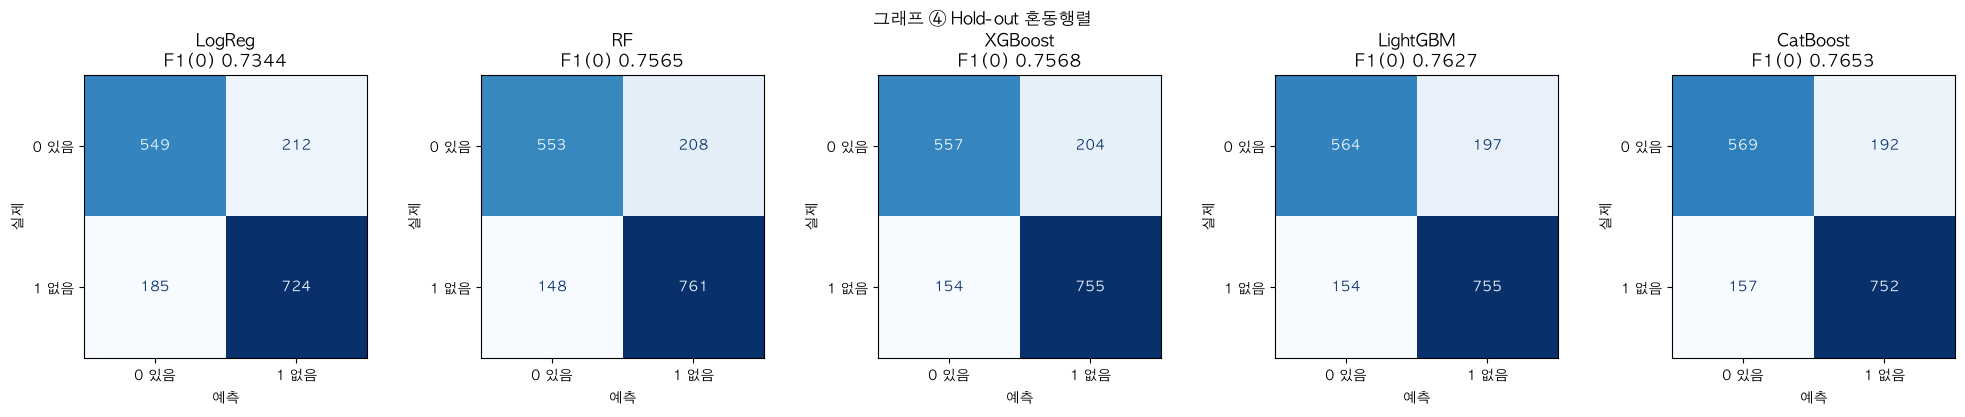

기본 모델 최고: E4 LightGBM – classification report


,precision,recall,f1-score,support
0 독성 있음,0.7855,0.7411,0.7627,761.0000
1 독성 없음,0.7931,0.8306,0.8114,909.0000
accuracy,0.7898,0.7898,0.7898,0.7898
macro avg,0.7893,0.7859,0.7870,1670.0000
weighted avg,0.7896,0.7898,0.7892,1670.0000


In [8]:
fig, axes = plt.subplots(1, len(E4), figsize=(4 * len(E4), 4))
for a, name in zip(axes, E4):
    ConfusionMatrixDisplay.from_estimator(PIPES[name], X_te, y_te, display_labels=["0 있음", "1 없음"],
                                          cmap="Blues", colorbar=False, ax=a)
    f1 = results_table([name]).loc[0, "F1_0"]
    a.set_title(f"{name.replace('E4 ', '')}\nF1(0) {f1:.4f}"); a.set_xlabel("예측"); a.set_ylabel("실제")
plt.suptitle("그래프 ④ Hold-out 혼동행렬"); plt.tight_layout(); plt.show()

best_e4 = results_table(E4).loc[0, "model"]
print(f"기본 모델 최고: {best_e4} – classification report")
report = pd.DataFrame(classification_report(y_te, PIPES[best_e4].predict(X_te), output_dict=True,
                                            target_names=["0 독성 있음", "1 독성 없음"])).T
report.round(4)

#### 그래프 ⑤ 피처 중요도 상위 20개

가장 좋은 트리 모델이 어떤 정보에 의존하는지 봅니다. 색 = 피처 그룹.
EDA에서 중요했던 clogp, tpsa_per_heavy가 상위에 있다면 모델이 도메인 지식과 같은 방향으로 학습했다는 근거가 됩니다.
비트 번호의 의미는 Notion의 fingerprint 사전(`fingerprint_master_dictionary_3072.csv`)으로 찾아볼 수 있습니다.

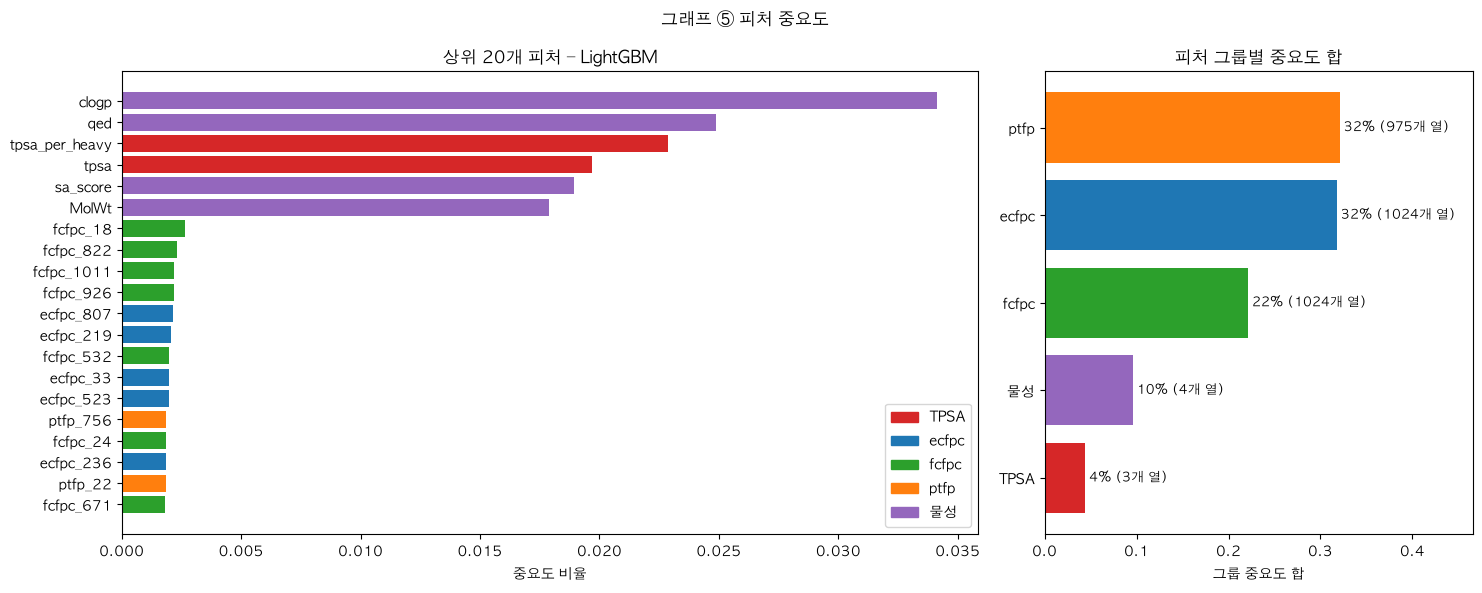

In [9]:
GROUP_COLOR = {"ecfpc": "#1f77b4", "fcfpc": "#2ca02c", "ptfp": "#ff7f0e", "ecfp": "#9ecae1",
               "fcfp": "#a1d99b", "물성": "#9467bd", "TPSA": "#d62728"}
def feat_group(c):
    if c in NUM: return "물성"
    if c in TPSA_FEAT: return "TPSA"
    return c.split("_")[0]

tree_e4 = [n for n in results_table(E4).model if n != "E4 LogReg"][0]
model = PIPES[tree_e4].named_steps["model"]
imp = pd.Series(model.feature_importances_, index=FEATS)
imp = (imp / imp.sum()).sort_values(ascending=False)
top = imp.head(20)[::-1]

fig, ax = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={"width_ratios": [2, 1]})
ax[0].barh(top.index, top.values, color=[GROUP_COLOR[feat_group(c)] for c in top.index])
ax[0].set_xlabel("중요도 비율"); ax[0].set_title(f"상위 20개 피처 – {tree_e4.replace('E4 ', '')}")
handles = [plt.Rectangle((0, 0), 1, 1, color=GROUP_COLOR[g]) for g in sorted({feat_group(c) for c in top.index})]
ax[0].legend(handles, sorted({feat_group(c) for c in top.index}), loc="lower right")

grp = imp.groupby(imp.index.map(feat_group)).sum().sort_values()
cnt = pd.Series(FEATS).map(feat_group).value_counts()
ax[1].barh(grp.index, grp.values, color=[GROUP_COLOR[g] for g in grp.index])
for i, (g, v) in enumerate(grp.items()):
    ax[1].text(v, i, f" {v:.0%} ({cnt[g]}개 열)", va="center", fontsize=9)
ax[1].set_xlim(0, grp.max() * 1.45); ax[1].set_xlabel("그룹 중요도 합"); ax[1].set_title("피처 그룹별 중요도 합")
plt.suptitle("그래프 ⑤ 피처 중요도"); plt.tight_layout(); plt.show()

## 5. E5 – Bayesian Optimization 하이퍼파라미터 탐색 (Optuna)

Optuna의 기본 탐색기 **TPE**는 Bayesian Optimization 방법입니다. 앞선 시도의 점수를 보고 다음에 시험할 조합을 고릅니다.

- 대상: RF(배깅) + XGBoost / LightGBM / CatBoost(부스팅)
- 탐색은 **학습 데이터(80%)** 에서만, 3-fold CV, 지표는 라벨 0 F1
- **탐색 횟수 = 시험해 보는 하이퍼파라미터 조합 수** (epoch 아님). 조합 1개당 3-fold 학습
- 결과는 `optuna_tuning.db`에 저장 → 다시 실행하면 **이어서 탐색**
  - `TUNE_TRIALS = 15`: 이번 실행에서 15회 추가 (처음이면 1~15회)
  - 나중에 `TUNE_TRIALS = 10` → 16~25회 추가 탐색
  - `TUNE_TRIALS = 0` → 탐색 없이 저장된 최적값만 사용
- study 이름에 피처 세트가 들어 있어, 피처 세트가 바뀌면 새 study로 분리됩니다.

In [10]:
TUNE_TRIALS = 15
STORAGE = "sqlite:///optuna_tuning.db"
CV3 = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)

def space_rf(t):
    return dict(n_estimators=t.suggest_int("n_estimators", 300, 1000),
                max_features=t.suggest_float("max_features", 0.01, 0.2, log=True),
                min_samples_leaf=t.suggest_int("min_samples_leaf", 1, 5),
                max_depth=t.suggest_int("max_depth", 10, 60))

def space_xgb(t):
    return dict(n_estimators=t.suggest_int("n_estimators", 300, 1200),
                learning_rate=t.suggest_float("learning_rate", 0.01, 0.2, log=True),
                max_depth=t.suggest_int("max_depth", 3, 10),
                min_child_weight=t.suggest_int("min_child_weight", 1, 10),
                subsample=t.suggest_float("subsample", 0.6, 1.0),
                colsample_bytree=t.suggest_float("colsample_bytree", 0.05, 0.6),
                reg_lambda=t.suggest_float("reg_lambda", 0.1, 10, log=True))

def space_lgbm(t):
    return dict(n_estimators=t.suggest_int("n_estimators", 300, 1200),
                learning_rate=t.suggest_float("learning_rate", 0.01, 0.2, log=True),
                num_leaves=t.suggest_int("num_leaves", 15, 127),
                min_child_samples=t.suggest_int("min_child_samples", 5, 50),
                subsample=t.suggest_float("subsample", 0.6, 1.0),
                colsample_bytree=t.suggest_float("colsample_bytree", 0.05, 0.6),
                reg_lambda=t.suggest_float("reg_lambda", 0.01, 10, log=True))

def space_cat(t):
    return dict(iterations=t.suggest_int("iterations", 300, 800),
                learning_rate=t.suggest_float("learning_rate", 0.02, 0.2, log=True),
                depth=t.suggest_int("depth", 4, 7),
                l2_leaf_reg=t.suggest_float("l2_leaf_reg", 1, 10, log=True),
                rsm=t.suggest_float("rsm", 0.05, 0.5))          # 트리마다 쓰는 피처 비율

SEARCH = {   # 이름: (모델 클래스, 고정 파라미터, 탐색 공간)
    "RF":       (RandomForestClassifier, dict(n_jobs=N_JOBS, random_state=SEED), space_rf),
    "XGBoost":  (XGBClassifier, dict(tree_method="hist", n_jobs=N_JOBS, random_state=SEED,
                                     eval_metric="logloss"), space_xgb),
    "LightGBM": (LGBMClassifier, dict(subsample_freq=1, n_jobs=N_JOBS, random_state=SEED, verbose=-1), space_lgbm),
    "CatBoost": (CatBoostClassifier, dict(thread_count=N_JOBS, random_seed=SEED, verbose=0, allow_writing_files=False), space_cat),
}

STUDIES, BEST_PARAMS = {}, {}
for name, (cls, fixed, space) in SEARCH.items():
    study = optuna.create_study(study_name=f"{name}__{BEST_FS}", storage=STORAGE, direction="maximize",
                                sampler=optuna.samplers.TPESampler(seed=SEED), load_if_exists=True)
    done = len(study.trials)
    def objective(trial, cls=cls, fixed=fixed, space=space):
        return cross_val_score(cls(**fixed, **space(trial)), X_tr, y_tr, cv=CV3, scoring=F1_0, n_jobs=1).mean()
    t0 = time.time()
    if TUNE_TRIALS > 0:
        print(f"▶ {name}: 기존 {done}회 + 이번 {TUNE_TRIALS}회 탐색")
        study.optimize(objective, n_trials=TUNE_TRIALS, show_progress_bar=True)
    STUDIES[name] = study
    BEST_PARAMS[name] = {**fixed, **study.best_params}
    print(f"  {name:9s} 누적 {len(study.trials)}회 | best CV3 F1(0) {study.best_value:.4f} | "
          f"{time.time()-t0:.0f}s | {study.best_params}")

▶ RF: 기존 0회 + 이번 15회 탐색


  0%|          | 0/15 [00:00<?, ?it/s]

  RF        누적 15회 | best CV3 F1(0) 0.7644 | 133s | {'n_estimators': 721, 'max_features': 0.08341106432362087, 'min_samples_leaf': 1, 'max_depth': 59}
▶ XGBoost: 기존 0회 + 이번 15회 탐색


  0%|          | 0/15 [00:00<?, ?it/s]

  XGBoost   누적 15회 | best CV3 F1(0) 0.7718 | 143s | {'n_estimators': 424, 'learning_rate': 0.12119306204151588, 'max_depth': 8, 'min_child_weight': 10, 'subsample': 0.9354797651623138, 'colsample_bytree': 0.41268247136749986, 'reg_lambda': 5.437743441351354}
▶ LightGBM: 기존 0회 + 이번 15회 탐색


  0%|          | 0/15 [00:00<?, ?it/s]

  LightGBM  누적 15회 | best CV3 F1(0) 0.7708 | 495s | {'n_estimators': 938, 'learning_rate': 0.06568912964424264, 'num_leaves': 125, 'min_child_samples': 14, 'subsample': 0.9137232144524006, 'colsample_bytree': 0.5415592636582047, 'reg_lambda': 0.245643490206532}
▶ CatBoost: 기존 0회 + 이번 15회 탐색


  0%|          | 0/15 [00:00<?, ?it/s]

  CatBoost  누적 15회 | best CV3 F1(0) 0.7696 | 302s | {'iterations': 438, 'learning_rate': 0.09238636815718555, 'depth': 7, 'l2_leaf_reg': 1.1088745356350154, 'rsm': 0.2387919576205767}


#### 그래프 ⑥ 탐색 수렴 곡선

점 = 각 시도의 점수, 선 = 그때까지의 최고 점수.
**선이 일찍 평평해지면** 더 돌려도 이득이 적고, **끝까지 오르고 있으면** 그 모델만 `TUNE_TRIALS`를 늘려 이어서 탐색할 가치가 있습니다.

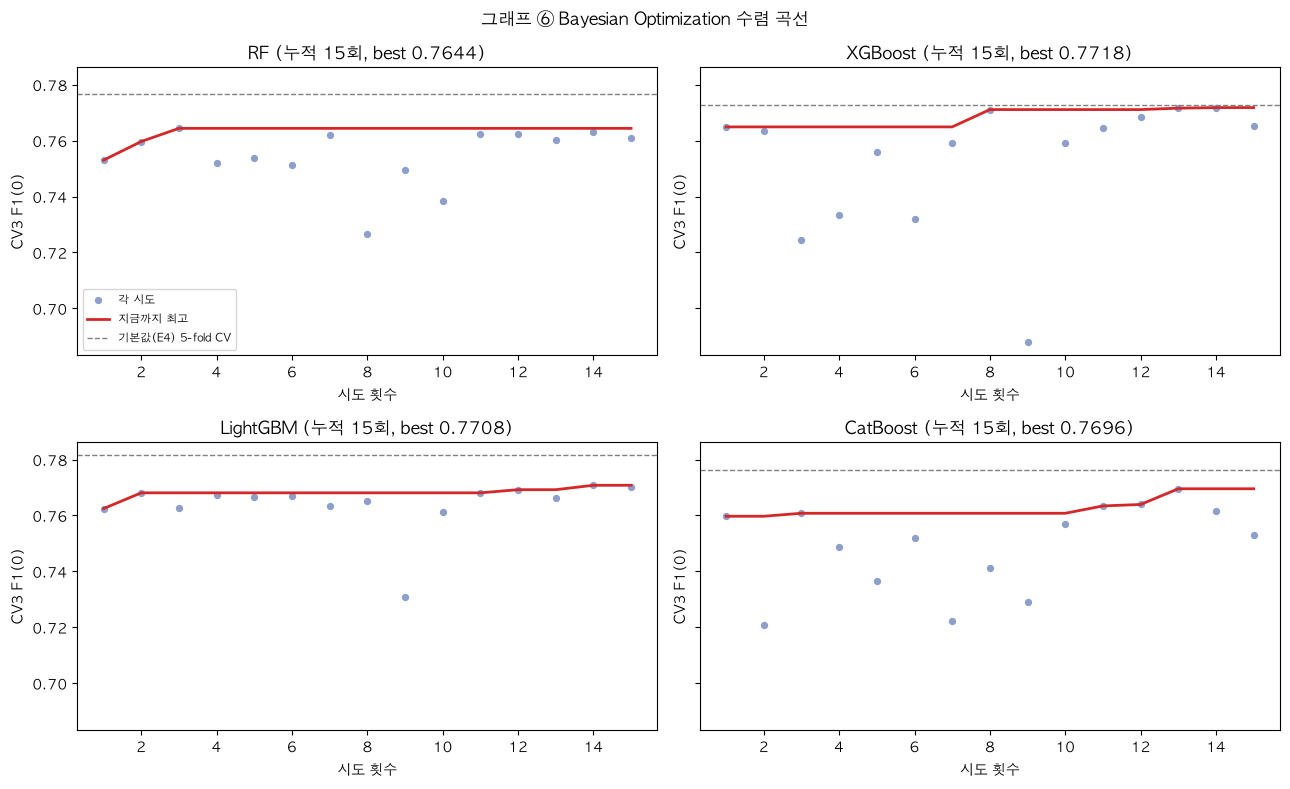

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharey=True)
for a, (name, study) in zip(axes.ravel(), STUDIES.items()):
    tr = study.trials_dataframe()
    tr = tr[tr.state == "COMPLETE"]
    a.scatter(tr.number + 1, tr.value, s=18, color="#8da0cb", label="각 시도")
    a.plot(tr.number + 1, tr.value.cummax(), color="#d62728", lw=2, label="지금까지 최고")
    base = results_table([f"E4 {name}"]).loc[0, "CV_F1_0"]
    a.axhline(base, color="gray", ls="--", lw=1, label="기본값(E4) 5-fold CV")
    a.set_title(f"{name} (누적 {len(tr)}회, best {tr.value.max():.4f})")
    a.set_xlabel("시도 횟수"); a.set_ylabel("CV3 F1(0)")
axes[0, 0].legend(fontsize=8)
plt.suptitle("그래프 ⑥ Bayesian Optimization 수렴 곡선"); plt.tight_layout(); plt.show()

#### 그래프 ⑦ 튜닝 전 vs 후

찾은 파라미터를 `evaluate_model()`에 넣어 기본값(E4)과 **같은 5-fold CV, 같은 Hold-out**으로 비교합니다.

[E5 RF tuned] CV F1(0) 0.7802 ± 0.0094 | Hold-out F1(0) 0.7579 | Acc 0.7892 | 44.6s
[E5 XGBoost tuned] CV F1(0) 0.7794 ± 0.0064 | Hold-out F1(0) 0.7568 | Acc 0.7856 | 17.3s
[E5 LightGBM tuned] CV F1(0) 0.7841 ± 0.0072 | Hold-out F1(0) 0.7709 | Acc 0.7964 | 149.4s
[E5 CatBoost tuned] CV F1(0) 0.7735 ± 0.0115 | Hold-out F1(0) 0.7579 | Acc 0.7850 | 78.6s


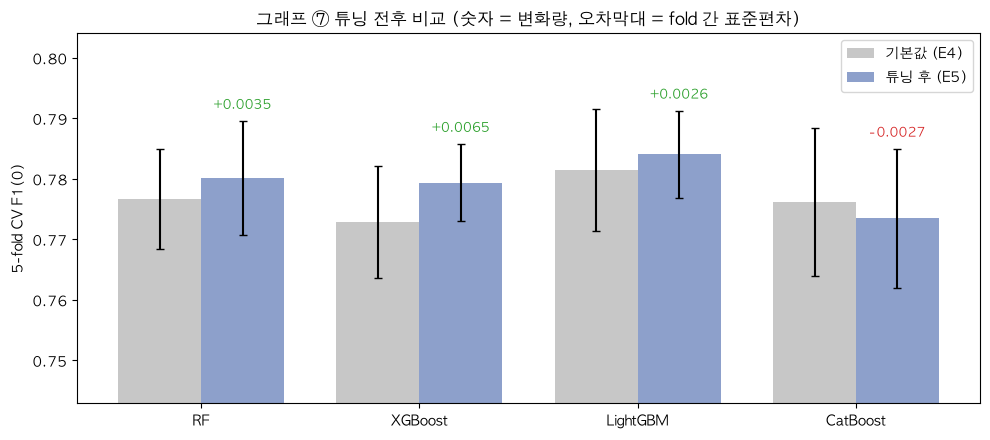

,model,n_features,scale,CV_F1_0,CV_F1_0_std,Accuracy,Precision_0,Recall_0,F1_0,time_s
0,E5 LightGBM tuned,3030,False,0.7841,0.0072,0.7964,0.7911,0.7516,0.7709,149.4
1,E4 LightGBM,3030,False,0.7815,0.0101,0.7898,0.7855,0.7411,0.7627,25.8
2,E5 RF tuned,3030,False,0.7802,0.0094,0.7892,0.7951,0.7240,0.7579,44.6
3,E5 XGBoost tuned,3030,False,0.7794,0.0064,0.7856,0.7834,0.7319,0.7568,17.3
4,E4 RF,3030,False,0.7767,0.0082,0.7868,0.7889,0.7267,0.7565,8.9
5,E4 CatBoost,3030,False,0.7762,0.0122,0.7910,0.7837,0.7477,0.7653,50.3
6,E5 CatBoost tuned,3030,False,0.7735,0.0115,0.7850,0.7784,0.7385,0.7579,78.6
7,E4 XGBoost,3030,False,0.7729,0.0092,0.7856,0.7834,0.7319,0.7568,16.7


In [12]:
E5 = []
for name, (cls, _, _) in SEARCH.items():
    evaluate_model(cls, BEST_PARAMS[name], features=FEATS, name=f"E5 {name} tuned")
    E5.append(f"E5 {name} tuned")

names = list(SEARCH)
before = results_table([f"E4 {n}" for n in names]).set_index("model").reindex([f"E4 {n}" for n in names])
after = results_table(E5).set_index("model").reindex(E5)
x = np.arange(len(names)); w = 0.38
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(x - w/2, before.CV_F1_0, w, yerr=before.CV_F1_0_std, capsize=3, color="#c7c7c7", label="기본값 (E4)")
ax.bar(x + w/2, after.CV_F1_0, w, yerr=after.CV_F1_0_std, capsize=3, color="#8da0cb", label="튜닝 후 (E5)")
for i, (b, a_) in enumerate(zip(before.CV_F1_0, after.CV_F1_0)):
    ax.text(i + w/2, a_ + after.CV_F1_0_std.iloc[i] + 0.002, f"{a_ - b:+.4f}", ha="center", fontsize=9,
            color="#2ca02c" if a_ >= b else "#d62728")
lo = min(before.CV_F1_0.min(), after.CV_F1_0.min())
ax.set_ylim(lo - 0.03, max(before.CV_F1_0.max(), after.CV_F1_0.max()) + 0.02)
ax.set_xticks(x, names); ax.set_ylabel("5-fold CV F1(0)"); ax.legend()
ax.set_title("그래프 ⑦ 튜닝 전후 비교 (숫자 = 변화량, 오차막대 = fold 간 표준편차)")
plt.tight_layout(); plt.show()
results_table([f"E4 {n}" for n in names] + E5)

## 6. E6 – VotingClassifier 앙상블

- 가설: 서로 다른 방식의 모델(배깅 1 + 부스팅 3)은 틀리는 분자가 다르므로, 확률을 평균하면(soft voting) 단일 모델보다 안정적이다.

#### 그래프 ⑧ 모델 간 예측 상관

Hold-out에서 각 모델이 낸 "독성 있음" 확률의 상관입니다. **상관이 낮을수록** 서로 다른 실수를 해서 앙상블 효과가 큽니다.

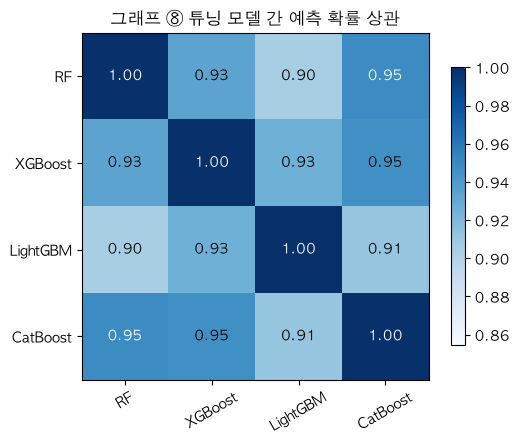

In [13]:
proba = pd.DataFrame({n.replace("E5 ", "").replace(" tuned", ""): PIPES[n].predict_proba(X_te)[:, 0] for n in E5})
corr = proba.corr()
fig, ax = plt.subplots(figsize=(5.5, 4.5))
im = ax.imshow(corr, cmap="Blues", vmin=corr.values.min() - 0.05, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=30); ax.set_yticks(range(len(corr)), corr.index)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center",
                color="white" if corr.iloc[i, j] > corr.values.mean() else "black")
fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title("그래프 ⑧ 튜닝 모델 간 예측 확률 상관")
plt.tight_layout(); plt.show()

#### 그래프 ⑨ Voting vs 단일 모델

튜닝한 4개 모델을 모두 묶은 것과, CV 상위 3개만 묶은 것을 단일 모델들과 비교합니다.

상위 3개: ['LightGBM', 'RF', 'XGBoost']
[E6 Voting(4)] CV F1(0) 0.7850 ± 0.0091 | Hold-out F1(0) 0.7702 | Acc 0.7970 | 289.1s
[E6 Voting(top3)] CV F1(0) 0.7820 ± 0.0096 | Hold-out F1(0) 0.7694 | Acc 0.7958 | 212.7s


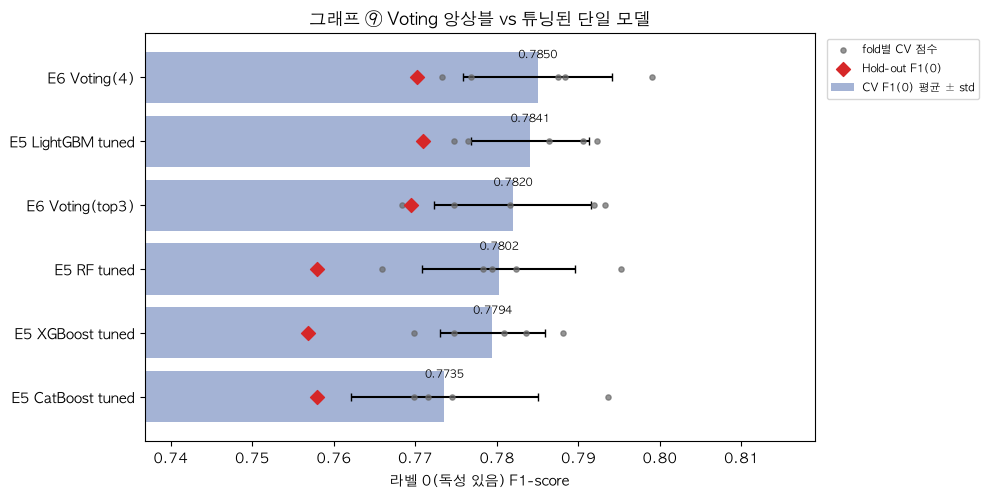

,model,n_features,scale,CV_F1_0,CV_F1_0_std,Accuracy,Precision_0,Recall_0,F1_0,time_s
0,E6 Voting(4),3030,False,0.7850,0.0091,0.7970,0.7955,0.7464,0.7702,289.1
1,E5 LightGBM tuned,3030,False,0.7841,0.0072,0.7964,0.7911,0.7516,0.7709,149.4
2,E6 Voting(top3),3030,False,0.7820,0.0096,0.7958,0.7925,0.7477,0.7694,212.7
3,E5 RF tuned,3030,False,0.7802,0.0094,0.7892,0.7951,0.7240,0.7579,44.6
4,E5 XGBoost tuned,3030,False,0.7794,0.0064,0.7856,0.7834,0.7319,0.7568,17.3
5,E5 CatBoost tuned,3030,False,0.7735,0.0115,0.7850,0.7784,0.7385,0.7579,78.6


In [14]:
def voting_params(names):
    return dict(estimators=[(n, SEARCH[n][0](**BEST_PARAMS[n])) for n in names], voting="soft", n_jobs=1)

ALL4 = list(SEARCH)
TOP3 = [n.replace("E5 ", "").replace(" tuned", "") for n in results_table(E5).model[:3]]
print("상위 3개:", TOP3)
evaluate_model(VotingClassifier, voting_params(ALL4), features=FEATS, name="E6 Voting(4)")
evaluate_model(VotingClassifier, voting_params(TOP3), features=FEATS, name="E6 Voting(top3)")
E6 = ["E6 Voting(4)", "E6 Voting(top3)"]

plot_compare(E5 + E6, "그래프 ⑨ Voting 앙상블 vs 튜닝된 단일 모델"); plt.tight_layout(); plt.show()
results_table(E5 + E6)

## 7. 전체 실험 비교

#### 그래프 ⑩ 모든 실험 한눈에 보기

,model,n_features,scale,CV_F1_0,CV_F1_0_std,Accuracy,Precision_0,Recall_0,F1_0,time_s
0,E6 Voting(4),3030,False,0.7850,0.0091,0.7970,0.7955,0.7464,0.7702,289.1
1,E5 LightGBM tuned,3030,False,0.7841,0.0072,0.7964,0.7911,0.7516,0.7709,149.4
2,E6 Voting(top3),3030,False,0.7820,0.0096,0.7958,0.7925,0.7477,0.7694,212.7
3,E4 LightGBM,3030,False,0.7815,0.0101,0.7898,0.7855,0.7411,0.7627,25.8
4,E5 RF tuned,3030,False,0.7802,0.0094,0.7892,0.7951,0.7240,0.7579,44.6
5,E5 XGBoost tuned,3030,False,0.7794,0.0064,0.7856,0.7834,0.7319,0.7568,17.3
6,E3 RF | 입체FP+물성+TPSA,3030,False,0.7767,0.0082,0.7868,0.7889,0.7267,0.7565,8.4
7,E4 RF,3030,False,0.7767,0.0082,0.7868,0.7889,0.7267,0.7565,8.9
8,E4 CatBoost,3030,False,0.7762,0.0122,0.7910,0.7837,0.7477,0.7653,50.3
9,E5 CatBoost tuned,3030,False,0.7735,0.0115,0.7850,0.7784,0.7385,0.7579,78.6


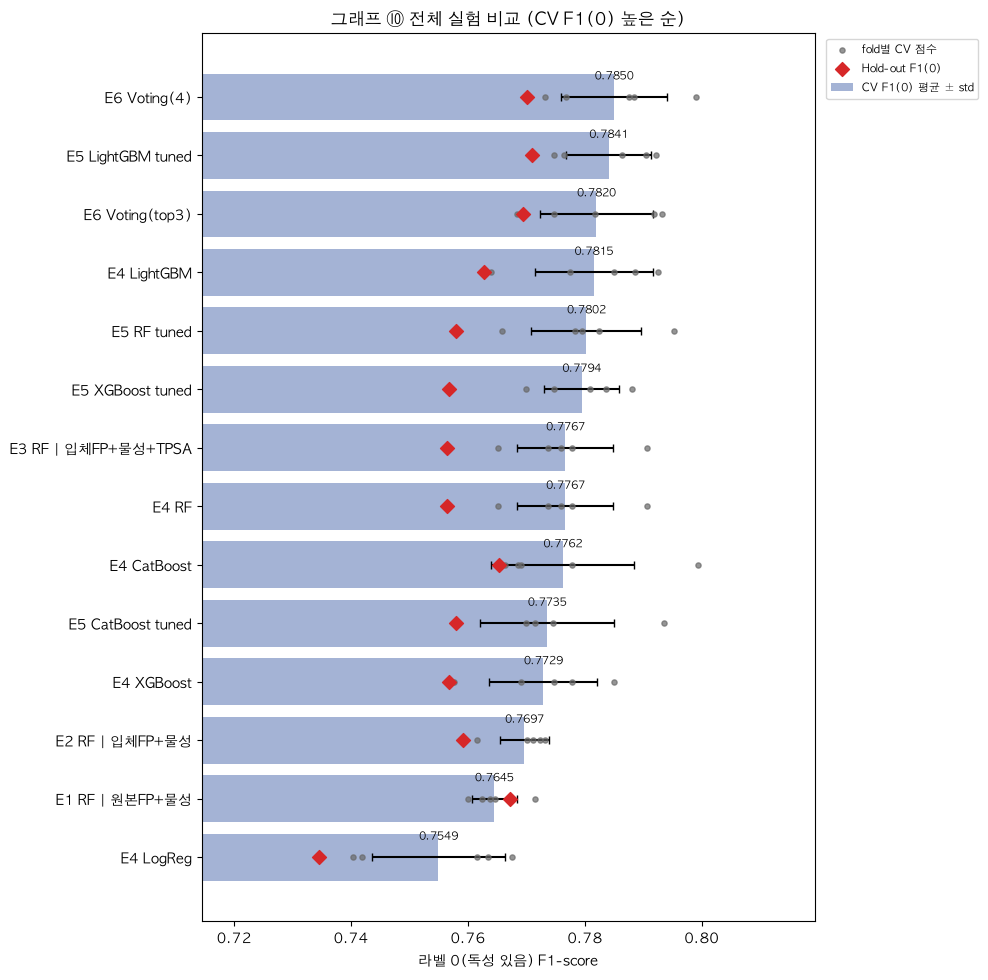

In [15]:
final_table = results_table()
display(final_table)
plot_compare(list(final_table.model), "그래프 ⑩ 전체 실험 비교 (CV F1(0) 높은 순)"); plt.tight_layout(); plt.show()

## 8. 제출 파일 생성 – `predict_output_김정인.csv`

- `SUBMIT_MODEL = None`이면 **CV F1(0)이 가장 높은 실험**을 자동 선택합니다.
- 다른 모델로 제출하려면 실험 이름을 넣고(예: `"E6 Voting(4)"`, `"E5 CatBoost tuned"`) **이 셀만 다시 실행**하면 됩니다.
- 선택한 설정으로 **전체 train(8,349개)** 에 다시 학습한 뒤 predict_input을 예측합니다.
- 예시 파일의 SMILES 순서를 그대로 쓰고 `output`만 채워 같은 파일에 덮어씁니다.

#### 그래프 ⑪ 예측 결과 점검

독성 있음(0) 예측 비율이 train(45.6%)과 크게 다르면 전처리나 모델에 문제가 있다는 신호입니다.
예측 확률 분포가 0.5 근처에 몰려 있으면 확신이 낮은 분자가 많다는 뜻입니다.

제출 모델: E6 Voting(4) | 재학습 55s → predict_output_김정인.csv 저장 (927행)
       model  CV_F1_0  CV_F1_0_std   F1_0  Accuracy
E6 Voting(4)    0.785       0.0091 0.7702     0.797


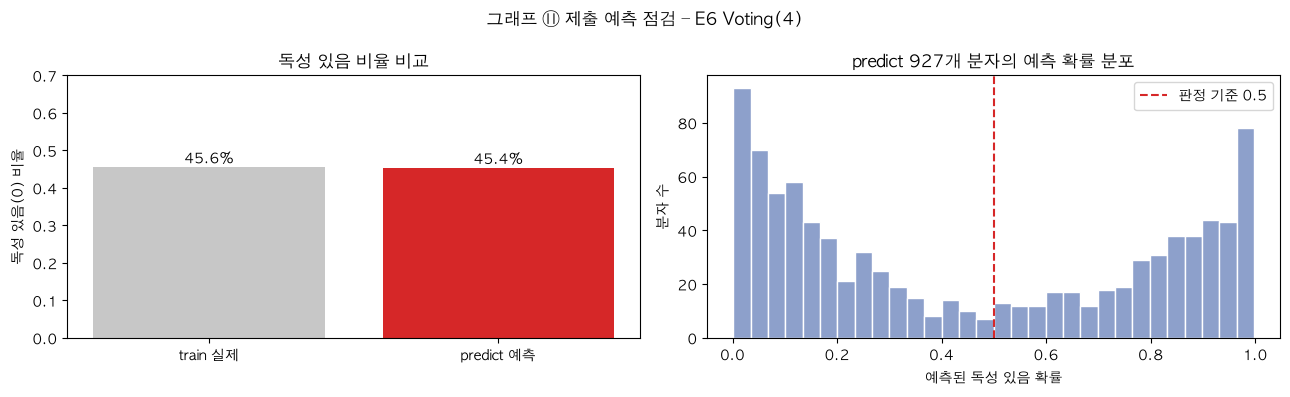

(데이터 비공개: 분자 SMILES가 포함된 표 출력은 제거함)


In [16]:
SUBMIT_MODEL = None          # None = CV 최고 / 예: "E6 Voting(4)"

name = SUBMIT_MODEL or results_table().loc[0, "model"]
cls, params, features, scale = SETTINGS[name]
sample = pd.read_csv(SAMPLE_PATH)
assert (sample["SMILES"].values == predict["SMILES"].values).all()

t0 = time.time()
final = make_pipeline(cls(**params), features, scale).fit(X_all[features], y)   # 전체 train으로 재학습
proba0 = final.predict_proba(X_pred_all[features])[:, 0]                       # 독성 있음 확률
pred = final.predict(X_pred_all[features]).astype(int)

sub = sample.copy()
sub["output"] = pred
assert list(sub.columns) == ["SMILES", "output"] and len(sub) == len(predict)
assert set(sub["output"].unique()) <= {0, 1}
sub.to_csv(SUBMIT_PATH, index=False)
print(f"제출 모델: {name} | 재학습 {time.time()-t0:.0f}s → {SUBMIT_PATH} 저장 ({len(sub)}행)")
print(results_table([name])[["model", "CV_F1_0", "CV_F1_0_std", "F1_0", "Accuracy"]].to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
rates = pd.Series({"train 실제": 1 - y.mean(), "predict 예측": (pred == 0).mean()})
bars = ax[0].bar(rates.index, rates.values, color=["#c7c7c7", "#d62728"])
for b, r in zip(bars, rates.values):
    ax[0].text(b.get_x() + b.get_width() / 2, r + 0.01, f"{r:.1%}", ha="center")
ax[0].set_ylim(0, 0.7); ax[0].set_ylabel("독성 있음(0) 비율"); ax[0].set_title("독성 있음 비율 비교")
ax[1].hist(proba0, bins=30, color="#8da0cb", edgecolor="white")
ax[1].axvline(0.5, color="#d62728", ls="--", label="판정 기준 0.5")
ax[1].set_xlabel("예측된 독성 있음 확률"); ax[1].set_ylabel("분자 수"); ax[1].legend()
ax[1].set_title(f"predict {len(pred)}개 분자의 예측 확률 분포")
plt.suptitle(f"그래프 ⑪ 제출 예측 점검 – {name}"); plt.tight_layout(); plt.show()
sub.head()

## 9. 개선 실험 – baseline + @

> 이 섹션은 **위 1~8번을 실행한 커널 상태 그대로** 이어서 실행합니다 (`X_all`, `BEST_PARAMS` 등 사용).
> 커널을 재시작했다면 5번 E5 셀의 `TUNE_TRIALS = 0`으로 바꾸고 처음부터 실행하세요 (튜닝 반복 방지).

**baseline** = 입체FP + TPSA + Voting4 (8번에서 만든 결과 → `outputs/output_baseline.csv`)

| 약어 | 내용 | 종류 |
|---|---|---|
| RDKit | RDKit 분자 기술자 (~200개 → 정리 후 사용) | 피처 추가 |
| ALERT | 독성 구조 경고 개수 (PAINS / Brenk / NIH) | 피처 추가 |
| MACCS | MACCS keys 166개 부분구조 유무 | 피처 추가 |
| Count | 입체 지문을 0/1 대신 **등장 횟수**로 | 피처 교체 |
| RareDrop | 1% 미만 / 99% 초과로만 켜지는 지문 비트 제거 | 피처 제거 |
| Std | SMILES 표준화(염 제거·전하 중화·호변이성질체 통일) 후 지문·TPSA 재계산 | 전처리 |
| TH | 라벨 0 F1이 최대가 되는 판정 기준(threshold) | 판정 |
| Stack | Voting 평균 대신 메타 모델(LogReg)이 모델별 가중치 학습 | 앙상블 |

**진행**
1. **1단계 (걸러내기)**: baseline 피처에 후보를 **하나씩만** 붙여 LightGBM(기본값)으로 빠르게 비교 → CV가 오른 항목만 통과 (최대 3개)
2. **2단계 (조합)**: 통과한 항목의 **모든 조합** × Voting4 + TH → 조합마다 `outputs/output_baseline+….csv` 저장
3. **3단계**: 2단계 최고 조합에서 Voting4 vs Stack 비교 → Stack이 나으면 `…+Stack+TH.csv` 추가
4. 모든 버전 중 CV F1(0) 최고를 `predict_output_김정인.csv`로 복사, 기록은 `outputs/버전_기록.csv`

그래프는 화면 출력과 함께 `모델링_그래프/` 폴더에도 저장합니다.

In [17]:
import shutil, itertools
from rdkit import DataStructs
from rdkit.Chem import MACCSkeys
from rdkit.Chem.FilterCatalog import FilterCatalog, FilterCatalogParams
from rdkit.Chem.MolStandardize import rdMolStandardize
from sklearn.model_selection import cross_val_predict

OUT_DIR, FIG_DIR = "outputs", "모델링_그래프"
os.makedirs(OUT_DIR, exist_ok=True); os.makedirs(FIG_DIR, exist_ok=True)

def save_fig(name):
    plt.savefig(f"{FIG_DIR}/{name}.png", dpi=120, bbox_inches="tight")

# baseline 결과 보존 (8번 셀 결과, 이미 있으면 덮어쓰지 않음)
if not os.path.exists(f"{OUT_DIR}/output_baseline.csv"):
    shutil.copy(SUBMIT_PATH, f"{OUT_DIR}/output_baseline.csv")
print("baseline 보존:", f"{OUT_DIR}/output_baseline.csv")

baseline 보존: outputs/output_baseline.csv


### 9-1. 후보 피처 계산

train / predict에 **같은 함수**를 적용합니다. 정리 기준(상수 열, 결측 채움 값, 중복 열)은 **train에서만** 정합니다.

In [18]:
t0 = time.time()
mols_tr = train["SMILES"].apply(Chem.MolFromSmiles)
mols_pr = predict["SMILES"].apply(Chem.MolFromSmiles)

# --- RDKit 분자 기술자 ---
def rdkit_desc(mols):
    d = pd.DataFrame([Descriptors.CalcMolDescriptors(m) for m in mols], index=mols.index)
    return d.replace([np.inf, -np.inf], np.nan).add_prefix("rd_")
rd_tr, rd_pr = rdkit_desc(mols_tr), rdkit_desc(mols_pr)
rd_tr = rd_tr.loc[:, rd_tr.nunique() > 1]                      # 상수 열 제거
med = rd_tr.median()
rd_tr, rd_pr = rd_tr.fillna(med), rd_pr[rd_tr.columns].fillna(med)
# 기존 연속형(물성·TPSA)과 거의 같은 열, 기술자끼리 거의 같은 열(|r|>0.98) 제거
ref = pd.concat([X_all[NUM + TPSA_FEAT], rd_tr], axis=1).corr().abs()
drop = set()
for c in rd_tr.columns:
    if c in drop: continue
    same = ref.loc[c, ref.columns != c]
    dup = same[same > 0.98].index
    if any(d in NUM + TPSA_FEAT for d in dup): drop.add(c); continue
    drop |= {d for d in dup if d.startswith("rd_")}
RDKIT = [c for c in rd_tr.columns if c not in drop]
print(f"RDKit 기술자: 계산 {len(Descriptors._descList)}개 → 정리 후 {len(RDKIT)}개")

# --- 독성 구조 경고 ---
CATALOGS = {}
for k in ["PAINS", "BRENK", "NIH"]:
    p = FilterCatalogParams(); p.AddCatalog(getattr(FilterCatalogParams.FilterCatalogs, k))
    CATALOGS[k] = FilterCatalog(p)
def alerts(mols):
    a = pd.DataFrame({f"alert_{k}": [len(c.GetMatches(m)) for m in mols] for k, c in CATALOGS.items()}, index=mols.index)
    a["alert_any"] = (a.sum(axis=1) > 0).astype(int)
    return a
al_tr, al_pr = alerts(mols_tr), alerts(mols_pr)
ALERT = list(al_tr.columns)

# --- MACCS keys ---
def maccs(mols):
    X = np.array([list(MACCSkeys.GenMACCSKeys(m)) for m in mols], dtype=np.uint8)
    return pd.DataFrame(X, columns=[f"maccs_{i}" for i in range(X.shape[1])], index=mols.index)
mc_tr, mc_pr = maccs(mols_tr), maccs(mols_pr)
MACCS = [c for c in mc_tr.columns if mc_tr[c].nunique() > 1]

# --- Count 지문 (입체 정보 포함, 0/1 대신 등장 횟수) ---
def morgan_count(mols, prefix, feature=False):
    kw = dict(radius=2, fpSize=1024, includeChirality=True)
    if feature:
        kw["atomInvariantsGenerator"] = rdFingerprintGenerator.GetMorganFeatureAtomInvGen()
    gen = rdFingerprintGenerator.GetMorganGenerator(**kw)
    X = np.stack([gen.GetCountFingerprintAsNumPy(m) for m in mols]).astype(np.uint8)
    return pd.DataFrame(X, columns=[f"{prefix}_{i}" for i in range(X.shape[1])], index=mols.index)

# --- SMILES 표준화 후 재계산 (입체 지문 + TPSA) ---
_lf, _un, _te = rdMolStandardize.LargestFragmentChooser(), rdMolStandardize.Uncharger(), rdMolStandardize.TautomerEnumerator()
def standardize(m):
    return _te.Canonicalize(_un.uncharge(_lf.choose(m)))
def std_block(mols, clogp):
    sm = mols.apply(standardize)
    tpsa = sm.apply(Descriptors.TPSA); heavy = sm.apply(lambda m: m.GetNumHeavyAtoms())
    tp = pd.DataFrame({"s_tpsa": tpsa, "s_tpsa_per_heavy": tpsa / heavy,
                       "s_risk_3_75": ((clogp > 3) & (tpsa < 75)).astype(int)}, index=mols.index)
    return sm, pd.concat([morgan_fp(sm, "s_ecfpc"), morgan_fp(sm, "s_fcfpc", feature=True), tp], axis=1)
smols_tr, st_tr = std_block(mols_tr, train["clogp"])
smols_pr, st_pr = std_block(mols_pr, predict["clogp"])
n_changed = (smols_tr.apply(Chem.MolToSmiles) != mols_tr.apply(Chem.MolToSmiles)).sum()
print(f"표준화로 구조 표기가 바뀐 train 분자: {n_changed}개 ({n_changed/len(train):.1%})")

cnt_tr = pd.concat([morgan_count(mols_tr, "c_ecfpc"), morgan_count(mols_tr, "c_fcfpc", True),
                    morgan_count(smols_tr, "sc_ecfpc"), morgan_count(smols_tr, "sc_fcfpc", True)], axis=1)
cnt_pr = pd.concat([morgan_count(mols_pr, "c_ecfpc"), morgan_count(mols_pr, "c_fcfpc", True),
                    morgan_count(smols_pr, "sc_ecfpc"), morgan_count(smols_pr, "sc_fcfpc", True)], axis=1)

# 기존 피처 + 후보 피처를 한 표로 (행 순서 = train / predict 그대로 → 분할 동일)
X_ext = pd.concat([X_all, rd_tr[RDKIT], al_tr, mc_tr[MACCS], st_tr, cnt_tr], axis=1)
X_pred_ext = pd.concat([X_pred_all, rd_pr[RDKIT], al_pr, mc_pr[MACCS], st_pr, cnt_pr], axis=1)
assert list(X_ext.columns) == list(X_pred_ext.columns)
print(f"후보 피처 계산 {time.time()-t0:.0f}s | X_ext {X_ext.shape}")

RDKit 기술자: 계산 217개 → 정리 후 187개
표준화로 구조 표기가 바뀐 train 분자: 1693개 (20.3%)
후보 피처 계산 88s | X_ext (8349, 11570)


In [19]:
CANDIDATES = ["RDKit", "ALERT", "MACCS", "Count", "RareDrop", "Std"]
ORDER = {k: i for i, k in enumerate(CANDIDATES)}

def build_feats(items):
    """baseline 피처(FEATS)에 항목들을 적용한 피처 목록. 적용 순서: Std → Count → RareDrop → 추가"""
    items = set(items)
    fp_e, fp_f, tp = ECFPC, FCFPC, TPSA_FEAT
    if "Std" in items:
        fp_e = [f"s_{c}" for c in ECFPC]; fp_f = [f"s_{c}" for c in FCFPC]; tp = [f"s_{c}" for c in TPSA_FEAT]
    if "Count" in items:
        pre = "sc_" if "Std" in items else "c_"
        fp_e = [pre + c.replace("s_", "") for c in fp_e]; fp_f = [pre + c.replace("s_", "") for c in fp_f]
    fps = fp_e + fp_f + PTFP_KEEP
    if "RareDrop" in items:
        rate = (X_ext[fps] > 0).mean()
        fps = [c for c in fps if 0.01 <= rate[c] <= 0.99]
    feats = fps + NUM + tp
    if "RDKit" in items: feats += RDKIT
    if "ALERT" in items: feats += ALERT
    if "MACCS" in items: feats += MACCS
    return feats

def version_name(items, suffix=""):
    return "baseline" + "".join(f"+{k}" for k in sorted(items, key=ORDER.get)) + suffix

assert build_feats([]) == FEATS          # 빈 조합 = baseline 피처와 동일
for k in CANDIDATES:
    print(f"baseline+{k:9s} {len(build_feats([k])):5d}개 (baseline {len(FEATS)}개)")

baseline+RDKit      3217개 (baseline 3030개)
baseline+ALERT      3034개 (baseline 3030개)
baseline+MACCS      3184개 (baseline 3030개)
baseline+Count      3030개 (baseline 3030개)
baseline+RareDrop   2374개 (baseline 3030개)
baseline+Std        3030개 (baseline 3030개)


### 9-2. 1단계 – 후보 걸러내기 (LightGBM 기본값)

- `evaluate_model()`로 baseline 피처와 후보 1개 추가 버전을 **같은 분할·같은 5-fold**에서 비교합니다.
- fold별로 짝지어 차이를 보므로(같은 시험지), 평균 차이와 **5개 fold 중 몇 개에서 이겼는지**를 함께 봅니다.
- 통과 기준: 평균 CV F1(0)이 baseline보다 높고, 5개 fold 중 3개 이상에서 이김 → 상위 최대 3개

In [20]:
LGBM_FAST = BASE_MODELS["LightGBM"][1]
S1 = {}
S1["baseline"] = evaluate_model(LGBMClassifier, LGBM_FAST, features=build_feats([]), X=X_ext, name="S1 baseline")[1]
for k in CANDIDATES:
    S1[k] = evaluate_model(LGBMClassifier, LGBM_FAST, features=build_feats([k]), X=X_ext, name=f"S1 +{k}")[1]

base_folds = S1["baseline"]["cv_scores"]
screen = pd.DataFrame([{
    "후보": k,
    "CV_F1_0": S1[k]["CV_F1_0"],
    "Δ평균": S1[k]["CV_F1_0"] - S1["baseline"]["CV_F1_0"],
    "이긴 fold": int((S1[k]["cv_scores"] > base_folds).sum()),
    "Hold-out F1_0": S1[k]["F1_0"],
    "피처 수": S1[k]["n_features"],
} for k in CANDIDATES]).sort_values("Δ평균", ascending=False).reset_index(drop=True)
screen["통과"] = (screen["Δ평균"] > 0) & (screen["이긴 fold"] >= 3)
PASSED = screen.loc[screen["통과"], "후보"].tolist()[:3]
print(f"baseline CV F1(0) {S1['baseline']['CV_F1_0']:.4f} | 통과: {PASSED if PASSED else '없음'}")
screen.round(4)

[S1 baseline] CV F1(0) 0.7815 ± 0.0101 | Hold-out F1(0) 0.7627 | Acc 0.7898 | 25.9s
[S1 +RDKit] CV F1(0) 0.7765 ± 0.0106 | Hold-out F1(0) 0.7587 | Acc 0.7874 | 27.9s
[S1 +ALERT] CV F1(0) 0.7807 ± 0.0082 | Hold-out F1(0) 0.7623 | Acc 0.7916 | 25.8s
[S1 +MACCS] CV F1(0) 0.7813 ± 0.0072 | Hold-out F1(0) 0.7695 | Acc 0.7970 | 27.2s
[S1 +Count] CV F1(0) 0.7834 ± 0.0049 | Hold-out F1(0) 0.7738 | Acc 0.7994 | 25.9s
[S1 +RareDrop] CV F1(0) 0.7811 ± 0.0086 | Hold-out F1(0) 0.7652 | Acc 0.7916 | 25.0s
[S1 +Std] CV F1(0) 0.7800 ± 0.0073 | Hold-out F1(0) 0.7595 | Acc 0.7868 | 26.1s
baseline CV F1(0) 0.7815 | 통과: ['Count']


,후보,CV_F1_0,Δ평균,이긴 fold,Hold-out F1_0,피처 수,통과
0,Count,0.7834,0.0018,3,0.7738,3030,True
1,MACCS,0.7813,-0.0002,1,0.7695,3184,False
2,RareDrop,0.7811,-0.0004,2,0.7652,2374,False
3,ALERT,0.7807,-0.0008,1,0.7623,3034,False
4,Std,0.7800,-0.0016,2,0.7595,3030,False
5,RDKit,0.7765,-0.0051,1,0.7587,3217,False


#### 그래프 ⑫ 1단계 – 후보별 효과

막대 = baseline 대비 평균 CV F1(0) 변화, 점 = fold별 변화 (같은 fold끼리 뺀 값).
점이 대부분 0보다 오른쪽이면 우연이 아닌 개선입니다.

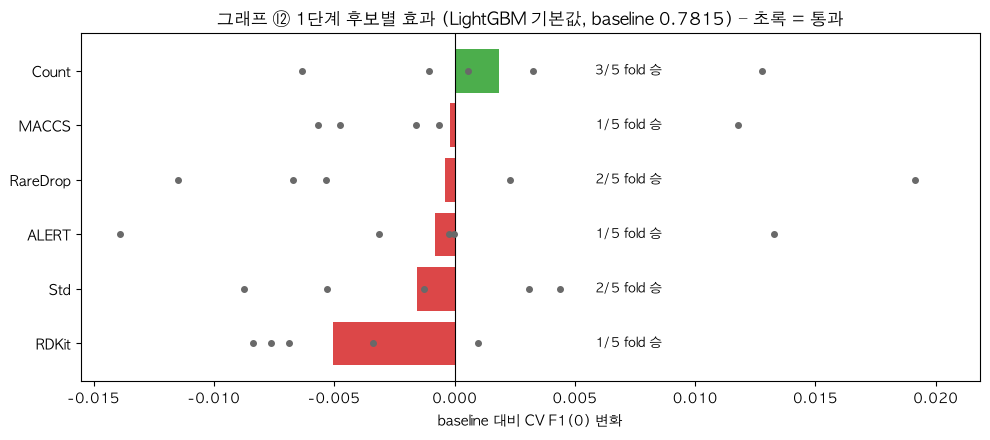

In [21]:
d = screen.iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 4.5))
colors = ["#2ca02c" if p else ("#8da0cb" if v > 0 else "#d62728") for p, v in zip(d["통과"], d["Δ평균"])]
ax.barh(d["후보"], d["Δ평균"], color=colors, alpha=0.85)
for i, k in enumerate(d["후보"]):
    diff = S1[k]["cv_scores"] - base_folds
    ax.scatter(diff, np.full(len(diff), i), s=16, color="dimgray", zorder=3)
    ax.text(max(d["Δ평균"].max(), 0) + 0.004, i, f"{d['이긴 fold'].iloc[i]}/5 fold 승", va="center", fontsize=9)
ax.axvline(0, color="k", lw=0.8)
ax.set_xlabel("baseline 대비 CV F1(0) 변화"); ax.set_xlim(right=max(d["Δ평균"].max(), 0) + 0.02)
ax.set_title(f"그래프 ⑫ 1단계 후보별 효과 (LightGBM 기본값, baseline {S1['baseline']['CV_F1_0']:.4f}) – 초록 = 통과")
plt.tight_layout(); save_fig("12_1단계_후보별효과"); plt.show()

### 9-3. 2단계 – 통과 항목의 모든 조합 × Voting4 + TH

조합마다 하는 일:
1. 학습용 80%에서 5-fold로 VotingClassifier(soft, 튜닝 파라미터 4개 모델)를 학습해 **fold 밖 예측 확률(OOF)** 을 구함
2. OOF로 threshold 0.5일 때와, **라벨 0 F1이 최대가 되는 threshold(TH)** 의 CV F1(0)을 계산
3. Hold-out 20%로 두 경우를 확인
4. **전체 train으로 재학습** → predict_input에 TH 적용 → `outputs/output_baseline+….csv` 저장

판정 규칙: 독성 있음 확률 ≥ TH 이면 0, 아니면 1. (TH = 0.5이면 기존과 동일)
fold 학습 때 모델별 확률도 저장해 3단계 Stacking에 재사용합니다 (추가 학습 없음).

In [22]:
TH_GRID = np.round(np.arange(0.30, 0.601, 0.01), 2)
VERSIONS, CURVES, STORE = [], {}, {}
X_tr_idx, X_te_idx = train_test_split(np.arange(len(y)), test_size=0.2, stratify=y, random_state=SEED)
y_tr_, y_te_ = y.iloc[X_tr_idx].values, y.iloc[X_te_idx].values
FOLDS = list(CV.split(X_tr_idx, y_tr_))

def make_voting():
    return VotingClassifier([(n, SEARCH[n][0](**BEST_PARAMS[n])) for n in SEARCH], voting="soft", n_jobs=1)

def member_proba(vc, X):
    """VotingClassifier 안의 모델별 독성 있음(0) 확률 → (n, 4)"""
    return np.column_stack([est.predict_proba(X)[:, 0] for est in vc.estimators_])

def f1_at(p0, y_true, th):
    return f1_score(y_true, np.where(p0 >= th, 0, 1), pos_label=0)

def fold_scores(p0_oof, th):
    return np.array([f1_at(p0_oof[va], y_tr_[va], th) for _, va in FOLDS])

def run_version(items):
    name = version_name(items, "+TH")          # Voting4는 baseline에 포함되어 있어 파일명에서 생략
    feats = build_feats(items)
    Xf, Xp = X_ext[feats], X_pred_ext[feats]
    Xtr, Xte = Xf.iloc[X_tr_idx], Xf.iloc[X_te_idx]
    t0 = time.time()
    # 1) 5-fold OOF (모델별 확률 저장)
    oof_m = np.zeros((len(X_tr_idx), len(SEARCH)))
    for k, (tr, va) in enumerate(FOLDS, start=1):
        vc = make_voting().fit(Xtr.iloc[tr], y_tr_[tr])
        oof_m[va] = member_proba(vc, Xtr.iloc[va])
        print(f"  {name}: fold {k}/5 완료 ({time.time()-t0:.0f}s)")
    oof = oof_m.mean(axis=1)
    # 2) threshold
    curve = np.array([fold_scores(oof, th).mean() for th in TH_GRID])
    th = float(TH_GRID[curve.argmax()])
    cv05, cvth = fold_scores(oof, 0.5), fold_scores(oof, th)
    # 3) Hold-out
    vc = make_voting().fit(Xtr, y_tr_)
    te_m = member_proba(vc, Xte); te = te_m.mean(axis=1)
    # 4) 전체 train 재학습 → predict
    vc_full = make_voting().fit(Xf, y)
    pr_m = member_proba(vc_full, Xp); pr = pr_m.mean(axis=1)
    pred = np.where(pr >= th, 0, 1)
    sub = pd.read_csv(SAMPLE_PATH); sub["output"] = pred
    assert list(sub.columns) == ["SMILES", "output"] and len(sub) == len(predict)
    sub.to_csv(f"{OUT_DIR}/output_{name}.csv", index=False)

    STORE[name] = dict(items=items, feats=feats, oof_m=oof_m, te_m=te_m, pr_m=pr_m)
    CURVES[name] = curve
    rec = {"version": name, "n_features": len(feats), "TH": th,
           "CV_F1_0@0.5": cv05.mean(), "CV_F1_0@TH": cvth.mean(), "CV_std@TH": cvth.std(),
           "Holdout_F1_0@0.5": f1_at(te, y_te_, 0.5), "Holdout_F1_0@TH": f1_at(te, y_te_, th),
           "Recall_0@TH": ((te >= th) & (y_te_ == 0)).sum() / (y_te_ == 0).sum(),
           "pred_0_rate": (pred == 0).mean(), "cv_scores": cvth, "cv_scores05": cv05,
           "time_s": round(time.time() - t0)}
    VERSIONS.append(rec)
    print(f"▶ {name} | TH {th:.2f} | CV F1(0) {rec['CV_F1_0@0.5']:.4f} → {rec['CV_F1_0@TH']:.4f} | "
          f"Hold-out {rec['Holdout_F1_0@0.5']:.4f} → {rec['Holdout_F1_0@TH']:.4f} | {rec['time_s']}s → 저장 완료")
    return rec

COMBOS = [list(c) for r in range(len(PASSED) + 1) for c in itertools.combinations(PASSED, r)]
print(f"조합 {len(COMBOS)}개 (예상 약 {len(COMBOS) * 6}분):", [version_name(c, "+TH") for c in COMBOS])
for items in COMBOS:
    run_version(items)

조합 2개 (예상 약 12분): ['baseline+TH', 'baseline+Count+TH']
  baseline+TH: fold 1/5 완료 (47s)
  baseline+TH: fold 2/5 완료 (95s)
  baseline+TH: fold 3/5 완료 (145s)
  baseline+TH: fold 4/5 완료 (193s)
  baseline+TH: fold 5/5 완료 (240s)
▶ baseline+TH | TH 0.32 | CV F1(0) 0.7850 → 0.7965 | Hold-out 0.7702 → 0.7973 | 347s → 저장 완료
  baseline+Count+TH: fold 1/5 완료 (42s)
  baseline+Count+TH: fold 2/5 완료 (85s)
  baseline+Count+TH: fold 3/5 완료 (127s)
  baseline+Count+TH: fold 4/5 완료 (169s)
  baseline+Count+TH: fold 5/5 완료 (213s)
▶ baseline+Count+TH | TH 0.41 | CV F1(0) 0.7869 → 0.7948 | Hold-out 0.7739 → 0.7915 | 314s → 저장 완료


#### 그래프 ⑬ 2단계 – 버전별 성능 (threshold 조정 전/후)

막대 = CV F1(0) (회색 = threshold 0.5, 파랑 = 조정 후), 점 = fold별 점수, ◆ = Hold-out F1(0) (조정 후).

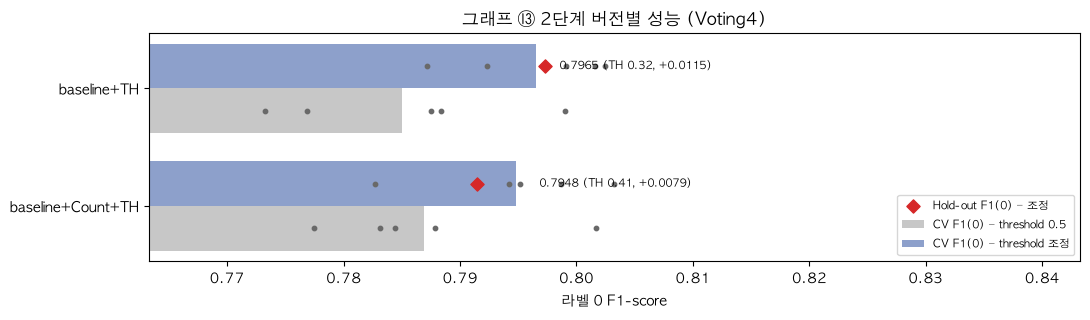

In [23]:
vt = pd.DataFrame(VERSIONS).sort_values("CV_F1_0@TH")
fig, ax = plt.subplots(figsize=(11, 0.9 * len(vt) + 1.5))
pos = np.arange(len(vt)); h = 0.38
ax.barh(pos - h/2, vt["CV_F1_0@0.5"], h, color="#c7c7c7", label="CV F1(0) – threshold 0.5")
ax.barh(pos + h/2, vt["CV_F1_0@TH"], h, color="#8da0cb", label="CV F1(0) – threshold 조정")
for p, s5, st in zip(pos, vt["cv_scores05"], vt["cv_scores"]):
    ax.scatter(s5, np.full(5, p - h/2), s=10, color="dimgray", zorder=3)
    ax.scatter(st, np.full(5, p + h/2), s=10, color="dimgray", zorder=3)
ax.scatter(vt["Holdout_F1_0@TH"], pos + h/2, marker="D", s=45, color="#d62728", zorder=4, label="Hold-out F1(0) – 조정")
for p, a, b, th in zip(pos, vt["CV_F1_0@0.5"], vt["CV_F1_0@TH"], vt["TH"]):
    ax.text(b + 0.002, p + h/2, f"{b:.4f} (TH {th:.2f}, {b - a:+.4f})", va="center", fontsize=8)
ax.set_yticks(pos, vt["version"])
allv = np.concatenate([np.concatenate(vt["cv_scores05"].values), np.concatenate(vt["cv_scores"].values), vt["Holdout_F1_0@TH"]])
ax.set_xlim(allv.min() - 0.01, allv.max() + 0.04)
ax.set_xlabel("라벨 0 F1-score"); ax.legend(loc="lower right", fontsize=8)
ax.set_title("그래프 ⑬ 2단계 버전별 성능 (Voting4)")
plt.tight_layout(); save_fig("13_2단계_버전별성능"); plt.show()

#### 그래프 ⑭ threshold 곡선

threshold를 바꿀 때 CV F1(0)이 어떻게 변하는지 봅니다. 곡선이 완만하면 기준값을 조금 다르게 잡아도 점수가 안정적입니다.

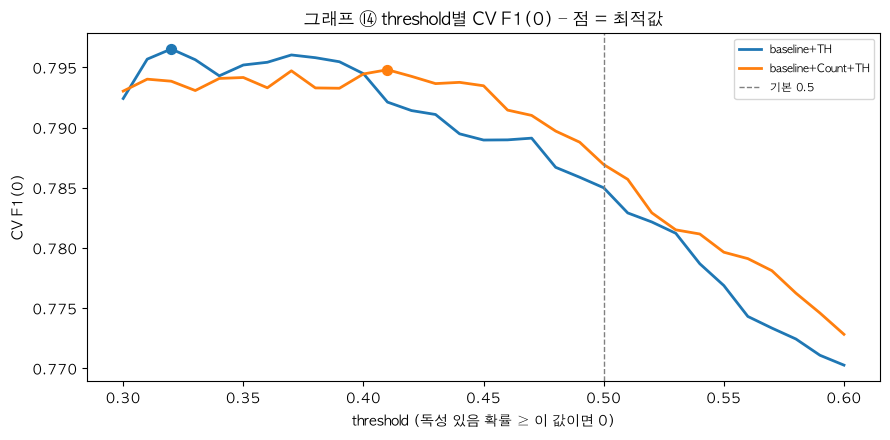

In [24]:
fig, ax = plt.subplots(figsize=(9, 4.5))
for name, curve in CURVES.items():
    line, = ax.plot(TH_GRID, curve, lw=2, label=name)
    i = curve.argmax(); ax.scatter(TH_GRID[i], curve[i], s=50, color=line.get_color(), zorder=3)
ax.axvline(0.5, color="gray", ls="--", lw=1, label="기본 0.5")
ax.set_xlabel("threshold (독성 있음 확률 ≥ 이 값이면 0)"); ax.set_ylabel("CV F1(0)")
ax.set_title("그래프 ⑭ threshold별 CV F1(0) – 점 = 최적값"); ax.legend(fontsize=8)
plt.tight_layout(); save_fig("14_threshold_곡선"); plt.show()

### 9-4. 3단계 – 최고 조합에서 Voting4 vs Stack

- **Voting4**: 4개 모델 확률을 똑같이 평균
- **Stack**: 2단계에서 저장한 모델별 fold 밖 확률(OOF)로 LogisticRegression이 **모델별 가중치**를 학습
  - Stack의 CV 점수는 OOF 위에서 다시 5-fold로 메타 모델을 검증해 계산 (메타 모델이 자기 학습 데이터로 평가받지 않도록)
- 추가 모델 학습 없이 2단계 결과를 재사용하므로 금방 끝납니다.

최고 조합: baseline+TH
Stack 메타 모델 가중치 (클수록 그 모델 의견을 더 반영): {'RF': 2.91, 'XGBoost': 1.9, 'LightGBM': 0.11, 'CatBoost': 0.9}


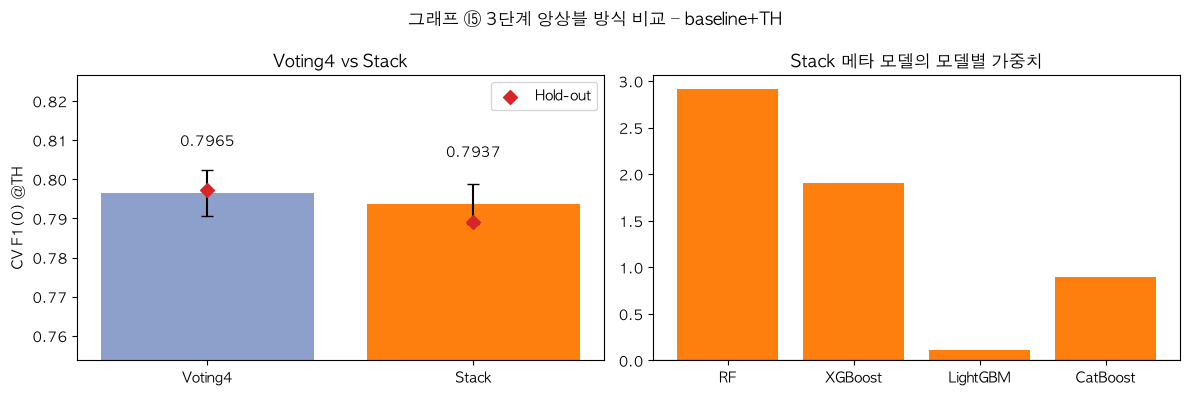

Voting4가 같거나 더 높음 → Stack 파일은 만들지 않음


,방식,TH,CV_F1_0@TH,CV_std,Holdout_F1_0@TH
0,Voting4,0.32,0.7965,0.0059,0.7973
1,Stack,0.34,0.7937,0.0051,0.7891


In [25]:
best_v = max(VERSIONS, key=lambda r: r["CV_F1_0@TH"])["version"]
S = STORE[best_v]
meta = LogisticRegression(C=1.0, max_iter=1000)
# 메타 모델 입력 = 모델별 '독성 있음' 확률, 타깃 = 라벨 0 여부
stack_oof = np.zeros(len(y_tr_))
for tr, va in FOLDS:
    m_ = clone(meta).fit(S["oof_m"][tr], (y_tr_[tr] == 0).astype(int))
    stack_oof[va] = m_.predict_proba(S["oof_m"][va])[:, 1]
curve_s = np.array([fold_scores(stack_oof, th).mean() for th in TH_GRID])
th_s = float(TH_GRID[curve_s.argmax()])
meta_tr = clone(meta).fit(S["oof_m"], (y_tr_ == 0).astype(int))
te_s = meta_tr.predict_proba(S["te_m"])[:, 1]

vote_rec = next(r for r in VERSIONS if r["version"] == best_v)
stack_cv = fold_scores(stack_oof, th_s)
cmp = pd.DataFrame([
    {"방식": "Voting4", "TH": vote_rec["TH"], "CV_F1_0@TH": vote_rec["CV_F1_0@TH"], "CV_std": vote_rec["CV_std@TH"],
     "Holdout_F1_0@TH": vote_rec["Holdout_F1_0@TH"]},
    {"방식": "Stack", "TH": th_s, "CV_F1_0@TH": stack_cv.mean(), "CV_std": stack_cv.std(),
     "Holdout_F1_0@TH": f1_at(te_s, y_te_, th_s)},
])
w = pd.Series(meta_tr.coef_[0], index=list(SEARCH))
print("최고 조합:", best_v); print("Stack 메타 모델 가중치 (클수록 그 모델 의견을 더 반영):", w.round(2).to_dict())

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar(cmp["방식"], cmp["CV_F1_0@TH"], yerr=cmp["CV_std"], capsize=4, color=["#8da0cb", "#ff7f0e"])
ax[0].scatter(cmp["방식"], cmp["Holdout_F1_0@TH"], marker="D", s=50, color="#d62728", zorder=3, label="Hold-out")
for i, v in enumerate(cmp["CV_F1_0@TH"]): ax[0].text(i, v + 0.012, f"{v:.4f}", ha="center")
ax[0].set_ylim(cmp["CV_F1_0@TH"].min() - 0.04, cmp["CV_F1_0@TH"].max() + 0.03); ax[0].set_ylabel("CV F1(0) @TH")
ax[0].legend(); ax[0].set_title("Voting4 vs Stack")
ax[1].bar(w.index, w.values, color="#ff7f0e"); ax[1].axhline(0, color="k", lw=0.8)
ax[1].set_title("Stack 메타 모델의 모델별 가중치")
plt.suptitle(f"그래프 ⑮ 3단계 앙상블 방식 비교 – {best_v}"); plt.tight_layout(); save_fig("15_3단계_Voting_vs_Stack"); plt.show()

if cmp.loc[1, "CV_F1_0@TH"] > cmp.loc[0, "CV_F1_0@TH"]:
    meta_full = clone(meta).fit(S["oof_m"], (y_tr_ == 0).astype(int))
    pr_s = meta_full.predict_proba(S["pr_m"])[:, 1]
    pred_s = np.where(pr_s >= th_s, 0, 1)
    stack_name = best_v.replace("+TH", "+Stack+TH")
    sub = pd.read_csv(SAMPLE_PATH); sub["output"] = pred_s
    sub.to_csv(f"{OUT_DIR}/output_{stack_name}.csv", index=False)
    VERSIONS.append({"version": stack_name, "n_features": len(S["feats"]), "TH": th_s,
                     "CV_F1_0@0.5": fold_scores(stack_oof, 0.5).mean(), "CV_F1_0@TH": stack_cv.mean(),
                     "CV_std@TH": stack_cv.std(), "Holdout_F1_0@0.5": f1_at(te_s, y_te_, 0.5),
                     "Holdout_F1_0@TH": f1_at(te_s, y_te_, th_s),
                     "Recall_0@TH": ((te_s >= th_s) & (y_te_ == 0)).sum() / (y_te_ == 0).sum(),
                     "pred_0_rate": (pred_s == 0).mean(), "cv_scores": stack_cv,
                     "cv_scores05": fold_scores(stack_oof, 0.5), "time_s": 0})
    print(f"Stack이 더 높음 → {OUT_DIR}/output_{stack_name}.csv 저장")
else:
    print("Voting4가 같거나 더 높음 → Stack 파일은 만들지 않음")
cmp.round(4)

### 9-5. 버전 기록 및 최종 제출 파일

- 모든 버전을 `outputs/버전_기록.csv`에 저장합니다 (baseline 포함).
- **CV F1(0) @TH가 가장 높은 버전**을 `predict_output_김정인.csv`로 복사합니다.
- 다른 버전을 제출하려면 `outputs/`에서 해당 파일을 `predict_output_김정인.csv`로 복사하면 됩니다.

In [26]:
base_rec = results_table(["E6 Voting(4)"]).iloc[0]
log = pd.DataFrame([{"version": "baseline", "n_features": base_rec["n_features"], "TH": 0.5,
                     "CV_F1_0@0.5": base_rec["CV_F1_0"], "CV_F1_0@TH": base_rec["CV_F1_0"],
                     "CV_std@TH": base_rec["CV_F1_0_std"], "Holdout_F1_0@0.5": base_rec["F1_0"],
                     "Holdout_F1_0@TH": base_rec["F1_0"], "Recall_0@TH": base_rec["Recall_0"],
                     "pred_0_rate": (pd.read_csv(f"{OUT_DIR}/output_baseline.csv")["output"] == 0).mean()}]
                   + [{k: v for k, v in r.items() if k not in ("cv_scores", "cv_scores05")} for r in VERSIONS])
log["file"] = "output_" + log["version"] + ".csv"
log = log.sort_values("CV_F1_0@TH", ascending=False).reset_index(drop=True)
log.to_csv(f"{OUT_DIR}/버전_기록.csv", index=False, encoding="utf-8-sig")

best_file = log.loc[0, "file"]
shutil.copy(f"{OUT_DIR}/{best_file}", SUBMIT_PATH)
print(f"최고 버전: {log.loc[0, 'version']} → {SUBMIT_PATH} 로 복사")
print("outputs/ 파일:", sorted(os.listdir(OUT_DIR)))
log.drop(columns="time_s", errors="ignore").round(4)

최고 버전: baseline+TH → predict_output_김정인.csv 로 복사
outputs/ 파일: ['output_baseline+Count+TH.csv', 'output_baseline+TH.csv', 'output_baseline.csv', '버전_기록.csv']


,version,n_features,TH,CV_F1_0@0.5,CV_F1_0@TH,CV_std@TH,Holdout_F1_0@0.5,Holdout_F1_0@TH,Recall_0@TH,pred_0_rate,file
0,baseline+TH,3030,0.32,0.7850,0.7965,0.0059,0.7702,0.7973,0.8555,0.5221,output_baseline+TH.csv
1,baseline+Count+TH,3030,0.41,0.7869,0.7948,0.0068,0.7739,0.7915,0.8055,0.4822,output_baseline+Count+TH.csv
2,baseline,3030,0.50,0.7850,0.7850,0.0091,0.7702,0.7702,0.7464,0.4542,output_baseline.csv


#### 그래프 ⑯ baseline → 최종 버전 변화

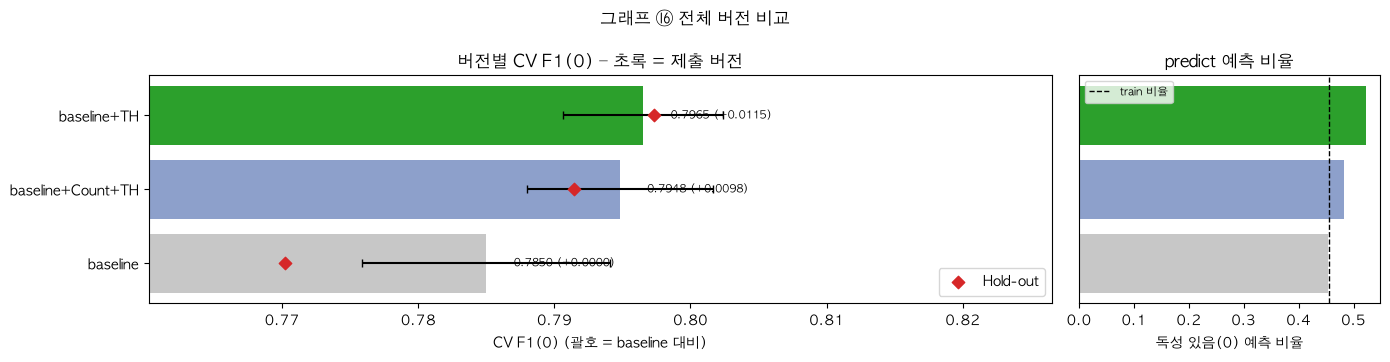

In [27]:
d = log.iloc[::-1]
fig, ax = plt.subplots(1, 2, figsize=(14, 0.55 * len(d) + 2), gridspec_kw={"width_ratios": [3, 1]})
colors = ["#2ca02c" if v == log.loc[0, "version"] else ("#c7c7c7" if v == "baseline" else "#8da0cb") for v in d["version"]]
ax[0].barh(d["version"], d["CV_F1_0@TH"], xerr=d["CV_std@TH"], color=colors, capsize=3)
ax[0].scatter(d["Holdout_F1_0@TH"], d["version"], marker="D", s=40, color="#d62728", zorder=3, label="Hold-out")
for i, v in enumerate(d["CV_F1_0@TH"]):
    ax[0].text(v + 0.002, i, f"{v:.4f} ({v - base_rec['CV_F1_0']:+.4f})", va="center", fontsize=8)
lo = min(d["CV_F1_0@TH"].min(), d["Holdout_F1_0@TH"].min())
ax[0].set_xlim(lo - 0.01, d["CV_F1_0@TH"].max() + 0.03)
ax[0].set_xlabel("CV F1(0) (괄호 = baseline 대비)"); ax[0].legend(loc="lower right"); ax[0].set_title("버전별 CV F1(0) – 초록 = 제출 버전")
ax[1].barh(d["version"], d["pred_0_rate"], color=colors); ax[1].axvline(1 - y.mean(), color="k", ls="--", lw=1, label="train 비율")
ax[1].set_yticks([]); ax[1].set_xlabel("독성 있음(0) 예측 비율"); ax[1].legend(fontsize=8); ax[1].set_title("predict 예측 비율")
plt.suptitle("그래프 ⑯ 전체 버전 비교"); plt.tight_layout(); save_fig("16_전체버전_비교"); plt.show()

### 9-6. 리더보드 기준(라벨 1 F1)으로 threshold 다시 고르기

리더보드 점수를 역산해 보니 F1은 **라벨 1(독성 없음, Positive)** 기준입니다 (`f1_score` 기본값 `pos_label=1`).
9-3의 TH는 라벨 0 F1 기준이라 독성 판정을 늘렸고, 이는 라벨 1 F1에는 불리할 수 있습니다.

- **재학습 없음**: 9-3에서 저장한 확률(`STORE`)을 그대로 사용
- threshold는 **train CV(OOF)로만** 고릅니다. 곡선을 3칸 이동평균으로 매끄럽게 한 뒤 최댓값 → 우연히 튄 점을 피함
- 판정 규칙: 독성 없음 확률 ≥ TH1 이면 1, 아니면 0
- 파일: `output_baseline+TH1.csv`, `output_baseline+Count+TH1.csv` (+ 비교용 `output_baseline+Count.csv`)
- 모든 버전을 **라벨 1 F1**로 비교해 최고 버전을 `predict_output_김정인.csv`로 복사, 기록은 `outputs/버전_기록_라벨1.csv`

In [28]:
TH1_GRID = np.round(np.arange(0.30, 0.701, 0.01), 2)

def f1_1(y_true, pred):                       # 리더보드 기준: 라벨 1 F1
    return f1_score(y_true, pred, pos_label=1)

def folds_f1_1(pred_oof):
    return np.array([f1_1(y_tr_[va], pred_oof[va]) for _, va in FOLDS])

V1, CURVES1 = [], {}
for key, S in STORE.items():                  # key: baseline+TH, baseline+Count+TH
    base = key.replace("+TH", "")             # baseline, baseline+Count
    p0_oof, p0_te, p0_pr = S["oof_m"].mean(1), S["te_m"].mean(1), S["pr_m"].mean(1)
    p1_oof, p1_te, p1_pr = 1 - p0_oof, 1 - p0_te, 1 - p0_pr

    curve = np.array([folds_f1_1(np.where(p1_oof >= t, 1, 0)).mean() for t in TH1_GRID])
    smooth = pd.Series(curve).rolling(3, center=True, min_periods=1).mean().values
    th1 = float(TH1_GRID[smooth.argmax()])
    CURVES1[base] = (curve, smooth, th1)
    th0 = next(r["TH"] for r in VERSIONS if r["version"] == key)     # 9-3에서 고른 라벨 0 기준 TH

    # (버전 이름, 판정 함수, 기준 설명)
    rules = [(base,          lambda p1: np.where(p1 >= 0.5, 1, 0),        "0.5"),
             (key,           lambda p1: np.where(1 - p1 >= th0, 0, 1),    f"라벨0 TH {th0:.2f}"),
             (base + "+TH1", lambda p1: np.where(p1 >= th1, 1, 0),        f"라벨1 TH {th1:.2f}")]
    for vname, rule, desc in rules:
        cv = folds_f1_1(rule(p1_oof))
        pred_te, pred_pr = rule(p1_te), rule(p1_pr)
        fname = f"output_{vname}.csv"
        if not os.path.exists(f"{OUT_DIR}/{fname}") or vname.endswith("+TH1"):
            sub = pd.read_csv(SAMPLE_PATH); sub["output"] = pred_pr
            sub.to_csv(f"{OUT_DIR}/{fname}", index=False)
        saved = pd.read_csv(f"{OUT_DIR}/{fname}")["output"].values
        V1.append({"version": vname, "기준": desc, "CV_F1_1": cv.mean(), "CV_F1_1_std": cv.std(),
                   "Holdout_F1_1": f1_1(y_te_, pred_te), "Holdout_F1_0": f1_score(y_te_, pred_te, pos_label=0),
                   "Holdout_Acc": accuracy_score(y_te_, pred_te), "pred_1_rate": (saved == 1).mean(),
                   "cv_scores": cv, "file": fname})
    print(f"{base}: 라벨1 최적 TH1 = {th1:.2f} (라벨0 기준 TH는 {th0:.2f})")

v1 = pd.DataFrame(V1).drop_duplicates("version").sort_values("CV_F1_1", ascending=False).reset_index(drop=True)
v1.drop(columns="cv_scores").to_csv(f"{OUT_DIR}/버전_기록_라벨1.csv", index=False, encoding="utf-8-sig")
v1.drop(columns="cv_scores").round(4)

baseline: 라벨1 최적 TH1 = 0.38 (라벨0 기준 TH는 0.32)
baseline+Count: 라벨1 최적 TH1 = 0.40 (라벨0 기준 TH는 0.41)


,version,기준,CV_F1_1,CV_F1_1_std,Holdout_F1_1,Holdout_F1_0,Holdout_Acc,pred_1_rate,file
0,baseline+Count+TH1,라벨1 TH 0.40,0.8322,0.0061,0.8173,0.7475,0.7880,0.5944,output_baseline+Count+TH1.csv
1,baseline+TH1,라벨1 TH 0.38,0.8297,0.0070,0.8178,0.7415,0.7862,0.5955,output_baseline+TH1.csv
2,baseline+Count,0.5,0.8286,0.0075,0.8188,0.7739,0.7988,0.5545,output_baseline+Count.csv
3,baseline,0.5,0.8274,0.0070,0.8182,0.7702,0.7970,0.5458,output_baseline.csv
4,baseline+Count+TH,라벨0 TH 0.41,0.8221,0.0072,0.8197,0.7915,0.8066,0.5178,output_baseline+Count+TH.csv
5,baseline+TH,라벨0 TH 0.32,0.8059,0.0073,0.8061,0.7973,0.8018,0.4779,output_baseline+TH.csv


#### 그래프 ⑰ threshold별 CV 라벨 1 F1

실선 = 그대로의 곡선, 점선 = 3칸 이동평균, 점 = 고른 TH1. 회색 점선 = 기본 0.5.

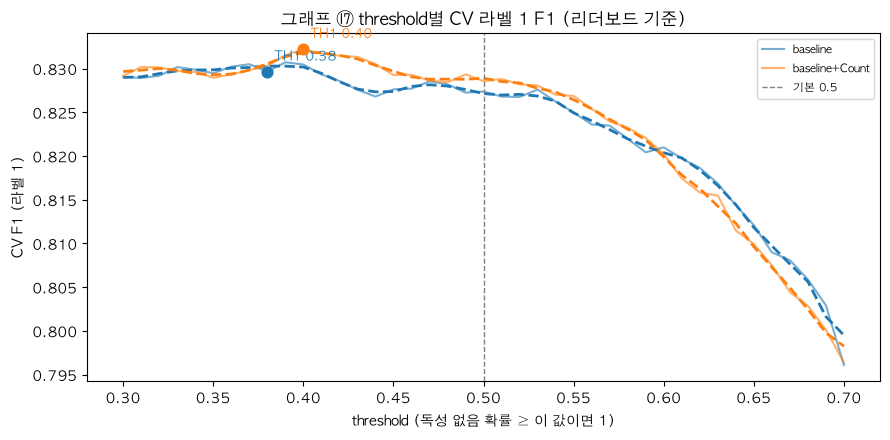

In [29]:
fig, ax = plt.subplots(figsize=(9, 4.5))
for base, (curve, smooth, th1) in CURVES1.items():
    line, = ax.plot(TH1_GRID, curve, lw=1.5, alpha=0.6, label=f"{base}")
    ax.plot(TH1_GRID, smooth, lw=2, ls="--", color=line.get_color())
    i = list(TH1_GRID).index(th1)
    ax.scatter(th1, curve[i], s=60, color=line.get_color(), zorder=3)
    ax.annotate(f"TH1 {th1:.2f}", (th1, curve[i]), textcoords="offset points", xytext=(5, 8), fontsize=9, color=line.get_color())
ax.axvline(0.5, color="gray", ls="--", lw=1, label="기본 0.5")
ax.set_xlabel("threshold (독성 없음 확률 ≥ 이 값이면 1)"); ax.set_ylabel("CV F1 (라벨 1)")
ax.set_title("그래프 ⑰ threshold별 CV 라벨 1 F1 (리더보드 기준)"); ax.legend(fontsize=8)
plt.tight_layout(); save_fig("17_threshold_곡선_라벨1"); plt.show()

#### 그래프 ⑱ 전체 버전 비교 – 라벨 1 F1 (리더보드 기준)

왼쪽: 막대 = CV F1(1) ± std, 점 = fold별, ◆ = Hold-out F1(1). 오른쪽: predict에서 독성 없음(1)으로 판정한 비율.

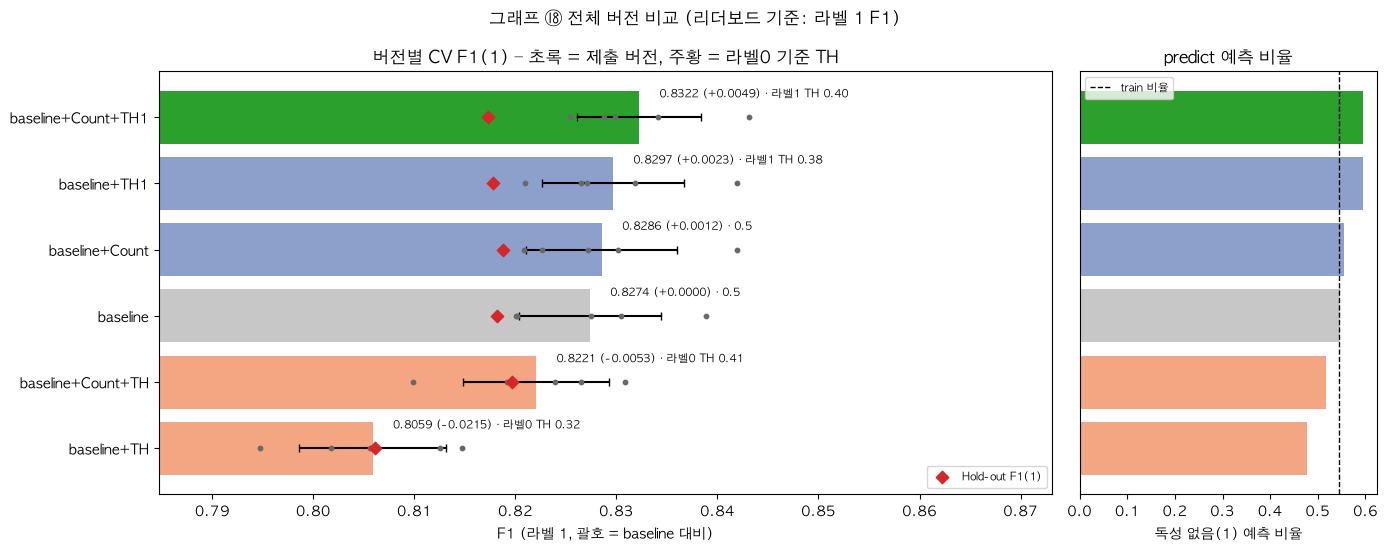

라벨 1 F1 최고: baseline+Count+TH1 (CV F1(1) 0.8322) → predict_output_김정인.csv 로 복사
outputs/ 파일: ['output_baseline+Count+TH.csv', 'output_baseline+Count+TH1.csv', 'output_baseline+Count.csv', 'output_baseline+TH.csv', 'output_baseline+TH1.csv', 'output_baseline.csv', '버전_기록.csv', '버전_기록_라벨1.csv']


In [30]:
d = v1.iloc[::-1].reset_index(drop=True)
best1 = v1.loc[0, "version"]
colors = ["#2ca02c" if v == best1 else ("#c7c7c7" if v == "baseline" else
          ("#f4a582" if v.endswith("+TH") else "#8da0cb")) for v in d["version"]]
fig, ax = plt.subplots(1, 2, figsize=(14, 0.6 * len(d) + 2), gridspec_kw={"width_ratios": [3, 1]})
pos = np.arange(len(d))
ax[0].barh(pos, d["CV_F1_1"], xerr=d["CV_F1_1_std"], color=colors, capsize=3)
for p, s in zip(pos, d["cv_scores"]):
    ax[0].scatter(s, np.full(len(s), p), s=10, color="dimgray", zorder=3)
ax[0].scatter(d["Holdout_F1_1"], pos, marker="D", s=40, color="#d62728", zorder=4, label="Hold-out F1(1)")
base_cv = v1.set_index("version").loc["baseline", "CV_F1_1"]
for p, v, desc in zip(pos, d["CV_F1_1"], d["기준"]):
    ax[0].text(v + 0.002, p + 0.3, f"{v:.4f} ({v - base_cv:+.4f}) · {desc}", fontsize=8)
ax[0].set_yticks(pos, d["version"])
allv = np.concatenate([np.concatenate(d["cv_scores"].values), d["Holdout_F1_1"].values])
ax[0].set_xlim(allv.min() - 0.01, allv.max() + 0.03)
ax[0].set_xlabel("F1 (라벨 1, 괄호 = baseline 대비)"); ax[0].legend(loc="lower right", fontsize=8)
ax[0].set_title("버전별 CV F1(1) – 초록 = 제출 버전, 주황 = 라벨0 기준 TH")
ax[1].barh(pos, d["pred_1_rate"], color=colors); ax[1].axvline(y.mean(), color="k", ls="--", lw=1, label="train 비율")
ax[1].set_yticks([]); ax[1].set_xlabel("독성 없음(1) 예측 비율"); ax[1].legend(fontsize=8)
ax[1].set_title("predict 예측 비율")
plt.suptitle("그래프 ⑱ 전체 버전 비교 (리더보드 기준: 라벨 1 F1)"); plt.tight_layout(); save_fig("18_전체버전_비교_라벨1"); plt.show()

shutil.copy(f"{OUT_DIR}/{v1.loc[0, 'file']}", SUBMIT_PATH)
print(f"라벨 1 F1 최고: {best1} (CV F1(1) {v1.loc[0, 'CV_F1_1']:.4f}) → {SUBMIT_PATH} 로 복사")
print("outputs/ 파일:", sorted(os.listdir(OUT_DIR)))

### 9-7. 피처 세트 재비교 – 라벨 1 F1 (리더보드 기준)

3번(E1~E3)에서는 **라벨 0 F1**로 피처 세트를 골랐습니다 (E3 선택). 리더보드 기준인 **라벨 1 F1**로도 E3가 맞는지 확인합니다.

- 같은 80/20 분할, 같은 5-fold, threshold 0.5
- 모델: 원래 실험과 같은 **RF** + 최종 모델에 더 가까운 **LightGBM**(기본값) → 결론이 모델에 따라 달라지는지 확인
- fold별로 E1과 짝지어 비교 (같은 시험지) → 평균 차이와 **5개 fold 중 이긴 수**

In [31]:
F1_1_SCORER = make_scorer(f1_score, pos_label=1)
SCORING = {"f1_1": F1_1_SCORER, "f1_0": F1_0}
FS_MODELS = {"RF": (RandomForestClassifier, RF_BASE), "LightGBM": (LGBMClassifier, BASE_MODELS["LightGBM"][1])}

FS1 = []
for mname, (cls, params) in FS_MODELS.items():
    for i, (fs_name, cols) in enumerate(FEATURE_SETS.items(), start=1):
        t0 = time.time()
        Xtr, Xte = X_all[cols].iloc[X_tr_idx], X_all[cols].iloc[X_te_idx]
        cv_res = cross_validate(cls(**params), Xtr, y_tr_, cv=CV, scoring=SCORING, n_jobs=1)
        pred_te = cls(**params).fit(Xtr, y_tr_).predict(Xte)
        FS1.append({"모델": mname, "피처 세트": f"E{i} {fs_name}",
                    "CV_F1_1": cv_res["test_f1_1"].mean(), "CV_F1_1_std": cv_res["test_f1_1"].std(),
                    "CV_F1_0": cv_res["test_f1_0"].mean(),
                    "Holdout_F1_1": f1_score(y_te_, pred_te, pos_label=1),
                    "Holdout_F1_0": f1_score(y_te_, pred_te, pos_label=0),
                    "cv_scores": cv_res["test_f1_1"]})
        print(f"[{mname} | E{i} {fs_name}] CV F1(1) {FS1[-1]['CV_F1_1']:.4f} ± {FS1[-1]['CV_F1_1_std']:.4f} | "
              f"Hold-out F1(1) {FS1[-1]['Holdout_F1_1']:.4f} | {time.time()-t0:.0f}s")

fs1 = pd.DataFrame(FS1)
for mname in FS_MODELS:
    e1 = fs1[(fs1["모델"] == mname) & fs1["피처 세트"].str.startswith("E1")]["cv_scores"].iloc[0]
    m = fs1["모델"] == mname
    fs1.loc[m, "E1 대비"] = fs1.loc[m, "CV_F1_1"] - e1.mean()
    fs1.loc[m, "E1 대비 이긴 fold"] = fs1.loc[m, "cv_scores"].apply(lambda s: int((s > e1).sum()))
fs1.drop(columns="cv_scores").round(4)

[RF | E1 원본FP+물성] CV F1(1) 0.8138 ± 0.0055 | Hold-out F1(1) 0.8210 | 10s
[RF | E2 입체FP+물성] CV F1(1) 0.8168 ± 0.0045 | Hold-out F1(1) 0.8136 | 9s
[RF | E3 입체FP+물성+TPSA] CV F1(1) 0.8222 ± 0.0089 | Hold-out F1(1) 0.8104 | 9s
[LightGBM | E1 원본FP+물성] CV F1(1) 0.8175 ± 0.0025 | Hold-out F1(1) 0.8203 | 25s
[LightGBM | E2 입체FP+물성] CV F1(1) 0.8168 ± 0.0053 | Hold-out F1(1) 0.8114 | 25s
[LightGBM | E3 입체FP+물성+TPSA] CV F1(1) 0.8235 ± 0.0094 | Hold-out F1(1) 0.8114 | 25s


,모델,피처 세트,CV_F1_1,CV_F1_1_std,CV_F1_0,Holdout_F1_1,Holdout_F1_0,E1 대비,E1 대비 이긴 fold
0,RF,E1 원본FP+물성,0.8138,0.0055,0.7645,0.8210,0.7672,0.0000,0.0
1,RF,E2 입체FP+물성,0.8168,0.0045,0.7697,0.8136,0.7591,0.0030,4.0
2,RF,E3 입체FP+물성+TPSA,0.8222,0.0089,0.7767,0.8104,0.7565,0.0085,5.0
3,LightGBM,E1 원본FP+물성,0.8175,0.0025,0.7780,0.8203,0.7714,0.0000,0.0
4,LightGBM,E2 입체FP+물성,0.8168,0.0053,0.7741,0.8114,0.7627,-0.0006,2.0
5,LightGBM,E3 입체FP+물성+TPSA,0.8235,0.0094,0.7815,0.8114,0.7627,0.0061,4.0


#### 그래프 ⑲ 피처 세트별 CV F1(1) – RF / LightGBM

막대 = CV F1(1) ± std, 점 = fold별, ◆ = Hold-out F1(1). 오른쪽 = 같은 fold끼리 E1을 뺀 차이 (0보다 오른쪽이면 E1보다 좋음).

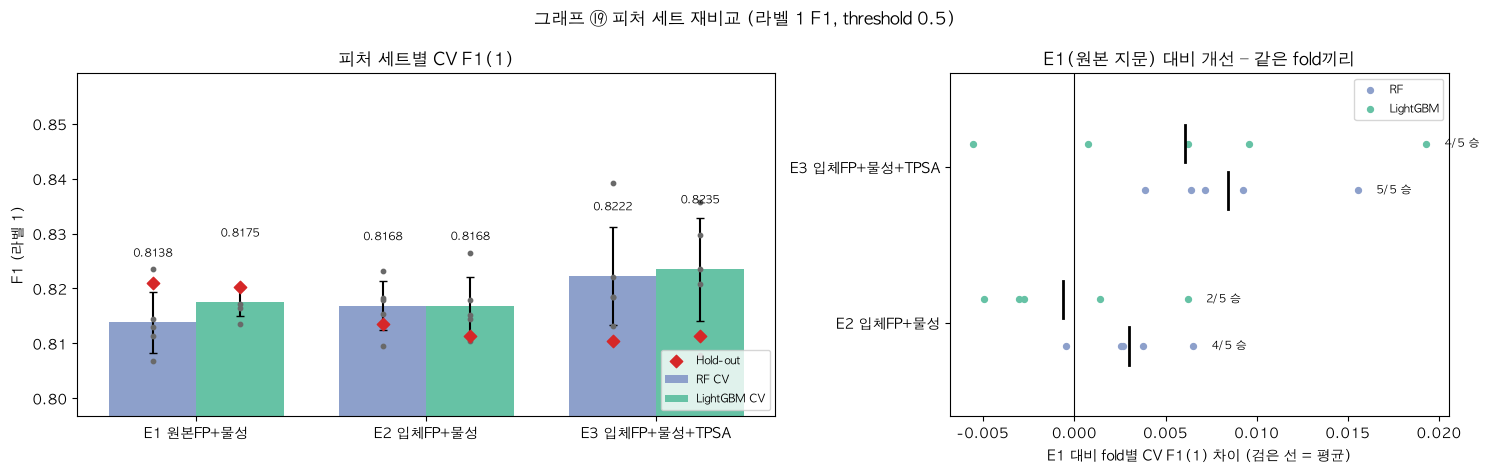

In [32]:
fs_names = list(fs1["피처 세트"].unique()); mnames = list(FS_MODELS)
fig, ax = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={"width_ratios": [1.4, 1]})
w = 0.38; x = np.arange(len(fs_names)); mcolor = {"RF": "#8da0cb", "LightGBM": "#66c2a5"}
for j, mname in enumerate(mnames):
    d = fs1[fs1["모델"] == mname].set_index("피처 세트").loc[fs_names]
    xs = x + (j - 0.5) * w
    ax[0].bar(xs, d["CV_F1_1"], w, yerr=d["CV_F1_1_std"], capsize=3, color=mcolor[mname], label=f"{mname} CV")
    for xi, s in zip(xs, d["cv_scores"]):
        ax[0].scatter(np.full(len(s), xi), s, s=10, color="dimgray", zorder=3)
    ax[0].scatter(xs, d["Holdout_F1_1"], marker="D", s=40, color="#d62728", zorder=4,
                  label="Hold-out" if j == 0 else None)
    for xi, v in zip(xs, d["CV_F1_1"]):
        ax[0].text(xi, v + 0.012, f"{v:.4f}", ha="center", fontsize=8)
allv = np.concatenate([np.concatenate(fs1["cv_scores"].values), fs1["Holdout_F1_1"].values])
ax[0].set_ylim(allv.min() - 0.01, allv.max() + 0.02)
ax[0].set_xticks(x, fs_names); ax[0].set_ylabel("F1 (라벨 1)"); ax[0].legend(fontsize=8, loc="lower right")
ax[0].set_title("피처 세트별 CV F1(1)")

for j, mname in enumerate(mnames):
    d = fs1[fs1["모델"] == mname].set_index("피처 세트").loc[fs_names]
    e1 = d["cv_scores"].iloc[0]
    for i, fs in enumerate(fs_names[1:], start=1):
        diff = d["cv_scores"].iloc[i] - e1
        yy = i + (j - 0.5) * 0.3
        ax[1].scatter(diff, np.full(len(diff), yy), s=18, color=mcolor[mname], label=mname if i == 1 else None)
        ax[1].plot([diff.mean()] * 2, [yy - 0.12, yy + 0.12], color="k", lw=2)
        ax[1].text(diff.max() + 0.001, yy, f"{int((diff > 0).sum())}/5 승", va="center", fontsize=8)
ax[1].axvline(0, color="k", lw=0.8)
ax[1].set_yticks(range(1, len(fs_names)), fs_names[1:]); ax[1].set_ylim(0.4, len(fs_names) - 0.4)
ax[1].set_xlabel("E1 대비 fold별 CV F1(1) 차이 (검은 선 = 평균)"); ax[1].legend(fontsize=8)
ax[1].set_title("E1(원본 지문) 대비 개선 – 같은 fold끼리")
plt.suptitle("그래프 ⑲ 피처 세트 재비교 (라벨 1 F1, threshold 0.5)"); plt.tight_layout()
save_fig("19_피처세트_재비교_라벨1"); plt.show()

### 9-8. 다른 종류의 모델 추가 (라벨 1 F1)

**가설**: 트리 모델 4개는 예측 상관이 0.90~0.95로 거의 같은 판단을 해서 앙상블 효과가 작았다.
**판단 방식이 완전히 다른 모델**을 섞으면 서로 다른 실수를 보완해 성능이 오를 것이다.

| 모델 | 판단 방식 | 입력 |
|---|---|---|
| **SVM** (Tanimoto 커널) | 분자 간 **지문 유사도**로 경계를 그음. 화학 QSAR의 전통적 강자 | ECFPC + FCFPC |
| **kNN** (Tanimoto) | **가장 비슷한 분자 k개**의 라벨로 예측 (EDA: 최근접 이웃 라벨 일치율 76%) | ECFPC + FCFPC |
| **MLP** (신경망) | 피처 전체를 비선형으로 조합 | baseline 피처 (연속형은 스케일링) |

- 트리 4개의 확률은 9-3에서 저장한 것(`STORE["baseline+Count+TH"]`, 현재 제출본의 트리)을 그대로 씀 → **트리 재학습 없음**
- 새 모델도 **같은 80/20 분할, 같은 5-fold**로 fold 밖 예측 확률(OOF)을 구함
- SVM의 C, kNN의 k는 후보 3개씩을 CV F1(1)로 비교해 선택
- 조합: **Voting4 + {SVM, kNN, MLP}의 모든 부분집합** (8개, 확률 단순 평균) → 각각 TH1 적용
- **교체 기준 (엄격)**: 현재 제출본(`baseline+Count+TH1`) 대비 ① CV F1(1) 평균 상승 ② 5개 fold 중 4개 이상 승 ③ Hold-out F1(1)도 같거나 상승 → **세 조건 모두** 만족할 때만 `predict_output_김정인.csv` 교체

In [33]:
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier

TAN_COLS = ECFPC + FCFPC

def tanimoto(A, B):
    """이진 지문 Tanimoto 유사도 = 공통 비트 / (A 비트 + B 비트 - 공통 비트)"""
    inter = A @ B.T
    return inter / np.maximum(A.sum(1)[:, None] + B.sum(1)[None, :] - inter, 1e-9)

class TanimotoSVC(BaseEstimator, ClassifierMixin):
    def __init__(self, cols=None, C=1.0):
        self.cols, self.C = cols, C
    def _fp(self, X):
        return np.asarray(X[self.cols], dtype=np.float32)
    def fit(self, X, y):
        self.Xfp_ = self._fp(X)
        self.svc_ = SVC(kernel="precomputed", C=self.C, probability=True, random_state=SEED)
        self.svc_.fit(tanimoto(self.Xfp_, self.Xfp_), y)
        self.classes_ = self.svc_.classes_
        return self
    def predict_proba(self, X):
        return self.svc_.predict_proba(tanimoto(self._fp(X), self.Xfp_))
    def predict(self, X):
        return self.classes_[self.predict_proba(X).argmax(1)]

class TanimotoKNN(BaseEstimator, ClassifierMixin):
    def __init__(self, cols=None, k=10):
        self.cols, self.k = cols, k
    def fit(self, X, y):
        self.Xfp_ = np.asarray(X[self.cols], dtype=np.float32); self.y_ = np.asarray(y)
        self.classes_ = np.array([0, 1])
        return self
    def predict_proba(self, X):
        S = tanimoto(np.asarray(X[self.cols], dtype=np.float32), self.Xfp_)
        top = np.argpartition(-S, self.k, axis=1)[:, :self.k]
        w = np.take_along_axis(S, top, axis=1) + 1e-6          # 유사도 가중
        p1 = (w * self.y_[top]).sum(1) / w.sum(1)
        return np.column_stack([1 - p1, p1])
    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)

def p1_oof_te_pr(make_model, feats):
    """5-fold OOF / Hold-out / 전체 train 재학습 후 predict 의 '독성 없음(1)' 확률"""
    Xf, Xp = X_ext[feats], X_pred_ext[feats]
    Xtr, Xte = Xf.iloc[X_tr_idx], Xf.iloc[X_te_idx]
    oof = np.zeros(len(X_tr_idx))
    for tr, va in FOLDS:
        oof[va] = make_model().fit(Xtr.iloc[tr], y_tr_[tr]).predict_proba(Xtr.iloc[va])[:, 1]
    te = make_model().fit(Xtr, y_tr_).predict_proba(Xte)[:, 1]
    pr = make_model().fit(Xf, y).predict_proba(Xp)[:, 1]
    return oof, te, pr

# 1) 트리 4개: 9-3에서 저장한 확률 재사용 (STORE는 '독성 있음' 확률 → 1 - p)
T = STORE["baseline+Count+TH"]
P1 = {n: (1 - T["oof_m"][:, j], 1 - T["te_m"][:, j], 1 - T["pr_m"][:, j]) for j, n in enumerate(SEARCH)}

# 2) 새 모델: 후보 하이퍼파라미터를 CV F1(1)로 비교해 선택
NEW_CANDIDATES = {
    "SVM": [(f"C={c}", (lambda c=c: TanimotoSVC(TAN_COLS, C=c)), TAN_COLS) for c in (0.5, 1.0, 2.0)],
    "kNN": [(f"k={k}", (lambda k=k: TanimotoKNN(TAN_COLS, k=k)), TAN_COLS) for k in (5, 10, 20)],
    "MLP": [("(256,64)", lambda: make_pipeline(MLPClassifier((256, 64), alpha=1e-3, early_stopping=True,
                                                             max_iter=300, random_state=SEED), FEATS, scale=True), FEATS)],
}
tune_rows = []
for name, cands in NEW_CANDIDATES.items():
    best = None
    for tag, mk, feats in cands:
        t0 = time.time()
        res = p1_oof_te_pr(mk, feats)
        cv = folds_f1_1(np.where(res[0] >= 0.5, 1, 0))
        tune_rows.append({"모델": name, "설정": tag, "CV_F1_1": cv.mean(), "CV_std": cv.std(),
                          "Holdout_F1_1": f1_1(y_te_, np.where(res[1] >= 0.5, 1, 0)), "time_s": round(time.time() - t0, 1)})
        print(f"[{name} {tag}] CV F1(1) {cv.mean():.4f} ± {cv.std():.4f} | {time.time()-t0:.0f}s")
        if best is None or cv.mean() > best[0]:
            best = (cv.mean(), tag, res)
    P1[name] = best[2]
    print(f"  → {name} 선택: {best[1]}")
pd.DataFrame(tune_rows).round(4)

[SVM C=0.5] CV F1(1) 0.7861 ± 0.0066 | 6s
[SVM C=1.0] CV F1(1) 0.8025 ± 0.0078 | 6s
[SVM C=2.0] CV F1(1) 0.8111 ± 0.0092 | 7s
  → SVM 선택: C=2.0
[kNN k=5] CV F1(1) 0.7778 ± 0.0128 | 1s
[kNN k=10] CV F1(1) 0.7697 ± 0.0142 | 1s
[kNN k=20] CV F1(1) 0.7544 ± 0.0101 | 1s
  → kNN 선택: k=5
[MLP (256,64)] CV F1(1) 0.8001 ± 0.0063 | 24s
  → MLP 선택: (256,64)


,모델,설정,CV_F1_1,CV_std,Holdout_F1_1,time_s
0,SVM,C=0.5,0.7861,0.0066,0.7771,5.5
1,SVM,C=1.0,0.8025,0.0078,0.7838,5.6
2,SVM,C=2.0,0.8111,0.0092,0.7914,6.8
3,kNN,k=5,0.7778,0.0128,0.7780,0.6
4,kNN,k=10,0.7697,0.0142,0.7684,0.6
5,kNN,k=20,0.7544,0.0101,0.7585,0.6
6,MLP,"(256,64)",0.8001,0.0063,0.7983,23.8


#### 그래프 ⑳ 모델 간 예측 상관 (OOF 기준)

트리 4개끼리는 진하게(비슷), 새 모델과 트리 사이는 **연하게(다름)** 나와야 앙상블 효과를 기대할 수 있습니다.

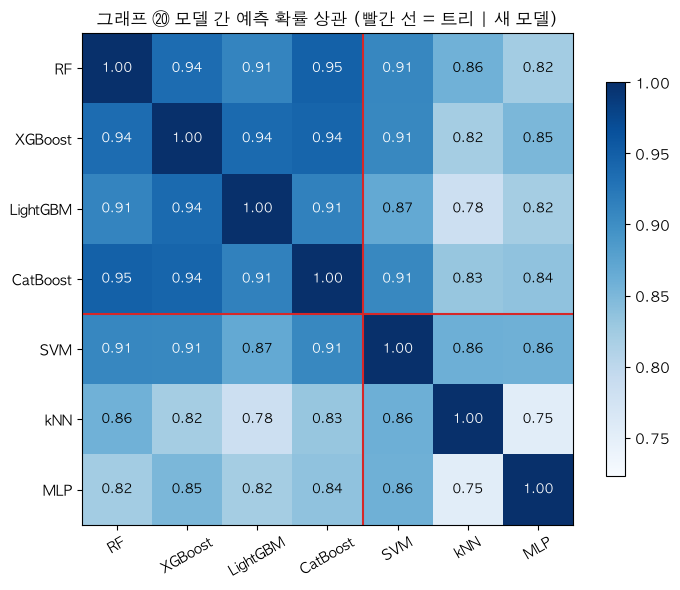

In [34]:
MODELS7 = list(SEARCH) + ["SVM", "kNN", "MLP"]
oof_df = pd.DataFrame({n: P1[n][0] for n in MODELS7})
corr7 = oof_df.corr()
fig, ax = plt.subplots(figsize=(7.5, 6))
im = ax.imshow(corr7, cmap="Blues", vmin=corr7.values.min() - 0.03, vmax=1)
ax.set_xticks(range(len(corr7)), corr7.columns, rotation=30); ax.set_yticks(range(len(corr7)), corr7.index)
for i in range(len(corr7)):
    for j in range(len(corr7)):
        ax.text(j, i, f"{corr7.iloc[i, j]:.2f}", ha="center", va="center",
                color="white" if corr7.iloc[i, j] > corr7.values.mean() else "black", fontsize=9)
ax.axhline(3.5, color="#d62728", lw=1.5); ax.axvline(3.5, color="#d62728", lw=1.5)
fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title("그래프 ⑳ 모델 간 예측 확률 상관 (빨간 선 = 트리 | 새 모델)")
plt.tight_layout(); save_fig("20_모델간_예측상관_7개"); plt.show()

#### 그래프 ㉑ 단일 모델 성능 (threshold 0.5)

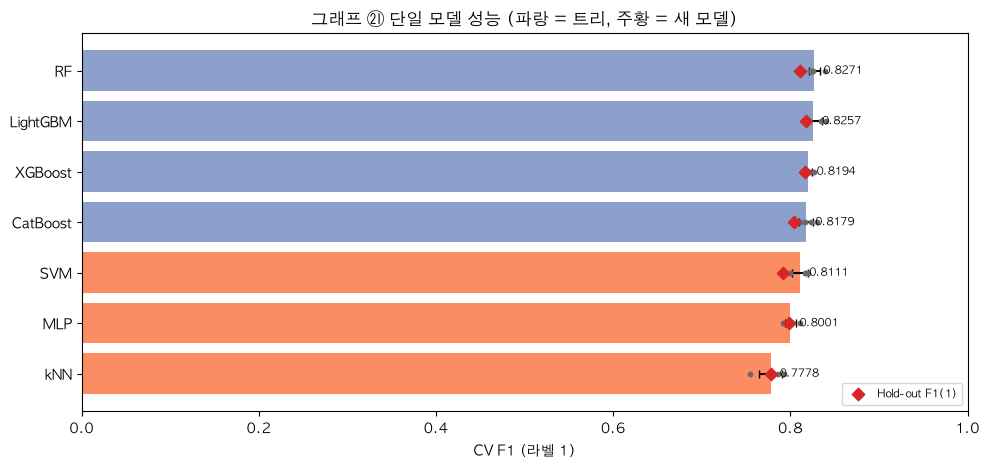

,모델,종류,CV_F1_1,CV_std,Holdout_F1_1
0,kNN,새 모델,0.7778,0.0128,0.7780
1,MLP,새 모델,0.8001,0.0063,0.7983
2,SVM,새 모델,0.8111,0.0092,0.7914
3,CatBoost,트리,0.8179,0.0081,0.8041
4,XGBoost,트리,0.8194,0.0049,0.8167
5,LightGBM,트리,0.8257,0.0098,0.8175
6,RF,트리,0.8271,0.0060,0.8111


In [35]:
single = []
for n in MODELS7:
    oof, te, _ = P1[n]
    cv = folds_f1_1(np.where(oof >= 0.5, 1, 0))
    single.append({"모델": n, "종류": "트리" if n in SEARCH else "새 모델", "CV_F1_1": cv.mean(), "CV_std": cv.std(),
                   "Holdout_F1_1": f1_1(y_te_, np.where(te >= 0.5, 1, 0)), "cv_scores": cv})
single = pd.DataFrame(single).sort_values("CV_F1_1").reset_index(drop=True)

fig, ax = plt.subplots(figsize=(10, 4.8))
pos = np.arange(len(single))
ax.barh(pos, single["CV_F1_1"], xerr=single["CV_std"], capsize=3,
        color=["#8da0cb" if k == "트리" else "#fc8d62" for k in single["종류"]])
for p, s in zip(pos, single["cv_scores"]):
    ax.scatter(s, np.full(len(s), p), s=10, color="dimgray", zorder=3)
ax.scatter(single["Holdout_F1_1"], pos, marker="D", s=40, color="#d62728", zorder=4, label="Hold-out F1(1)")
for p, v in zip(pos, single["CV_F1_1"]):
    ax.text(v + 0.01, p, f"{v:.4f}", va="center", fontsize=8)
ax.set_yticks(pos, single["모델"]); ax.legend(loc="lower right", fontsize=8)
allv = np.concatenate([np.concatenate(single["cv_scores"].values), single["Holdout_F1_1"].values])
ax.set_xlim(0, 1); ax.set_xlabel("CV F1 (라벨 1)")
ax.set_title("그래프 ㉑ 단일 모델 성능 (파랑 = 트리, 주황 = 새 모델)")
plt.tight_layout(); save_fig("21_단일모델_성능_라벨1"); plt.show()
single.drop(columns="cv_scores").round(4)

### 9-8-2. 조합: Voting4 + 새 모델 (모든 부분집합) × TH1

- 각 조합은 포함된 모델들의 '독성 없음' 확률을 **단순 평균**
- TH1은 9-6과 같은 방식 (CV 곡선 3칸 이동평균의 최댓값)
- 조합이 없는 경우(Voting4만) = 현재 제출본과 같은 계산 → CV F1(1) 0.8322가 다시 나와야 정상

In [36]:
EXTRAS = ["SVM", "kNN", "MLP"]
current = None
COMBO = []
for r in range(len(EXTRAS) + 1):
    for extra in itertools.combinations(EXTRAS, r):
        members = list(SEARCH) + list(extra)
        oof = np.mean([P1[n][0] for n in members], axis=0)
        te = np.mean([P1[n][1] for n in members], axis=0)
        pr = np.mean([P1[n][2] for n in members], axis=0)
        curve = np.array([folds_f1_1(np.where(oof >= t, 1, 0)).mean() for t in TH1_GRID])
        smooth = pd.Series(curve).rolling(3, center=True, min_periods=1).mean().values
        th1 = float(TH1_GRID[smooth.argmax()])
        cv = folds_f1_1(np.where(oof >= th1, 1, 0))
        cv05 = folds_f1_1(np.where(oof >= 0.5, 1, 0))
        vname = "baseline+Count" + "".join(f"+{e}" for e in extra) + "+TH1"
        pred = np.where(pr >= th1, 1, 0)
        if extra:     # 현재 제출본(조합 없음)은 이미 저장되어 있음
            sub = pd.read_csv(SAMPLE_PATH); sub["output"] = pred
            sub.to_csv(f"{OUT_DIR}/output_{vname}.csv", index=False)
        rec = {"version": vname, "모델 수": len(members), "TH1": th1, "CV_F1_1@0.5": cv05.mean(),
               "CV_F1_1": cv.mean(), "CV_std": cv.std(), "Holdout_F1_1": f1_1(y_te_, np.where(te >= th1, 1, 0)),
               "pred_1_rate": pred.mean(), "cv_scores": cv, "file": f"output_{vname}.csv"}
        if not extra:
            current = rec
        COMBO.append(rec)

for rec in COMBO:
    rec["현재 대비"] = rec["CV_F1_1"] - current["CV_F1_1"]
    rec["이긴 fold"] = int((rec["cv_scores"] > current["cv_scores"]).sum())
    rec["Hold-out 대비"] = rec["Holdout_F1_1"] - current["Holdout_F1_1"]
    rec["교체 조건 충족"] = bool(rec["현재 대비"] > 0 and rec["이긴 fold"] >= 4 and rec["Hold-out 대비"] >= 0)
combo = pd.DataFrame(COMBO).sort_values("CV_F1_1", ascending=False).reset_index(drop=True)
print(f"확인: 현재 제출본 재계산 CV F1(1) = {current['CV_F1_1']:.4f} (9-6에서 0.8322)")
combo.drop(columns=["cv_scores"]).to_csv(f"{OUT_DIR}/버전_기록_모델추가.csv", index=False, encoding="utf-8-sig")
combo.drop(columns=["cv_scores", "file"]).round(4)

확인: 현재 제출본 재계산 CV F1(1) = 0.8322 (9-6에서 0.8322)


,version,모델 수,TH1,CV_F1_1@0.5,CV_F1_1,CV_std,Holdout_F1_1,pred_1_rate,현재 대비,이긴 fold,Hold-out 대비,교체 조건 충족
0,baseline+Count+SVM+kNN+TH1,6,0.40,0.8294,0.8338,0.0092,0.8153,0.5922,0.0016,3,-0.0020,False
1,baseline+Count+kNN+MLP+TH1,6,0.35,0.8268,0.8334,0.0076,0.8136,0.6138,0.0011,4,-0.0037,False
2,baseline+Count+SVM+TH1,5,0.40,0.8325,0.8331,0.0084,0.8142,0.5922,0.0009,2,-0.0032,False
3,baseline+Count+MLP+TH1,5,0.35,0.8275,0.8326,0.0059,0.8147,0.6106,0.0004,3,-0.0026,False
4,baseline+Count+kNN+TH1,5,0.36,0.8289,0.8325,0.0061,0.8171,0.6149,0.0002,3,-0.0002,False
5,baseline+Count+SVM+kNN+MLP+TH1,7,0.35,0.8270,0.8324,0.0072,0.8116,0.6127,0.0002,4,-0.0057,False
6,baseline+Count+SVM+MLP+TH1,6,0.45,0.8270,0.8324,0.0060,0.8189,0.5631,0.0002,3,0.0016,False
7,baseline+Count+TH1,4,0.40,0.8286,0.8322,0.0061,0.8173,0.5944,0.0000,0,0.0000,False


#### 그래프 ㉒ 조합별 성능 – 현재 제출본 대비

왼쪽: 막대 = CV F1(1) (TH1 적용), 점 = fold별, ◆ = Hold-out. 회색 = 현재 제출본, 초록 = 교체 조건 3개 모두 충족.
오른쪽: 같은 fold끼리 현재 제출본을 뺀 차이 (검은 선 = 평균).

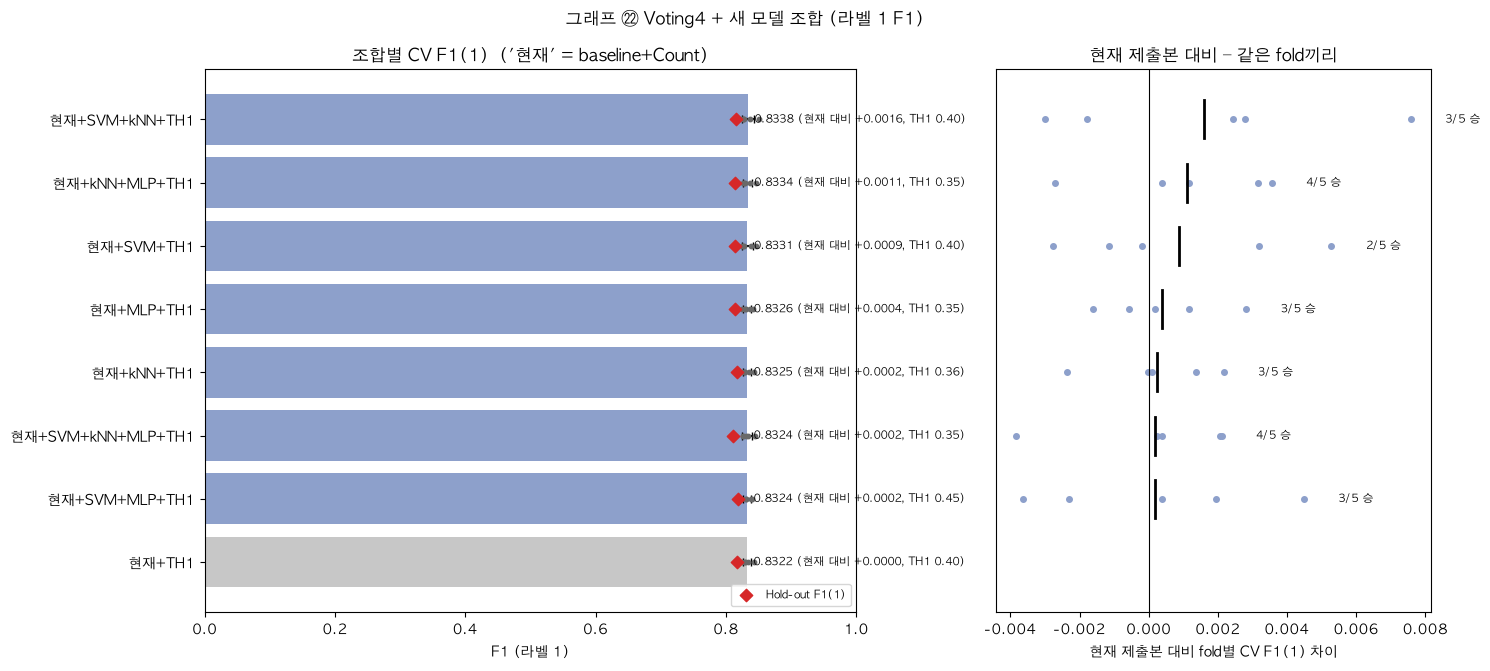

교체 조건을 모두 만족하는 조합 없음 → predict_output_김정인.csv 는 현재 제출본(baseline+Count+TH1) 유지


In [37]:
d = combo.iloc[::-1].reset_index(drop=True)
colors = ["#c7c7c7" if v == current["version"] else ("#2ca02c" if ok else "#8da0cb")
          for v, ok in zip(d["version"], d["교체 조건 충족"])]
fig, ax = plt.subplots(1, 2, figsize=(15, 0.6 * len(d) + 2), gridspec_kw={"width_ratios": [1.5, 1]})
pos = np.arange(len(d))
ax[0].barh(pos, d["CV_F1_1"], xerr=d["CV_std"], capsize=3, color=colors)
for p, s in zip(pos, d["cv_scores"]):
    ax[0].scatter(s, np.full(len(s), p), s=10, color="dimgray", zorder=3)
ax[0].scatter(d["Holdout_F1_1"], pos, marker="D", s=40, color="#d62728", zorder=4, label="Hold-out F1(1)")
for p, v, th, dv in zip(pos, d["CV_F1_1"], d["TH1"], d["현재 대비"]):
    ax[0].text(v + 0.01, p, f"{v:.4f} (현재 대비 {dv:+.4f}, TH1 {th:.2f})", va="center", fontsize=8)
ax[0].set_yticks(pos, d["version"].str.replace("baseline+Count", "현재", regex=False))
allv = np.concatenate([np.concatenate(d["cv_scores"].values), d["Holdout_F1_1"].values])
ax[0].set_xlim(0, 1); ax[0].set_xlabel("F1 (라벨 1)")
ax[0].legend(loc="lower right", fontsize=8); ax[0].set_title("조합별 CV F1(1)  ('현재' = baseline+Count)")

for p, s, v in zip(pos, d["cv_scores"], d["version"]):
    if v == current["version"]: continue
    diff = s - current["cv_scores"]
    ax[1].scatter(diff, np.full(len(diff), p), s=16, color="#8da0cb")
    ax[1].plot([diff.mean()] * 2, [p - 0.3, p + 0.3], color="k", lw=2)
    ax[1].text(max(diff.max(), 0) + 0.001, p, f"{int((diff > 0).sum())}/5 승", va="center", fontsize=8)
ax[1].axvline(0, color="k", lw=0.8); ax[1].set_yticks([]); ax[1].set_ylim(ax[0].get_ylim())
ax[1].set_xlabel("현재 제출본 대비 fold별 CV F1(1) 차이"); ax[1].set_title("현재 제출본 대비 – 같은 fold끼리")
plt.suptitle("그래프 ㉒ Voting4 + 새 모델 조합 (라벨 1 F1)"); plt.tight_layout()
save_fig("22_모델조합_성능_라벨1"); plt.show()

ok = combo[combo["교체 조건 충족"]]
if len(ok):
    win = ok.iloc[0]
    shutil.copy(f"{OUT_DIR}/{win['file']}", SUBMIT_PATH)
    print(f"교체: {win['version']} (CV F1(1) {win['CV_F1_1']:.4f}, 현재 대비 {win['현재 대비']:+.4f}, "
          f"{win['이긴 fold']}/5 승, Hold-out {win['Hold-out 대비']:+.4f}) → {SUBMIT_PATH}")
else:
    print(f"교체 조건을 모두 만족하는 조합 없음 → {SUBMIT_PATH} 는 현재 제출본({current['version']}) 유지")

### 9-9. 모델 7개 자유 조합 – 운을 걷어낸 선택 (라벨 1 F1)

모델 7개(RF, XGBoost, LightGBM, CatBoost, SVM, kNN, MLP)에서 **2개 이상 고르는 조합 120개**를 모두 평가합니다.
9-3·9-8에서 저장한 확률을 평균만 내므로 **재학습 없음**.

조합이 많으면 **우연히 높게 나온 조합**을 고르게 됩니다. 그래서 고르는 데이터와 점수 매기는 데이터를 분리합니다.

1. **공정 비교**: 모든 조합을 threshold **0.5 고정**으로 비교 (조합마다 TH를 고르면 운이 한 번 더 섞임)
2. **Nested 선택**: 5개 fold 중 4개로 120개 중 최고를 **고르고**, 남은 1개 fold로 **채점** × 5번
   → "120개 중 최고를 고르는 방식"의 정직한 점수. Voting4(고르기 없음)보다 높아야 조합 고르기가 의미 있음
   → 5번 모두 같은 조합이 뽑히는지 = **안정성**
3. **1-SE 규칙**: 최고 점수와 표준오차 안에서 차이 나는 조합은 동점으로 보고, 그중 **모델 수가 가장 적은** 조합 선택
4. 선택된 조합 **하나에만** TH1 적용 → 현재 제출본 대비 교체 기준 3가지(CV↑, 4/5 fold 승, Hold-out 유지 이상) + **Nested가 Voting4보다 높을 것**까지 모두 만족해야 교체

In [38]:
ALL7 = list(SEARCH) + ["SVM", "kNN", "MLP"]
def combo_label(members):
    return "+".join(members)

rows = []
for r in range(2, len(ALL7) + 1):
    for members in itertools.combinations(ALL7, r):
        oof = np.mean([P1[n][0] for n in members], axis=0)
        te = np.mean([P1[n][1] for n in members], axis=0)
        cv = folds_f1_1(np.where(oof >= 0.5, 1, 0))
        rows.append({"조합": combo_label(members), "members": members, "모델 수": len(members),
                     "CV_F1_1@0.5": cv.mean(), "CV_std": cv.std(), "cv_scores": cv,
                     "Holdout_F1_1@0.5": f1_1(y_te_, np.where(te >= 0.5, 1, 0))})
allc = pd.DataFrame(rows).sort_values("CV_F1_1@0.5", ascending=False).reset_index(drop=True)
FOLD_MAT = np.vstack(allc["cv_scores"].values)            # (120, 5)

V4 = combo_label(list(SEARCH))                              # 기준: Voting4 (트리 4개), 고르기 없음
v4_row = allc[allc["조합"] == V4].iloc[0]
print(f"조합 수: {len(allc)} | Voting4 @0.5 CV F1(1) {v4_row['CV_F1_1@0.5']:.4f} (120개 중 {allc.index[allc['조합'] == V4][0] + 1}위)")

# --- Nested 선택 ---
nested = []
for k in range(len(FOLDS)):
    inner = [j for j in range(len(FOLDS)) if j != k]
    pick = FOLD_MAT[:, inner].mean(1).argmax()             # 나머지 4개 fold로 고르고
    nested.append({"채점 fold": k + 1, "고른 조합": allc.loc[pick, "조합"],
                   "채점 fold 점수": FOLD_MAT[pick, k], "Voting4 같은 fold": v4_row["cv_scores"][k]})
nested = pd.DataFrame(nested)
NESTED_MEAN = nested["채점 fold 점수"].mean()
print(f"Nested 선택 점수 {NESTED_MEAN:.4f} vs Voting4 {v4_row['CV_F1_1@0.5']:.4f} "
      f"→ {'조합 고르기가 도움됨' if NESTED_MEAN > v4_row['CV_F1_1@0.5'] else '조합 고르기 이득 없음 (운이 섞였던 것)'}")
print(f"안정성: 5번 중 서로 다른 조합 {nested['고른 조합'].nunique()}개가 뽑힘")

# --- 1-SE 규칙 ---
best = allc.iloc[0]
se = best["CV_std"] / np.sqrt(len(FOLDS))
tied = allc[allc["CV_F1_1@0.5"] >= best["CV_F1_1@0.5"] - se]
pick1se = tied.sort_values(["모델 수", "CV_F1_1@0.5"], ascending=[True, False]).iloc[0]
print(f"CV 1위: {best['조합']} ({best['CV_F1_1@0.5']:.4f}) | 1-SE 범위 안 조합 {len(tied)}개 "
      f"→ 1-SE 선택: {pick1se['조합']} ({pick1se['CV_F1_1@0.5']:.4f}, {pick1se['모델 수']}개 모델)")
nested.round(4)

조합 수: 120 | Voting4 @0.5 CV F1(1) 0.8286 (120개 중 22위)
Nested 선택 점수 0.8316 vs Voting4 0.8286 → 조합 고르기가 도움됨
안정성: 5번 중 서로 다른 조합 2개가 뽑힘
CV 1위: RF+XGBoost+LightGBM+CatBoost+SVM (0.8325) | 1-SE 범위 안 조합 16개 → 1-SE 선택: LightGBM+SVM (0.8303, 2개 모델)


,채점 fold,고른 조합,채점 fold 점수,Voting4 같은 fold
0,1,RF+XGBoost+LightGBM+CatBoost+SVM,0.8287,0.8272
1,2,RF+LightGBM+SVM,0.8222,0.8226
2,3,RF+XGBoost+LightGBM+CatBoost+SVM,0.8348,0.8302
3,4,RF+XGBoost+LightGBM+CatBoost+SVM,0.8460,0.8420
4,5,RF+XGBoost+LightGBM+CatBoost+SVM,0.8265,0.8208


#### 그래프 ㉓ 조합 상위 10개 + 기준 (threshold 0.5)

x축 0~1 전체. 숫자 = CV F1(1), 괄호 = Voting4 대비 차이.
회색 = Voting4(기준), 주황 = Nested 선택 점수(조합 고르기 방식의 정직한 점수), 초록 = 1-SE 규칙으로 고른 조합.

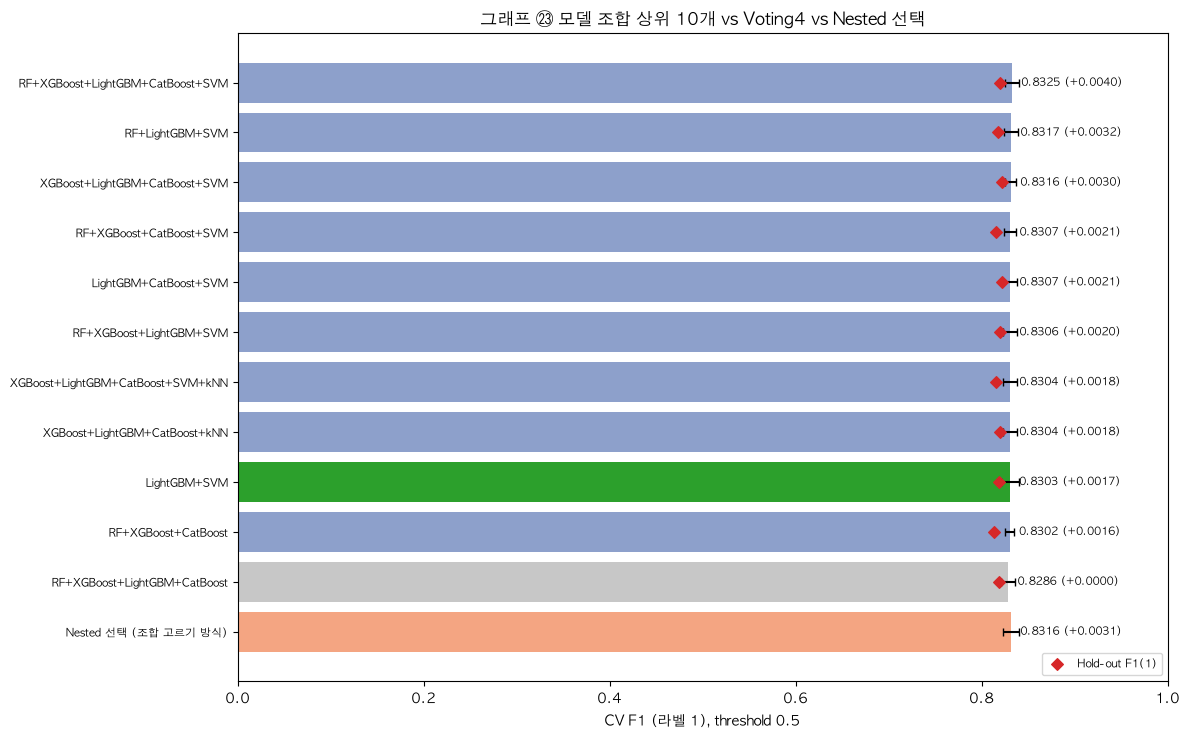

,조합,모델 수,CV_F1_1@0.5,CV_std,Holdout_F1_1@0.5
0,RF+XGBoost+LightGBM+CatBoost+SVM,5,0.8325,0.0074,0.8200
1,RF+LightGBM+SVM,3,0.8317,0.0075,0.8182
2,XGBoost+LightGBM+CatBoost+SVM,4,0.8316,0.0060,0.8216
3,RF+XGBoost+CatBoost+SVM,4,0.8307,0.0069,0.8158
4,LightGBM+CatBoost+SVM,3,0.8307,0.0071,0.8222
5,RF+XGBoost+LightGBM+SVM,4,0.8306,0.0077,0.8199
6,XGBoost+LightGBM+CatBoost+SVM+kNN,5,0.8304,0.0074,0.8155
7,XGBoost+LightGBM+CatBoost+kNN,4,0.8304,0.0075,0.8199
8,LightGBM+SVM,2,0.8303,0.0097,0.8187
9,RF+XGBoost+CatBoost,3,0.8302,0.0048,0.8137


In [39]:
top = allc.head(10).copy()
if V4 not in set(top["조합"]):
    top = pd.concat([top, allc[allc["조합"] == V4]])
show = pd.concat([top[["조합", "CV_F1_1@0.5", "CV_std", "Holdout_F1_1@0.5"]],
                  pd.DataFrame([{"조합": "Nested 선택 (조합 고르기 방식)", "CV_F1_1@0.5": NESTED_MEAN,
                                 "CV_std": nested["채점 fold 점수"].std(ddof=0), "Holdout_F1_1@0.5": np.nan}])])
show = show.iloc[::-1].reset_index(drop=True)
colors = ["#f4a582" if c.startswith("Nested") else "#c7c7c7" if c == V4 else
          "#2ca02c" if c == pick1se["조합"] else "#8da0cb" for c in show["조합"]]
fig, ax = plt.subplots(figsize=(12, 0.5 * len(show) + 1.5))
pos = np.arange(len(show))
ax.barh(pos, show["CV_F1_1@0.5"], xerr=show["CV_std"], capsize=3, color=colors)
ax.scatter(show["Holdout_F1_1@0.5"], pos, marker="D", s=35, color="#d62728", zorder=3, label="Hold-out F1(1)")
for p, v in zip(pos, show["CV_F1_1@0.5"]):
    ax.text(v + 0.01, p, f"{v:.4f} ({v - v4_row['CV_F1_1@0.5']:+.4f})", va="center", fontsize=8)
ax.set_yticks(pos, show["조합"], fontsize=8); ax.set_xlim(0, 1)
ax.set_xlabel("CV F1 (라벨 1), threshold 0.5"); ax.legend(loc="lower right", fontsize=8)
ax.set_title("그래프 ㉓ 모델 조합 상위 10개 vs Voting4 vs Nested 선택")
plt.tight_layout(); save_fig("23_모델조합_상위10_라벨1"); plt.show()
allc.drop(columns=["members", "cv_scores"]).head(10).round(4)

#### 그래프 ㉔ 모델별 기여도

120개 조합 중 **그 모델이 들어간 조합의 평균 CV − 빠진 조합의 평균 CV**. 0보다 크면 넣을수록 점수가 오르는 모델입니다.
(차이 그래프라 0을 중심으로 그립니다.)

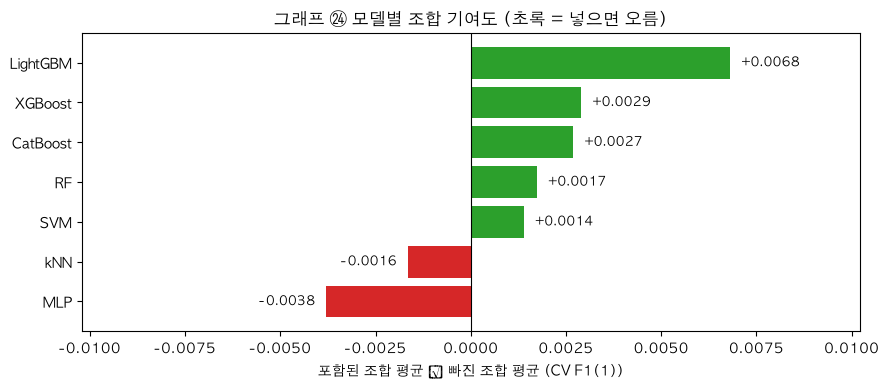

In [40]:
contrib = pd.Series({n: allc.loc[allc["members"].apply(lambda m: n in m), "CV_F1_1@0.5"].mean()
                        - allc.loc[allc["members"].apply(lambda m: n not in m), "CV_F1_1@0.5"].mean()
                     for n in ALL7}).sort_values()
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(contrib.index, contrib.values, color=["#2ca02c" if v > 0 else "#d62728" for v in contrib.values])
for i, v in enumerate(contrib.values):
    ax.text(v + (0.0003 if v >= 0 else -0.0003), i, f"{v:+.4f}", va="center", ha="left" if v >= 0 else "right", fontsize=9)
ax.axvline(0, color="k", lw=0.8); ax.set_xlabel("포함된 조합 평균 − 빠진 조합 평균 (CV F1(1))")
lim = np.abs(contrib.values).max() * 1.5; ax.set_xlim(-lim, lim)
ax.set_title("그래프 ㉔ 모델별 조합 기여도 (초록 = 넣으면 오름)")
plt.tight_layout(); save_fig("24_모델별_조합기여도"); plt.show()

#### 9-9-2. 1-SE 선택 조합에 TH1 적용 → 교체 여부 판단

In [42]:
members = list(pick1se["members"])
oof = np.mean([P1[n][0] for n in members], axis=0)
te = np.mean([P1[n][1] for n in members], axis=0)
pr = np.mean([P1[n][2] for n in members], axis=0)
curve = np.array([folds_f1_1(np.where(oof >= t, 1, 0)).mean() for t in TH1_GRID])
th1 = float(TH1_GRID[pd.Series(curve).rolling(3, center=True, min_periods=1).mean().values.argmax()])
cv = folds_f1_1(np.where(oof >= th1, 1, 0))
pred = np.where(pr >= th1, 1, 0)
vname = f"baseline+Count+[{combo_label(members)}]+TH1"
sub = pd.read_csv(SAMPLE_PATH); sub["output"] = pred
sub.to_csv(f"{OUT_DIR}/output_{vname}.csv", index=False)

check = {
    "CV F1(1) 상승": cv.mean() > current["CV_F1_1"],
    "4/5 fold 이상 승": int((cv > current["cv_scores"]).sum()) >= 4,
    "Hold-out 유지 이상": f1_1(y_te_, np.where(te >= th1, 1, 0)) >= current["Holdout_F1_1"],
    "Nested > Voting4": NESTED_MEAN > v4_row["CV_F1_1@0.5"],
}
summary = pd.DataFrame([
    {"버전": current["version"] + " (현재 제출본)", "TH1": current["TH1"], "CV_F1_1": current["CV_F1_1"],
     "Holdout_F1_1": current["Holdout_F1_1"], "pred_1_rate": current["pred_1_rate"]},
    {"버전": vname, "TH1": th1, "CV_F1_1": cv.mean(),
     "Holdout_F1_1": f1_1(y_te_, np.where(te >= th1, 1, 0)), "pred_1_rate": pred.mean()},
])
for k, v in check.items():
    print(f"  {'✅' if v else '❌'} {k}")
if all(check.values()):
    shutil.copy(f"{OUT_DIR}/output_{vname}.csv", SUBMIT_PATH)
    print(f"→ 4가지 모두 충족: {SUBMIT_PATH} 교체 ({vname})")
else:
    print(f"→ 조건 미충족: {SUBMIT_PATH} 는 현재 제출본 유지 (비교용 파일은 outputs/에 저장)")
allc.drop(columns=["members", "cv_scores"]).to_csv(f"{OUT_DIR}/버전_기록_조합120.csv", index=False, encoding="utf-8-sig")
summary.round(4)

  ✅ CV F1(1) 상승
  ❌ 4/5 fold 이상 승
  ❌ Hold-out 유지 이상
  ✅ Nested > Voting4
→ 조건 미충족: predict_output_김정인.csv 는 현재 제출본 유지 (비교용 파일은 outputs/에 저장)


,버전,TH1,CV_F1_1,Holdout_F1_1,pred_1_rate
0,baseline+Count+TH1 (현재 제출본),0.40,0.8322,0.8173,0.5944
1,baseline+Count+[LightGBM+SVM]+TH1,0.37,0.8323,0.8122,0.5922


### 9-10. 라벨 1 기준 재튜닝 (리더보드 기준)

현재 제출본(`baseline+Count+TH1`)의 트리 파라미터는 5번 E5에서 **F1(0) 목표, E3 피처**로 튜닝한 값입니다.
이를 **F1(1) 목표, 실제 사용 피처(baseline+Count)** 로 다시 튜닝합니다.

- 대상: RF, XGBoost, LightGBM, CatBoost / 학습 데이터(80%)에서 3-fold CV F1(1) 최대화
- **warm start**: 기존 최적 파라미터를 첫 시도로 넣고 시작
- `optuna_tuning.db`에 새 study(`모델__F1_1__baseline+Count`)로 저장 → 기존 기록과 분리, `TUNE1_TRIALS`로 이어서 탐색 가능
- 평가는 기존과 동일: 같은 80/20 분할·같은 5-fold, **F1(1)과 Accuracy** 함께 확인
- 비교 버전: 현재 제출본 / 재튜닝 Voting4 / 재튜닝 Voting4+SVM (각각 threshold 0.5와 TH1)
- 교체 기준: 현재 제출본 대비 ① CV F1(1) 상승 ② 4/5 fold 이상 승 ③ Hold-out F1(1) 유지 이상 → 모두 충족 시에만 교체

예상 시간: 탐색 약 15~18분 + 평가 약 6분

In [43]:
TUNE1_TRIALS = 15
FEATS_C = build_feats(["Count"])                  # 현재 제출본과 같은 피처
Xc_tr = X_ext[FEATS_C].iloc[X_tr_idx]

STUDIES1, BEST1 = {}, {}
for name, (cls, fixed, space) in SEARCH.items():
    study = optuna.create_study(study_name=f"{name}__F1_1__baseline+Count", storage=STORAGE, direction="maximize",
                                sampler=optuna.samplers.TPESampler(seed=SEED), load_if_exists=True)
    if len(study.trials) == 0:
        study.enqueue_trial(STUDIES[name].best_params)            # warm start: 기존 최적값부터
    def objective(trial, cls=cls, fixed=fixed, space=space):
        return cross_val_score(cls(**fixed, **space(trial)), Xc_tr, y_tr_, cv=CV3,
                               scoring=F1_1_SCORER, n_jobs=1).mean()
    t0 = time.time()
    if TUNE1_TRIALS > 0:
        print(f"▶ {name}: 기존 {len(study.trials)}회 + 이번 {TUNE1_TRIALS}회 탐색")
        study.optimize(objective, n_trials=TUNE1_TRIALS, show_progress_bar=True)
    STUDIES1[name] = study
    BEST1[name] = {**fixed, **study.best_params}
    warm = study.trials[0].value
    print(f"  {name:9s} 누적 {len(study.trials)}회 | 기존 파라미터 {warm:.4f} → best {study.best_value:.4f} "
          f"({study.best_value - warm:+.4f}) | {time.time()-t0:.0f}s")

▶ RF: 기존 1회 + 이번 15회 탐색


  0%|          | 0/15 [00:00<?, ?it/s]

  RF        누적 15회 | 기존 파라미터 0.8148 → best 0.8148 (+0.0000) | 184s
▶ XGBoost: 기존 1회 + 이번 15회 탐색


  0%|          | 0/15 [00:00<?, ?it/s]

  XGBoost   누적 15회 | 기존 파라미터 0.8121 → best 0.8121 (+0.0000) | 152s
▶ LightGBM: 기존 1회 + 이번 15회 탐색


  0%|          | 0/15 [00:00<?, ?it/s]

  LightGBM  누적 15회 | 기존 파라미터 0.8114 → best 0.8152 (+0.0039) | 388s
▶ CatBoost: 기존 1회 + 이번 15회 탐색


  0%|          | 0/15 [00:00<?, ?it/s]

  CatBoost  누적 15회 | 기존 파라미터 0.8129 → best 0.8129 (+0.0000) | 197s


#### 그래프 ㉕ 재튜닝 수렴 곡선 (3-fold CV F1(1))

점 = 각 시도, 빨간 선 = 지금까지 최고, 회색 점선 = 1번째 시도(기존 파라미터). 선이 점선 위로 올라가면 재튜닝 효과가 있는 것입니다.

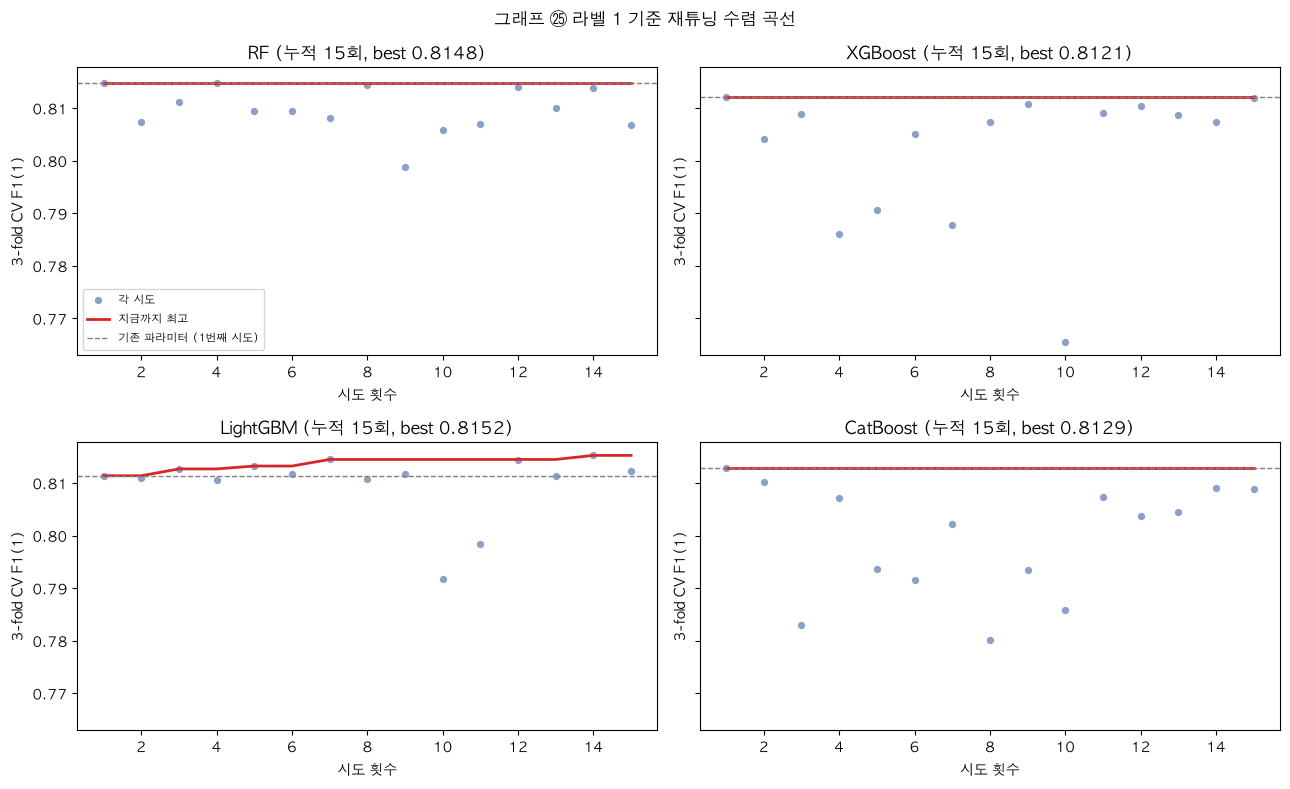

In [44]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharey=True)
for a, (name, study) in zip(axes.ravel(), STUDIES1.items()):
    tr = study.trials_dataframe(); tr = tr[tr.state == "COMPLETE"]
    a.scatter(tr.number + 1, tr.value, s=18, color="#8da0cb", label="각 시도")
    a.plot(tr.number + 1, tr.value.cummax(), color="#d62728", lw=2, label="지금까지 최고")
    a.axhline(study.trials[0].value, color="gray", ls="--", lw=1, label="기존 파라미터 (1번째 시도)")
    a.set_title(f"{name} (누적 {len(tr)}회, best {tr.value.max():.4f})")
    a.set_xlabel("시도 횟수"); a.set_ylabel("3-fold CV F1(1)")
axes[0, 0].legend(fontsize=8)
plt.suptitle("그래프 ㉕ 라벨 1 기준 재튜닝 수렴 곡선"); plt.tight_layout(); save_fig("25_재튜닝_수렴곡선_라벨1"); plt.show()

#### 9-10-2. 재튜닝 파라미터로 Voting4 평가 (F1(1) + Accuracy)

In [45]:
def member_p1(params, feats):
    """Voting4 구성 모델별 '독성 없음(1)' 확률: 5-fold OOF / Hold-out / 전체 train 재학습 후 predict"""
    Xf, Xp = X_ext[feats], X_pred_ext[feats]
    Xtr, Xte = Xf.iloc[X_tr_idx], Xf.iloc[X_te_idx]
    mk = lambda: VotingClassifier([(n, SEARCH[n][0](**params[n])) for n in SEARCH], voting="soft", n_jobs=1)
    p1 = lambda vc, X: np.column_stack([est.predict_proba(X)[:, 1] for est in vc.estimators_])
    t0 = time.time(); oof = np.zeros((len(X_tr_idx), len(SEARCH)))
    for k, (tr, va) in enumerate(FOLDS, start=1):
        oof[va] = p1(mk().fit(Xtr.iloc[tr], y_tr_[tr]), Xtr.iloc[va])
        print(f"  fold {k}/5 완료 ({time.time()-t0:.0f}s)")
    te = p1(mk().fit(Xtr, y_tr_), Xte)
    pr = p1(mk().fit(Xf, y), Xp)
    print(f"  Hold-out·전체 학습 완료 ({time.time()-t0:.0f}s)")
    return oof, te, pr

NEW = member_p1(BEST1, FEATS_C)
OLD = tuple(np.column_stack([P1[n][i] for n in SEARCH]) for i in range(3))   # 현재 제출본의 트리 확률

def pick_th1(oof):
    curve = np.array([folds_f1_1(np.where(oof >= t, 1, 0)).mean() for t in TH1_GRID])
    return float(TH1_GRID[pd.Series(curve).rolling(3, center=True, min_periods=1).mean().values.argmax()])

def evaluate_probs(vname, oof, te, pr, th, save=True):
    pred_oof, pred_te, pred = [np.where(p >= th, 1, 0) for p in (oof, te, pr)]
    cv_f1 = folds_f1_1(pred_oof)
    cv_acc = np.array([accuracy_score(y_tr_[va], pred_oof[va]) for _, va in FOLDS])
    if save:
        sub = pd.read_csv(SAMPLE_PATH); sub["output"] = pred
        sub.to_csv(f"{OUT_DIR}/output_{vname}.csv", index=False)
    return {"version": vname, "TH": th, "CV_F1_1": cv_f1.mean(), "CV_F1_1_std": cv_f1.std(), "CV_Acc": cv_acc.mean(),
            "Holdout_F1_1": f1_1(y_te_, pred_te), "Holdout_Acc": accuracy_score(y_te_, pred_te),
            "Holdout_Precision_1": ((pred_te == 1) & (y_te_ == 1)).sum() / max((pred_te == 1).sum(), 1),
            "Holdout_Recall_1": ((pred_te == 1) & (y_te_ == 1)).sum() / (y_te_ == 1).sum(),
            "pred_1_rate": pred.mean(), "cv_scores": cv_f1, "file": f"output_{vname}.csv"}

svm = P1["SVM"]
RT = []
# 현재 제출본 (기존 파라미터, TH1 0.40) – 파일은 이미 있음
o, t, p = (m.mean(1) for m in OLD)
RT.append(evaluate_probs(current["version"], o, t, p, current["TH1"], save=False))
# 기존 파라미터 + SVM (9-9 Nested가 반복 선택한 조합), threshold 0.5
o, t, p = (np.column_stack([m, s]).mean(1) for m, s in zip(OLD, svm))
RT.append(evaluate_probs("baseline+Count+SVM", o, t, p, 0.5))
# 재튜닝 Voting4 / Voting4+SVM, 각각 0.5와 TH1
for tag, probs in [("", NEW), ("+SVM", tuple(np.column_stack([m, s]) for m, s in zip(NEW, svm)))]:
    o, t, p = (m.mean(1) for m in probs)
    RT.append(evaluate_probs(f"baseline+Count+Tune1{tag}", o, t, p, 0.5))
    RT.append(evaluate_probs(f"baseline+Count+Tune1{tag}+TH1", o, t, p, pick_th1(o)))

cur = RT[0]
for r in RT:
    r["현재 대비"] = r["CV_F1_1"] - cur["CV_F1_1"]
    r["이긴 fold"] = int((r["cv_scores"] > cur["cv_scores"]).sum())
    r["Hold-out 대비"] = r["Holdout_F1_1"] - cur["Holdout_F1_1"]
    r["교체 조건 충족"] = bool(r is not cur and r["현재 대비"] > 0 and r["이긴 fold"] >= 4 and r["Hold-out 대비"] >= 0)
rt = pd.DataFrame(RT)
rt.drop(columns="cv_scores").to_csv(f"{OUT_DIR}/버전_기록_재튜닝.csv", index=False, encoding="utf-8-sig")
rt.drop(columns=["cv_scores", "file"]).round(4)

  fold 1/5 완료 (23s)
  fold 2/5 완료 (47s)
  fold 3/5 완료 (70s)
  fold 4/5 완료 (94s)
  fold 5/5 완료 (118s)
  Hold-out·전체 학습 완료 (177s)


,version,TH,CV_F1_1,CV_F1_1_std,CV_Acc,Holdout_F1_1,Holdout_Acc,Holdout_Precision_1,Holdout_Recall_1,pred_1_rate,현재 대비,이긴 fold,Hold-out 대비,교체 조건 충족
0,baseline+Count+TH1,0.40,0.8322,0.0061,0.8070,0.8173,0.7880,0.7697,0.8713,0.5944,0.0000,0,0.0000,False
1,baseline+Count+SVM,0.50,0.8325,0.0074,0.8140,0.8200,0.7994,0.8015,0.8394,0.5556,0.0003,3,0.0027,False
2,baseline+Count+Tune1,0.50,0.8284,0.0063,0.8093,0.8131,0.7916,0.7943,0.8328,0.5577,-0.0038,1,-0.0042,False
3,baseline+Count+Tune1+TH1,0.47,0.8312,0.0043,0.8093,0.8158,0.7910,0.7840,0.8504,0.5728,-0.0011,2,-0.0015,False
4,baseline+Count+Tune1+SVM,0.50,0.8291,0.0059,0.8102,0.8103,0.7880,0.7900,0.8317,0.5556,-0.0032,1,-0.0070,False
5,baseline+Count+Tune1+SVM+TH1,0.46,0.8334,0.0058,0.8109,0.8106,0.7826,0.7708,0.8548,0.5750,0.0011,3,-0.0067,False


#### 그래프 ㉖ 재튜닝 전후 비교 – F1(1)과 Accuracy

x축 0~1 전체. 막대 = CV, ◆ = Hold-out, 숫자 = CV 값과 현재 제출본 대비 차이.
회색 = 현재 제출본, 초록 = 교체 조건 3개 모두 충족.

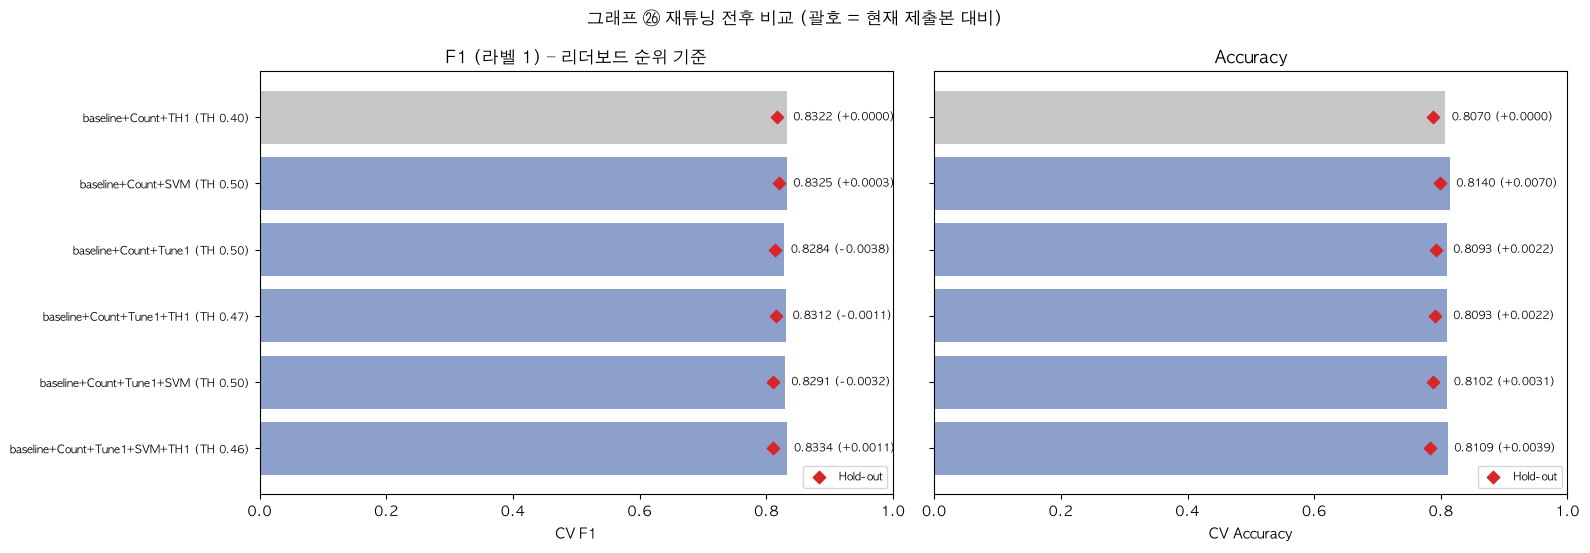

교체 조건을 모두 만족하는 버전 없음 → predict_output_김정인.csv 는 현재 제출본(baseline+Count+TH1) 유지


In [46]:
d = rt.iloc[::-1].reset_index(drop=True)
colors = ["#c7c7c7" if v == cur["version"] else ("#2ca02c" if ok else "#8da0cb")
          for v, ok in zip(d["version"], d["교체 조건 충족"])]
fig, ax = plt.subplots(1, 2, figsize=(16, 0.6 * len(d) + 2), sharey=True)
pos = np.arange(len(d))
for a, cv_col, ho_col, title in [(ax[0], "CV_F1_1", "Holdout_F1_1", "F1 (라벨 1) – 리더보드 순위 기준"),
                                 (ax[1], "CV_Acc", "Holdout_Acc", "Accuracy")]:
    a.barh(pos, d[cv_col], color=colors)
    a.scatter(d[ho_col], pos, marker="D", s=40, color="#d62728", zorder=3, label="Hold-out")
    for p_, v in zip(pos, d[cv_col]):
        a.text(v + 0.01, p_, f"{v:.4f} ({v - cur[cv_col]:+.4f})", va="center", fontsize=8)
    a.set_xlim(0, 1); a.set_title(title); a.set_xlabel(f"CV {title.split(' ')[0]}"); a.legend(loc="lower right", fontsize=8)
ax[0].set_yticks(pos, [f"{v} (TH {th:.2f})" for v, th in zip(d["version"], d["TH"])], fontsize=8)
plt.suptitle("그래프 ㉖ 재튜닝 전후 비교 (괄호 = 현재 제출본 대비)"); plt.tight_layout()
save_fig("26_재튜닝_전후비교_F1_Acc"); plt.show()

ok = rt[rt["교체 조건 충족"]].sort_values("CV_F1_1", ascending=False)
if len(ok):
    win = ok.iloc[0]
    shutil.copy(f"{OUT_DIR}/{win['file']}", SUBMIT_PATH)
    print(f"교체: {win['version']} (CV F1(1) {win['CV_F1_1']:.4f}, {win['현재 대비']:+.4f}, {win['이긴 fold']}/5 승, "
          f"Hold-out {win['Hold-out 대비']:+.4f}, CV Acc {win['CV_Acc']:.4f}) → {SUBMIT_PATH}")
else:
    print(f"교체 조건을 모두 만족하는 버전 없음 → {SUBMIT_PATH} 는 현재 제출본({cur['version']}) 유지")

### 9-11. 이웃 라벨 피처 (NN) + 반복 CV로 정밀 비교

**발상**: 지금 트리는 분자 **하나의 구조**만 봅니다. "학습 데이터에서 이 분자와 가장 비슷한 분자들은 독성이 없었다"는 정보는 쓰지 못합니다.
kNN은 이 정보만 쓰고 물성을 무시해서 약했습니다(0.778). → **이웃 정보를 피처로 만들어 트리에 넣으면** 트리가 "이웃은 안전 + 그런데 clogp 높음" 같은 조합을 학습할 수 있습니다.

**근거 (Notion EDA)**: 최근접 이웃 라벨 일치율 76% → 유사성 원리 성립. 단, 유사도 0.9 이상에서도 18%는 라벨이 다름(activity cliff) → 이웃만 믿지 않고 물성과 함께 판단하게 함.

**NN 피처 7개** (입체 지문 ECFPC+FCFPC의 Tanimoto 유사도 기준)

| 피처 | 뜻 |
|---|---|
| `nn_rate5/10/20` | 가장 비슷한 5·10·20개 분자의 '독성 없음' 비율 (유사도 가중) |
| `nn_max1`, `nn_max0` | 독성 없음 / 독성 있음 분자 중 가장 높은 유사도 |
| `nn_maxdiff` | `nn_max1 - nn_max0` (어느 쪽에 더 닮은 분자가 있나) |
| `nn_top5sim` | 상위 5개 이웃의 평균 유사도 (이웃 정보를 얼마나 믿을 수 있나) |

**데이터 누수 방지 (중요)**: 자기 라벨이 피처에 들어가면 점수가 가짜로 오릅니다.
- 학습 행: **자기 자신을 뺀** 이웃만 사용 (leave-one-out)
- 검증 행: **그 fold의 학습 데이터에서만** 이웃 검색
- predict_input: train 전체에서 이웃 검색 (test 라벨은 사용하지 않음)

**규정**: train.csv 라벨만 사용, 외부 데이터 없음 ✅

**비교 대상**: 현재 제출본 `baseline+Count+SVM` (Voting4 + SVM, threshold 0.5)
**교체 기준**: ① 기존 엄격 기준(CV↑, 4/5 fold 승, Hold-out 유지 이상) **또는** ② 반복 CV 5×5 = 25개 fold에서 **20개 이상 승(80%)** + 평균↑ + Hold-out 유지 이상

In [47]:
NN_COLS = ["nn_rate5", "nn_rate10", "nn_rate20", "nn_max1", "nn_max0", "nn_maxdiff", "nn_top5sim"]
FP_TR_ALL = np.asarray(X_ext[TAN_COLS], dtype=np.float32)
FP_PR_ALL = np.asarray(X_pred_ext[TAN_COLS], dtype=np.float32)
t0 = time.time()
S_ALL = tanimoto(FP_TR_ALL, FP_TR_ALL).astype(np.float32)      # train × train 유사도
S_PR = tanimoto(FP_PR_ALL, FP_TR_ALL).astype(np.float32)       # predict × train 유사도
Y_ALL = y.values
print(f"유사도 행렬 {S_ALL.shape} + {S_PR.shape} 계산 {time.time()-t0:.1f}s")

def nn_from_sim(S, y_ref):
    """S: (질의 × 참조) 유사도, 자기 자신은 미리 -1 처리. y_ref: 참조 라벨"""
    out = {}
    order = np.argsort(-S, axis=1)[:, :20]
    top_s = np.take_along_axis(S, order, axis=1).clip(min=0); top_y = y_ref[order]
    for k in (5, 10, 20):
        w = top_s[:, :k] + 1e-6
        out[f"nn_rate{k}"] = (w * top_y[:, :k]).sum(1) / w.sum(1)
    out["nn_max1"] = np.where(y_ref[None, :] == 1, S, -1).max(1).clip(min=0)
    out["nn_max0"] = np.where(y_ref[None, :] == 0, S, -1).max(1).clip(min=0)
    out["nn_maxdiff"] = out["nn_max1"] - out["nn_max0"]
    out["nn_top5sim"] = top_s[:, :5].mean(1)
    return pd.DataFrame(out)[NN_COLS]

def nn_block(q_idx, ref_idx, same):
    """train 안에서: q_idx 행의 이웃을 ref_idx 행에서 찾음 (same=True면 자기 자신 제외)"""
    S = S_ALL[np.ix_(q_idx, ref_idx)].copy()
    if same:
        np.fill_diagonal(S, -1)
    d = nn_from_sim(S, Y_ALL[ref_idx]); d.index = X_ext.index[q_idx]
    return d

def nn_predict_block():
    d = nn_from_sim(S_PR.copy(), Y_ALL); d.index = X_pred_ext.index
    return d

def design(rows_q, rows_ref, same, base_feats):
    return pd.concat([X_ext.iloc[rows_q][base_feats], nn_block(rows_q, rows_ref, same)], axis=1)

# 누수 점검: 학습 행의 nn 피처에 자기 라벨이 섞였다면 nn_rate5와 라벨의 일치가 비정상적으로 높게 나옴
chk = nn_block(X_tr_idx, X_tr_idx, True)
agree = ((chk["nn_rate5"] >= 0.5).astype(int).values == y_tr_).mean()
print(f"누수 점검: 학습 행 nn_rate5 다수결과 실제 라벨 일치율 {agree:.1%} (EDA 최근접 이웃 일치율 76% 근처면 정상, 100% 근처면 누수)")
chk.groupby(y_tr_).median().rename(index={0: "독성 있음(0)", 1: "독성 없음(1)"}).round(3)

유사도 행렬 (8349, 8349) + (927, 8349) 계산 0.3s
누수 점검: 학습 행 nn_rate5 다수결과 실제 라벨 일치율 76.9% (EDA 최근접 이웃 일치율 76% 근처면 정상, 100% 근처면 누수)


,nn_rate5,nn_rate10,nn_rate20,nn_max1,nn_max0,nn_maxdiff,nn_top5sim
독성 있음(0),0.198,0.286,0.335,0.649,0.793,-0.112,0.721
독성 없음(1),0.803,0.723,0.687,0.789,0.620,0.111,0.702


#### 9-11-2. 빠른 확인 – LightGBM(기본값): baseline+Count vs +NN

In [48]:
def oof_te_pr(make_model, base_feats, with_nn, folds=FOLDS, train_rows=X_tr_idx, test_rows=X_te_idx, full=True):
    """'독성 없음(1)' 확률: OOF(학습 80% 안 5-fold) / Hold-out / 전체 train 재학습 후 predict. NN 피처는 fold마다 새로 계산"""
    def mats(q, ref, same):
        return design(q, ref, same, base_feats) if with_nn else X_ext.iloc[q][base_feats]
    oof = np.zeros(len(train_rows))
    for tr, va in folds:
        g_tr, g_va = train_rows[tr], train_rows[va]
        m = make_model().fit(mats(g_tr, g_tr, True), Y_ALL[g_tr])
        oof[va] = m.predict_proba(mats(g_va, g_tr, False))[:, 1]
    te = make_model().fit(mats(train_rows, train_rows, True), Y_ALL[train_rows]) \
                     .predict_proba(mats(test_rows, train_rows, False))[:, 1] if test_rows is not None else None
    pr = None
    if full:
        all_rows = np.arange(len(Y_ALL))
        Xp = pd.concat([X_pred_ext[base_feats], nn_predict_block()], axis=1) if with_nn else X_pred_ext[base_feats]
        pr = make_model().fit(mats(all_rows, all_rows, True), Y_ALL).predict_proba(Xp)[:, 1]
    return oof, te, pr

screen_nn = {}
for label, with_nn in [("LightGBM | baseline+Count", False), ("LightGBM | baseline+Count+NN", True)]:
    t0 = time.time()
    o, t, _ = oof_te_pr(lambda: LGBMClassifier(**LGBM_FAST), FEATS_C, with_nn, full=False)
    cv = folds_f1_1(np.where(o >= 0.5, 1, 0))
    screen_nn[label] = {"CV_F1_1": cv.mean(), "CV_std": cv.std(), "cv_scores": cv,
                        "Holdout_F1_1": f1_1(y_te_, np.where(t >= 0.5, 1, 0))}
    print(f"[{label}] CV F1(1) {cv.mean():.4f} ± {cv.std():.4f} | Hold-out {screen_nn[label]['Holdout_F1_1']:.4f} | {time.time()-t0:.0f}s")
a, b = screen_nn.values()
print(f"→ NN 추가 효과: CV {b['CV_F1_1'] - a['CV_F1_1']:+.4f}, {(b['cv_scores'] > a['cv_scores']).sum()}/5 fold 승, "
      f"Hold-out {b['Holdout_F1_1'] - a['Holdout_F1_1']:+.4f}")

[LightGBM | baseline+Count] CV F1(1) 0.8252 ± 0.0050 | Hold-out 0.8198 | 28s
[LightGBM | baseline+Count+NN] CV F1(1) 0.8207 ± 0.0034 | Hold-out 0.8124 | 36s
→ NN 추가 효과: CV -0.0046, 1/5 fold 승, Hold-out -0.0074


#### 9-11-3. Voting4(+SVM)에 NN 피처 적용 → 현재 제출본과 비교 (기존 엄격 기준)

In [49]:
def make_voting4(params=BEST_PARAMS):
    return VotingClassifier([(n, SEARCH[n][0](**params[n])) for n in SEARCH], voting="soft", n_jobs=1)

t0 = time.time()
V_NN = oof_te_pr(make_voting4, FEATS_C, True)
print(f"Voting4 + NN 학습 완료 {time.time()-t0:.0f}s")
svm = P1["SVM"]
cur_sub = next(r for r in RT if r["version"] == "baseline+Count+SVM")     # 현재 제출본

NNV = [cur_sub]
o, t, p = V_NN
NNV.append(evaluate_probs("baseline+Count+NN", o, t, p, 0.5))
NNV.append(evaluate_probs("baseline+Count+NN+TH1", o, t, p, pick_th1(o)))
# 현재 제출본과 같은 가중: 모델 5개 단순 평균 = (Voting4 평균 × 4 + SVM) / 5
o, t, p = ((4 * v + s) / 5 for v, s in zip(V_NN, svm))
NNV.append(evaluate_probs("baseline+Count+NN+SVM", o, t, p, 0.5))
NNV.append(evaluate_probs("baseline+Count+NN+SVM+TH1", o, t, p, pick_th1(o)))

for r in NNV:
    r["현재 대비"] = r["CV_F1_1"] - cur_sub["CV_F1_1"]
    r["이긴 fold"] = int((r["cv_scores"] > cur_sub["cv_scores"]).sum())
    r["Hold-out 대비"] = r["Holdout_F1_1"] - cur_sub["Holdout_F1_1"]
    r["엄격 기준 통과"] = bool(r is not cur_sub and r["현재 대비"] > 0 and r["이긴 fold"] >= 4 and r["Hold-out 대비"] >= 0)
nnv = pd.DataFrame(NNV)
nnv.drop(columns="cv_scores").to_csv(f"{OUT_DIR}/버전_기록_이웃피처.csv", index=False, encoding="utf-8-sig")
nnv.drop(columns=["cv_scores", "file"]).round(4)

Voting4 + NN 학습 완료 335s


,version,TH,CV_F1_1,CV_F1_1_std,CV_Acc,Holdout_F1_1,Holdout_Acc,Holdout_Precision_1,Holdout_Recall_1,pred_1_rate,현재 대비,이긴 fold,Hold-out 대비,교체 조건 충족,엄격 기준 통과
0,baseline+Count+SVM,0.50,0.8325,0.0074,0.8140,0.8200,0.7994,0.8015,0.8394,0.5556,0.0000,0,0.0000,False,False
1,baseline+Count+NN,0.50,0.8232,0.0067,0.8040,0.8156,0.7928,0.7911,0.8416,0.5491,-0.0093,0,-0.0044,NaN,False
2,baseline+Count+NN+TH1,0.38,0.8321,0.0060,0.8067,0.8163,0.7862,0.7669,0.8724,0.5955,-0.0004,3,-0.0037,NaN,False
3,baseline+Count+NN+SVM,0.50,0.8244,0.0059,0.8052,0.8100,0.7868,0.7865,0.8350,0.5491,-0.0082,0,-0.0100,NaN,False
4,baseline+Count+NN+SVM+TH1,0.38,0.8313,0.0054,0.8048,0.8131,0.7808,0.7588,0.8757,0.5987,-0.0012,2,-0.0069,NaN,False


#### 그래프 ㉗ 이웃 피처(NN) 효과

x축 0~1 전체. 막대 = CV F1(1), ◆ = Hold-out, 숫자 = 값 (괄호 = 비교 대상 대비 차이, 이긴 fold 수).
왼쪽: LightGBM 단독 빠른 확인 / 오른쪽: Voting4 계열 vs 현재 제출본(회색). 초록 = 엄격 기준 통과.

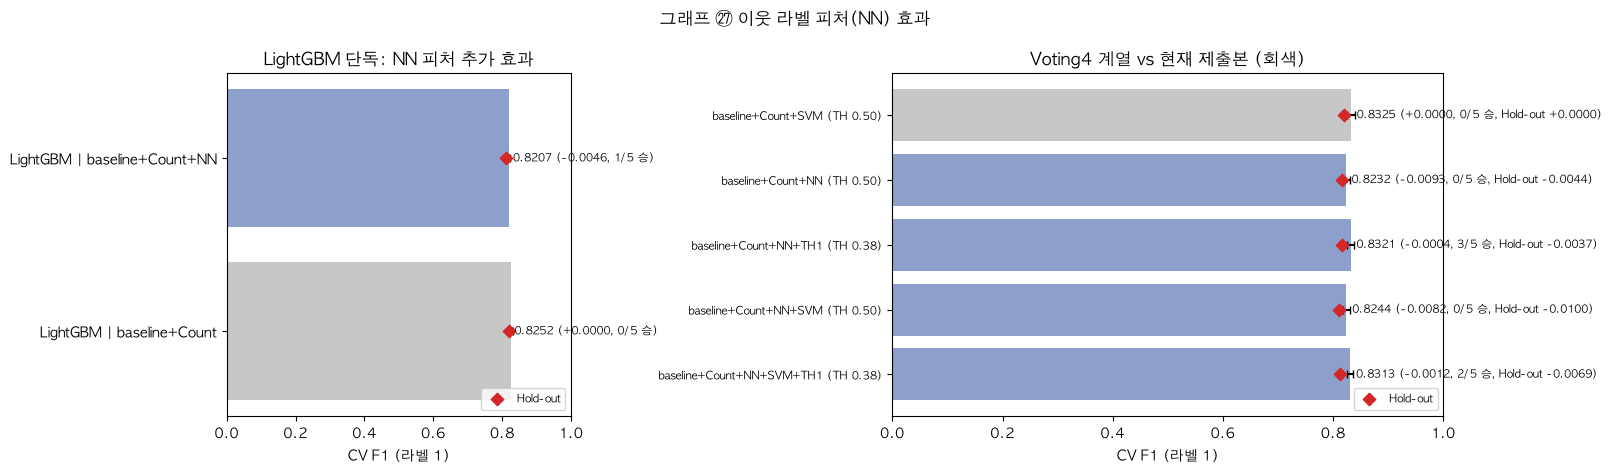

In [50]:
fig, ax = plt.subplots(1, 2, figsize=(16, 4.8), gridspec_kw={"width_ratios": [1, 1.6]})
sv = pd.DataFrame(screen_nn).T.reset_index().rename(columns={"index": "버전"})
base_s = sv.loc[0]
ax[0].barh(sv["버전"], sv["CV_F1_1"], xerr=sv["CV_std"].astype(float), capsize=3, color=["#c7c7c7", "#8da0cb"])
ax[0].scatter(sv["Holdout_F1_1"], sv["버전"], marker="D", s=40, color="#d62728", zorder=3, label="Hold-out")
for i, r in sv.iterrows():
    wins = (r["cv_scores"] > base_s["cv_scores"]).sum()
    ax[0].text(r["CV_F1_1"] + 0.01, i, f"{r['CV_F1_1']:.4f} ({r['CV_F1_1'] - base_s['CV_F1_1']:+.4f}, {wins}/5 승)", va="center", fontsize=8)
ax[0].set_xlim(0, 1); ax[0].set_xlabel("CV F1 (라벨 1)"); ax[0].legend(loc="lower right", fontsize=8)
ax[0].set_title("LightGBM 단독: NN 피처 추가 효과")

d = nnv.iloc[::-1].reset_index(drop=True)
colors = ["#c7c7c7" if v == cur_sub["version"] else ("#2ca02c" if ok else "#8da0cb") for v, ok in zip(d["version"], d["엄격 기준 통과"])]
pos = np.arange(len(d))
ax[1].barh(pos, d["CV_F1_1"], xerr=d["CV_F1_1_std"], capsize=3, color=colors)
ax[1].scatter(d["Holdout_F1_1"], pos, marker="D", s=40, color="#d62728", zorder=3, label="Hold-out")
for p_, r in d.iterrows():
    ax[1].text(r["CV_F1_1"] + 0.01, p_, f"{r['CV_F1_1']:.4f} ({r['현재 대비']:+.4f}, {r['이긴 fold']}/5 승, Hold-out {r['Hold-out 대비']:+.4f})",
               va="center", fontsize=8)
ax[1].set_yticks(pos, [f"{v} (TH {th:.2f})" for v, th in zip(d["version"], d["TH"])], fontsize=8)
ax[1].set_xlim(0, 1); ax[1].set_xlabel("CV F1 (라벨 1)"); ax[1].legend(loc="lower right", fontsize=8)
ax[1].set_title("Voting4 계열 vs 현재 제출본 (회색)")
plt.suptitle("그래프 ㉗ 이웃 라벨 피처(NN) 효과"); plt.tight_layout(); save_fig("27_이웃피처_효과"); plt.show()

#### 9-11-4. 반복 CV (5-fold × 5회 = 25개 fold)로 정밀 비교

- 후보: 9-11-3에서 **threshold 0.5 버전 중 CV 최고** (threshold를 고르지 않아 운이 덜 섞인 버전)
- 현재 제출본(Voting4 + SVM, 0.5)과 **같은 25개 fold에서 짝지어** 비교 (1회차는 기존 fold 재사용, 2~5회차는 seed만 바꿔 새로 분할)
- 통과 조건: **25개 중 20개 이상 승 (80%, 기존 4/5와 같은 비율)** + 평균 상승 + Hold-out 유지 이상
- 후보가 9-11-3에서 현재 제출본보다 CV가 낮으면 반복 CV는 건너뜁니다 (시간 절약)
- 예상 시간: 약 12~16분 (2~5회차 × 현재 제출본·후보 각각 학습)

In [51]:
cand = max([r for r in NNV if r is not cur_sub and r["TH"] == 0.5], key=lambda r: r["CV_F1_1"])
REP = None
if cand["CV_F1_1"] <= cur_sub["CV_F1_1"]:
    print(f"후보 {cand['version']} CV {cand['CV_F1_1']:.4f} ≤ 현재 제출본 {cur_sub['CV_F1_1']:.4f} → 반복 CV 생략")
else:
    with_svm = "SVM" in cand["version"]
    print(f"후보: {cand['version']} vs 현재 제출본: {cur_sub['version']}")
    diffs, rows = [], []
    for rep in range(5):
        t0 = time.time()
        if rep == 0:
            folds_r = FOLDS
        else:
            folds_r = list(StratifiedKFold(5, shuffle=True, random_state=SEED + rep).split(X_tr_idx, y_tr_))
        def fold_f1(p):
            return np.array([f1_1(y_tr_[va], np.where(p[va] >= 0.5, 1, 0)) for _, va in folds_r])
        # 현재 제출본: Voting4(NN 없음) + SVM
        if rep == 0:
            cur_oof = np.mean([P1[n][0] for n in list(SEARCH) + ["SVM"]], axis=0)
            cand_oof = np.mean([V_NN[0]] * 4 + [P1["SVM"][0]], axis=0) if with_svm else V_NN[0]
        else:
            v_old, _, _ = oof_te_pr(make_voting4, FEATS_C, False, folds=folds_r, test_rows=None, full=False)
            s_old, _, _ = oof_te_pr(lambda: TanimotoSVC(TAN_COLS, C=2.0), TAN_COLS, False, folds=folds_r, test_rows=None, full=False)
            v_nn, _, _ = oof_te_pr(make_voting4, FEATS_C, True, folds=folds_r, test_rows=None, full=False)
            cur_oof = (4 * v_old + s_old) / 5
            cand_oof = (4 * v_nn + s_old) / 5 if with_svm else v_nn
        fc, fn = fold_f1(cur_oof), fold_f1(cand_oof)
        diffs.append(fn - fc)
        rows += [{"회차": rep + 1, "fold": k + 1, "현재 제출본": a_, "후보": b_, "차이": b_ - a_} for k, (a_, b_) in enumerate(zip(fc, fn))]
        print(f"  {rep+1}회차: 후보 승 {(fn > fc).sum()}/5 | 평균 차이 {np.mean(fn - fc):+.4f} | {time.time()-t0:.0f}s")
    REP = pd.DataFrame(rows)
    wins25 = int((REP["차이"] > 0).sum())
    pass_rep = wins25 >= 20 and REP["차이"].mean() > 0 and cand["Hold-out 대비"] >= 0
    print(f"→ 25개 fold 중 후보 승 {wins25}개 | 평균 차이 {REP['차이'].mean():+.4f} | Hold-out 대비 {cand['Hold-out 대비']:+.4f} "
          f"→ {'통과' if pass_rep else '미통과'}")
    REP.to_csv(f"{OUT_DIR}/반복CV_비교.csv", index=False, encoding="utf-8-sig")

후보 baseline+Count+NN+SVM CV 0.8244 ≤ 현재 제출본 0.8325 → 반복 CV 생략


#### 그래프 ㉘ 반복 CV 25개 fold – 후보와 현재 제출본의 차이

점 하나 = fold 하나에서 (후보 F1(1) - 현재 제출본 F1(1)). **0보다 오른쪽이 많을수록** 후보가 일관되게 낫다는 뜻입니다.
(차이 그래프라 0을 중심으로 그립니다.)

In [52]:
if REP is None:
    print("반복 CV를 생략해 그래프 없음")
else:
    fig, ax = plt.subplots(figsize=(10, 4))
    for rep, g in REP.groupby("회차"):
        ax.scatter(g["차이"], np.full(len(g), rep), s=40, color=np.where(g["차이"] > 0, "#2ca02c", "#d62728"), zorder=3)
    ax.axvline(0, color="k", lw=0.8); ax.axvline(REP["차이"].mean(), color="#1f77b4", ls="--", lw=1.5,
                                                  label=f"평균 {REP['차이'].mean():+.4f}")
    lim = max(abs(REP["차이"]).max() * 1.2, 0.01); ax.set_xlim(-lim, lim)
    ax.set_yticks(range(1, 6), [f"{i}회차" for i in range(1, 6)]); ax.invert_yaxis()
    ax.set_xlabel("fold별 F1(1) 차이 (후보 - 현재 제출본)"); ax.legend(loc="lower right")
    ax.set_title(f"그래프 ㉘ 반복 CV: {cand['version']} vs 현재 제출본 – 25개 중 {int((REP['차이'] > 0).sum())}개 승 (초록 = 후보 승)")
    plt.tight_layout(); save_fig("28_반복CV_25fold_차이"); plt.show()

# --- 최종 교체 판단 ---
strict = [r for r in NNV if r.get("엄격 기준 통과")]
if strict:
    win = max(strict, key=lambda r: r["CV_F1_1"]); why = "기존 엄격 기준 통과"
elif REP is not None and pass_rep:
    win = cand; why = "반복 CV 기준 통과 (25개 중 20개 이상 승)"
else:
    win = None
if win:
    shutil.copy(f"{OUT_DIR}/{win['file']}", SUBMIT_PATH)
    print(f"교체: {win['version']} ({why}) → {SUBMIT_PATH}")
else:
    print(f"두 기준 모두 미통과 → {SUBMIT_PATH} 는 현재 제출본({cur_sub['version']}) 유지")

반복 CV를 생략해 그래프 없음
두 기준 모두 미통과 → predict_output_김정인.csv 는 현재 제출본(baseline+Count+SVM) 유지


### 9-12. SVM 강화 + seed 평균

지금까지는 "새 정보"를 넣으려다 실패했습니다. 이번에는 방향을 바꿔 **모델을 더 정확하고 덜 흔들리게** 만듭니다.

**① SVM 강화**
- 9-8에서 SVM은 C를 키울수록 계속 좋아졌고(0.786 → 0.803 → 0.811) 후보 끝(C=2)에서 멈춤 → **C = 2, 4, 8, 16**
- 유사도 2종: 기존 **Tanimoto(0/1 지문)** + **MinMax(Count 지문, 등장 횟수까지 반영)**
- 8개 설정 중 CV 최고를 고르고, 운이 섞였는지 **Nested 선택**으로 확인

**② seed 평균**
- Voting4를 random seed만 바꿔 **3번 학습(42, 43, 44)** 하고 확률 평균 → 트리의 흔들림이 줄어 **모든 fold에서 고르게** 좋아지는 효과 기대
- seed 42 결과는 9-3에서 저장한 것을 재사용, 43·44만 새로 학습

**후보** (모두 threshold 0.5, 현재 제출본과 같은 가중 = (Voting4 × 4 + SVM) / 5)

| 후보 | 트리 | SVM |
|---|---|---|
| A | seed 3개 평균 | 기존 (Tanimoto, C=2) |
| B | seed 3개 평균 | 강화된 SVM |
| C | 기존 (seed 42) | 강화된 SVM |

**교체 기준**: 현재 제출본(`baseline+Count+SVM`) 대비 CV F1(1) 상승 + 4/5 fold 이상 승 + Hold-out 유지 이상
예상 시간: SVM 약 2분 + seed 평균 약 7분

In [53]:
C_COLS = [f"c_{c}" for c in ECFPC] + [f"c_{c}" for c in FCFPC]      # Count 지문 (9-1에서 계산)

class SimSVC(BaseEstimator, ClassifierMixin):
    """kind='tanimoto': 0/1 지문 Tanimoto / kind='minmax': Count 지문 MinMax (횟수 4 이상은 4로 자름)"""
    def __init__(self, cols=None, C=1.0, kind="tanimoto"):
        self.cols, self.C, self.kind = cols, C, kind
    def _rep(self, X):
        A = np.asarray(X[self.cols], dtype=np.float32)
        if self.kind == "minmax":                       # 횟수를 계단식 0/1로 펼치면 Tanimoto = MinMax
            A = np.concatenate([(A > k) for k in range(4)], axis=1).astype(np.float32)
        return A
    def fit(self, X, y):
        self.R_ = self._rep(X)
        self.svc_ = SVC(kernel="precomputed", C=self.C, probability=True, random_state=SEED).fit(tanimoto(self.R_, self.R_), y)
        self.classes_ = self.svc_.classes_
        return self
    def predict_proba(self, X):
        return self.svc_.predict_proba(tanimoto(self._rep(X), self.R_))
    def predict(self, X):
        return self.classes_[self.predict_proba(X).argmax(1)]

SVM_CFG = [(kind, c) for kind in ("tanimoto", "minmax") for c in (2, 4, 8, 16)]
svm_rows, SVM_OOF = [], {}
for kind, c in SVM_CFG:
    t0 = time.time(); cols = TAN_COLS if kind == "tanimoto" else C_COLS
    o, _, _ = oof_te_pr(lambda: SimSVC(cols, C=c, kind=kind), cols, False, test_rows=None, full=False)
    cv = folds_f1_1(np.where(o >= 0.5, 1, 0))
    SVM_OOF[(kind, c)] = (o, cv)
    svm_rows.append({"유사도": kind, "C": c, "CV_F1_1": cv.mean(), "CV_std": cv.std(), "cv_scores": cv})
    print(f"[SVM {kind:8s} C={c:2d}] CV F1(1) {cv.mean():.4f} ± {cv.std():.4f} | {time.time()-t0:.0f}s")
svm_df = pd.DataFrame(svm_rows)

# Nested 선택: 4개 fold로 고르고 남은 1개로 채점
FM = np.vstack(svm_df["cv_scores"].values)
nested_svm = [FM[FM[:, [j for j in range(5) if j != k]].mean(1).argmax(), k] for k in range(5)]
picks = [svm_df.loc[FM[:, [j for j in range(5) if j != k]].mean(1).argmax(), ["유사도", "C"]].tolist() for k in range(5)]
best_i = svm_df["CV_F1_1"].idxmax()
SVM_BEST = (svm_df.loc[best_i, "유사도"], int(svm_df.loc[best_i, "C"]))
base_svm = svm_df[(svm_df["유사도"] == "tanimoto") & (svm_df["C"] == 2)].iloc[0]
print(f"\n최고 SVM: {SVM_BEST} CV {svm_df.loc[best_i, 'CV_F1_1']:.4f} (기존 tanimoto C=2: {base_svm['CV_F1_1']:.4f})")
print(f"Nested 선택 점수 {np.mean(nested_svm):.4f} vs 기존 SVM {base_svm['CV_F1_1']:.4f} | 5번 선택: {picks}")

# 최고 SVM의 Hold-out / 전체 학습 확률
kind, c = SVM_BEST; cols = TAN_COLS if kind == "tanimoto" else C_COLS
SVM2 = oof_te_pr(lambda: SimSVC(cols, C=c, kind=kind), cols, False)
svm_df.drop(columns="cv_scores").round(4)

[SVM tanimoto C= 2] CV F1(1) 0.8111 ± 0.0092 | 4s
[SVM tanimoto C= 4] CV F1(1) 0.8164 ± 0.0078 | 5s
[SVM tanimoto C= 8] CV F1(1) 0.8138 ± 0.0095 | 5s
[SVM tanimoto C=16] CV F1(1) 0.8107 ± 0.0071 | 5s
[SVM minmax   C= 2] CV F1(1) 0.8172 ± 0.0089 | 5s
[SVM minmax   C= 4] CV F1(1) 0.8217 ± 0.0059 | 6s
[SVM minmax   C= 8] CV F1(1) 0.8218 ± 0.0096 | 6s
[SVM minmax   C=16] CV F1(1) 0.8188 ± 0.0088 | 6s

최고 SVM: ('minmax', 8) CV 0.8218 (기존 tanimoto C=2: 0.8111)
Nested 선택 점수 0.8201 vs 기존 SVM 0.8111 | 5번 선택: [['minmax', np.int64(4)], ['minmax', np.int64(8)], ['minmax', np.int64(4)], ['minmax', np.int64(4)], ['minmax', np.int64(8)]]


,유사도,C,CV_F1_1,CV_std
0,tanimoto,2,0.8111,0.0092
1,tanimoto,4,0.8164,0.0078
2,tanimoto,8,0.8138,0.0095
3,tanimoto,16,0.8107,0.0071
4,minmax,2,0.8172,0.0089
5,minmax,4,0.8217,0.0059
6,minmax,8,0.8218,0.0096
7,minmax,16,0.8188,0.0088


#### 그래프 ㉙ SVM 설정별 성능

x축 0~1 전체. 숫자 = CV F1(1) (괄호 = 기존 SVM(Tanimoto, C=2) 대비). 회색 = 기존, 초록 = 선택.

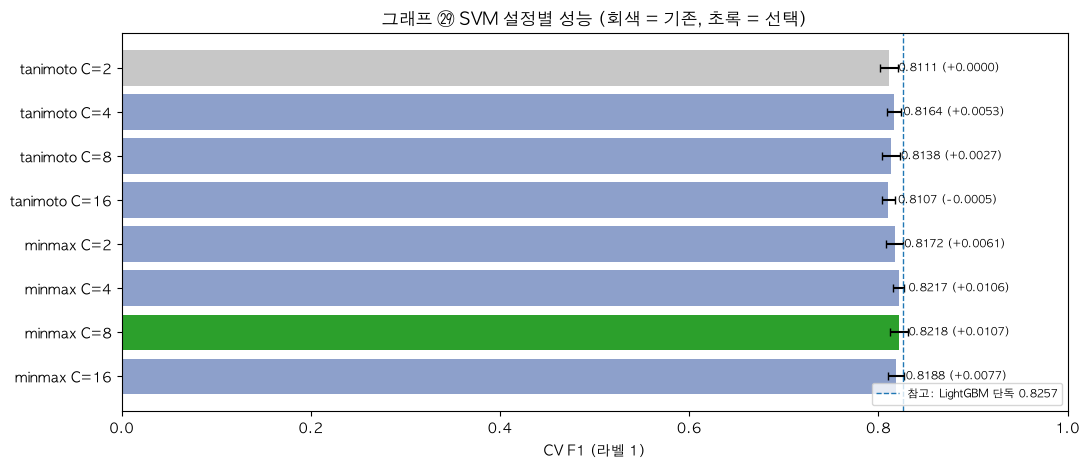

In [54]:
d = svm_df.iloc[::-1].reset_index(drop=True)
labels = [f"{k} C={c}" for k, c in zip(d["유사도"], d["C"])]
colors = ["#2ca02c" if (k, c) == SVM_BEST else ("#c7c7c7" if (k, c) == ("tanimoto", 2) else "#8da0cb")
          for k, c in zip(d["유사도"], d["C"])]
fig, ax = plt.subplots(figsize=(11, 4.8))
ax.barh(labels, d["CV_F1_1"], xerr=d["CV_std"], capsize=3, color=colors)
for i, v in enumerate(d["CV_F1_1"]):
    ax.text(v + 0.01, i, f"{v:.4f} ({v - base_svm['CV_F1_1']:+.4f})", va="center", fontsize=8)
ax.axvline(0.8257, color="#1f77b4", ls="--", lw=1, label="참고: LightGBM 단독 0.8257")
ax.set_xlim(0, 1); ax.set_xlabel("CV F1 (라벨 1)"); ax.legend(loc="lower right", fontsize=8)
ax.set_title("그래프 ㉙ SVM 설정별 성능 (회색 = 기존, 초록 = 선택)")
plt.tight_layout(); save_fig("29_SVM_설정별_성능"); plt.show()

#### 9-12-2. seed 평균 (seed 42 + 43 + 44) → 후보 A·B·C vs 현재 제출본

In [55]:
def params_with_seed(s):
    p = {}
    for n in SEARCH:
        q = dict(BEST_PARAMS[n])
        q["random_seed" if n == "CatBoost" else "random_state"] = s
        p[n] = q
    return p

SEED_RUNS = [OLD]                                          # seed 42: 9-3 저장 결과 (모델별 '독성 없음' 확률)
for s in (SEED + 1, SEED + 2):
    print(f"▶ seed {s} 학습")
    SEED_RUNS.append(member_p1(params_with_seed(s), FEATS_C))
V_SEED = tuple(np.mean([run[i] for run in SEED_RUNS], axis=0).mean(1) for i in range(3))   # seed 평균 Voting4
V_ONE = tuple(m.mean(1) for m in OLD)                                                      # seed 42 Voting4

CANDS = [cur_sub]
for vname, V, S in [("baseline+Count+SVM+Seed3", V_SEED, P1["SVM"]),
                    (f"baseline+Count+SVM[{SVM_BEST[0]},C={SVM_BEST[1]}]+Seed3", V_SEED, SVM2),
                    (f"baseline+Count+SVM[{SVM_BEST[0]},C={SVM_BEST[1]}]", V_ONE, SVM2)]:
    o, t, p = ((4 * v + s) / 5 for v, s in zip(V, S))
    CANDS.append(evaluate_probs(vname, o, t, p, 0.5))
for r in CANDS:
    r["현재 대비"] = r["CV_F1_1"] - cur_sub["CV_F1_1"]
    r["이긴 fold"] = int((r["cv_scores"] > cur_sub["cv_scores"]).sum())
    r["Hold-out 대비"] = r["Holdout_F1_1"] - cur_sub["Holdout_F1_1"]
    r["엄격 기준 통과"] = bool(r is not cur_sub and r["현재 대비"] > 0 and r["이긴 fold"] >= 4 and r["Hold-out 대비"] >= 0)
cands = pd.DataFrame(CANDS)
cands.drop(columns="cv_scores").to_csv(f"{OUT_DIR}/버전_기록_SVM강화_seed평균.csv", index=False, encoding="utf-8-sig")
cands.drop(columns=["cv_scores", "file"]).round(4)

▶ seed 43 학습
  fold 1/5 완료 (42s)
  fold 2/5 완료 (84s)
  fold 3/5 완료 (125s)
  fold 4/5 완료 (168s)
  fold 5/5 완료 (210s)
  Hold-out·전체 학습 완료 (307s)
▶ seed 44 학습
  fold 1/5 완료 (42s)
  fold 2/5 완료 (84s)
  fold 3/5 완료 (127s)
  fold 4/5 완료 (170s)
  fold 5/5 완료 (212s)
  Hold-out·전체 학습 완료 (309s)


,version,TH,CV_F1_1,CV_F1_1_std,CV_Acc,Holdout_F1_1,Holdout_Acc,Holdout_Precision_1,Holdout_Recall_1,pred_1_rate,현재 대비,이긴 fold,Hold-out 대비,교체 조건 충족,엄격 기준 통과
0,baseline+Count+SVM,0.5,0.8325,0.0074,0.8140,0.8200,0.7994,0.8015,0.8394,0.5556,0.0000,0,0.0000,False,False
1,baseline+Count+SVM+Seed3,0.5,0.8312,0.0068,0.8124,0.8193,0.7982,0.7992,0.8405,0.5556,-0.0013,2,-0.0007,NaN,False
2,"baseline+Count+SVM[minmax,C=8]+Seed3",0.5,0.8304,0.0082,0.8118,0.8217,0.8012,0.8027,0.8416,0.5512,-0.0021,2,0.0017,NaN,False
3,"baseline+Count+SVM[minmax,C=8]",0.5,0.8300,0.0089,0.8115,0.8204,0.8000,0.8023,0.8394,0.5502,-0.0025,1,0.0004,NaN,False


#### 그래프 ㉚ 후보 vs 현재 제출본 – F1(1)과 Accuracy

x축 0~1 전체. 막대 = CV, ◆ = Hold-out, 숫자 = CV 값 (괄호 = 현재 제출본 대비, 이긴 fold 수). 회색 = 현재 제출본, 초록 = 엄격 기준 통과.

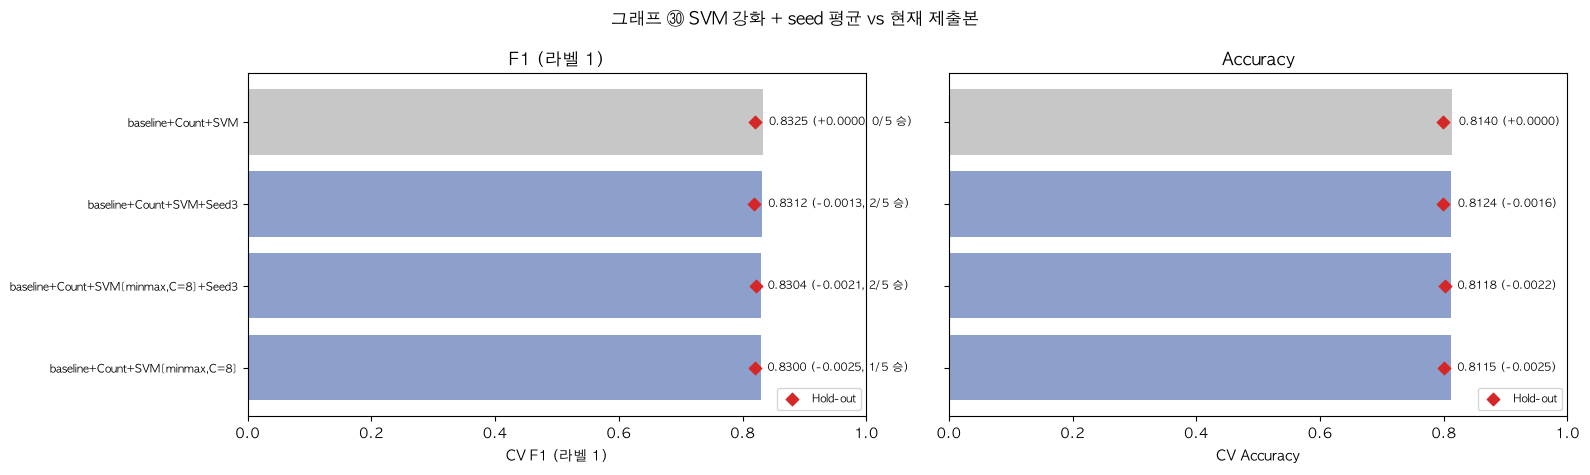

엄격 기준 통과 없음 → predict_output_김정인.csv 는 현재 제출본(baseline+Count+SVM) 유지


In [56]:
d = cands.iloc[::-1].reset_index(drop=True)
colors = ["#c7c7c7" if v == cur_sub["version"] else ("#2ca02c" if ok else "#8da0cb") for v, ok in zip(d["version"], d["엄격 기준 통과"])]
fig, ax = plt.subplots(1, 2, figsize=(16, 0.7 * len(d) + 2), sharey=True)
pos = np.arange(len(d))
for a, cv_col, ho_col, title in [(ax[0], "CV_F1_1", "Holdout_F1_1", "F1 (라벨 1)"), (ax[1], "CV_Acc", "Holdout_Acc", "Accuracy")]:
    a.barh(pos, d[cv_col], color=colors)
    a.scatter(d[ho_col], pos, marker="D", s=40, color="#d62728", zorder=3, label="Hold-out")
    for p_, r in d.iterrows():
        extra = f", {r['이긴 fold']}/5 승" if cv_col == "CV_F1_1" else ""
        a.text(r[cv_col] + 0.01, p_, f"{r[cv_col]:.4f} ({r[cv_col] - cur_sub[cv_col]:+.4f}{extra})", va="center", fontsize=8)
    a.set_xlim(0, 1); a.set_title(title); a.set_xlabel(f"CV {title}"); a.legend(loc="lower right", fontsize=8)
ax[0].set_yticks(pos, d["version"], fontsize=8)
plt.suptitle("그래프 ㉚ SVM 강화 + seed 평균 vs 현재 제출본"); plt.tight_layout(); save_fig("30_SVM강화_seed평균_비교"); plt.show()

ok = cands[cands["엄격 기준 통과"]].sort_values("CV_F1_1", ascending=False)
if len(ok):
    win = ok.iloc[0]
    shutil.copy(f"{OUT_DIR}/{win['file']}", SUBMIT_PATH)
    print(f"교체: {win['version']} (CV {win['현재 대비']:+.4f}, {win['이긴 fold']}/5 승, Hold-out {win['Hold-out 대비']:+.4f}) → {SUBMIT_PATH}")
else:
    print(f"엄격 기준 통과 없음 → {SUBMIT_PATH} 는 현재 제출본({cur_sub['version']}) 유지")

## 10. 제출 기록 (리더보드와 비교)

| 제출 | 시각 | SUBMIT_MODEL | CV F1(0) | Hold-out F1(0) | 리더보드 F1 |
|---|---|---|---|---|---|
| 1 | | | | | |
| 2 | | | | | |
| 3 | | | | | |
| 4 | | | | | |

- CV가 오른 만큼 리더보드도 오르면 CV를 믿고 다음 실험을 고릅니다. 반대로 움직이면 과적합 신호로 보고 더 단순한 모델을 택합니다.